In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Cirugía Cardiovascular.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 9 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=150.0, y1=114.7
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 374
Page 1, Q1, A: Yellow percentage: 0.0%


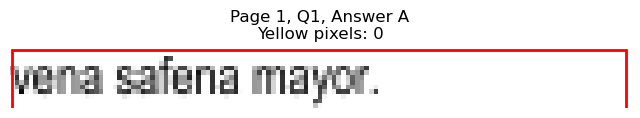

Page 1, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=123.5, y1=127.3
Page 1, Q1, B: Yellow pixels: 106
Page 1, Q1, B: Total non-white pixels: 356
Page 1, Q1, B: Yellow percentage: 29.8%


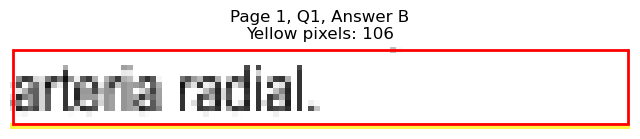

Page 1, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=206.2, y1=139.9
Page 1, Q1, C: Yellow pixels: 1902
Page 1, Q1, C: Total non-white pixels: 2457
Page 1, Q1, C: Yellow percentage: 77.4%


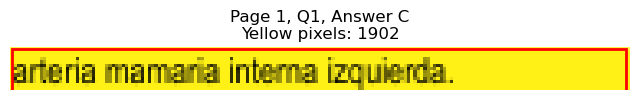

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=409.9, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 380
Page 1, Q1, D: Yellow percentage: 0.0%


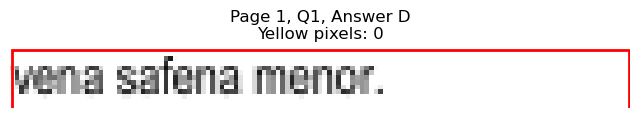

Page 1, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=420.9, y1=127.3
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 514
Page 1, Q1, E: Yellow percentage: 0.0%


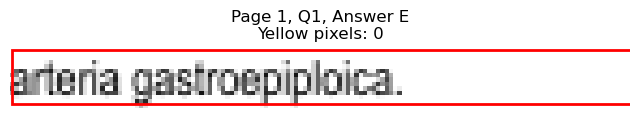


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=190.7, y1=177.8
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 623
Page 1, Q2, A: Yellow percentage: 0.0%


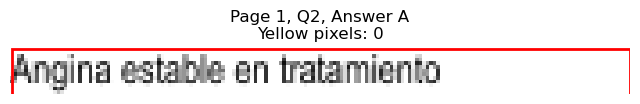

Page 1, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=237.2, y1=190.4
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 808
Page 1, Q2, B: Yellow percentage: 0.0%


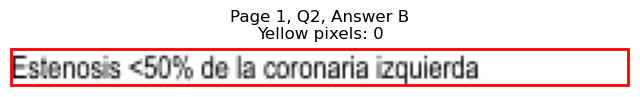

Page 1, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=178.6, y1=203.0
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 524
Page 1, Q2, C: Yellow percentage: 0.0%


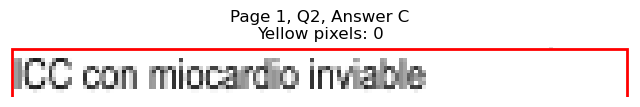

Page 1, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=464.5, y1=177.8
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 868
Page 1, Q2, D: Yellow percentage: 0.0%


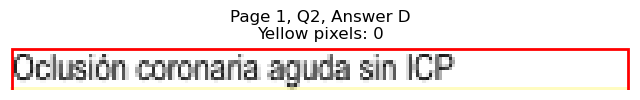

Page 1, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=408.3, y1=190.4
Page 1, Q2, E: Yellow pixels: 1247
Page 1, Q2, E: Total non-white pixels: 1848
Page 1, Q2, E: Yellow percentage: 67.5%


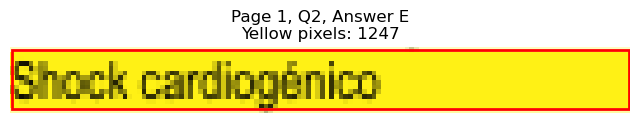


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=217.7, y1=240.9
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 952
Page 1, Q3, A: Yellow percentage: 0.0%


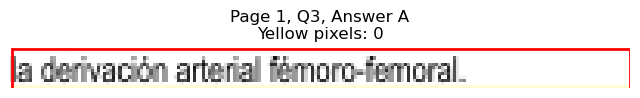

Page 1, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=260.8, y1=253.5
Page 1, Q3, B: Yellow pixels: 2015
Page 1, Q3, B: Total non-white pixels: 2996
Page 1, Q3, B: Yellow percentage: 67.3%


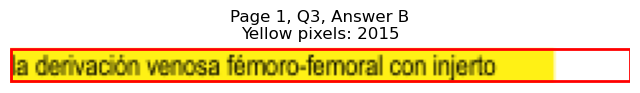

Page 1, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=221.3, y1=278.7
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 939
Page 1, Q3, C: Yellow percentage: 0.0%


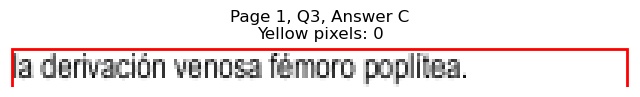

Page 1, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=478.5, y1=240.9
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 761
Page 1, Q3, D: Yellow percentage: 0.0%


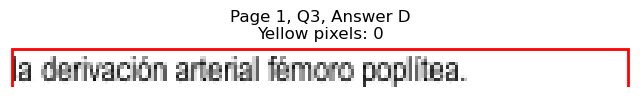

Page 1, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=466.0, y1=253.5
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 703
Page 1, Q3, E: Yellow percentage: 0.0%


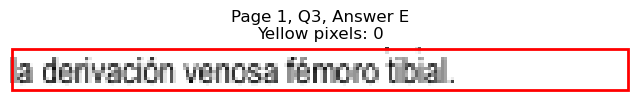


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=186.6, y1=341.9
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 622
Page 1, Q4, A: Yellow percentage: 0.0%


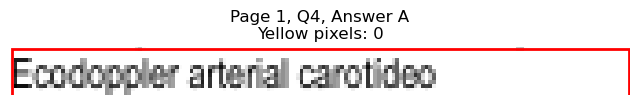

Page 1, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=135.0, y1=354.6
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 338
Page 1, Q4, B: Yellow percentage: 0.0%


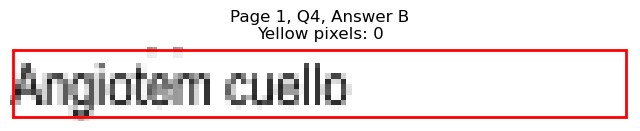

Page 1, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=161.1, y1=367.2
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 473
Page 1, Q4, C: Yellow percentage: 0.0%


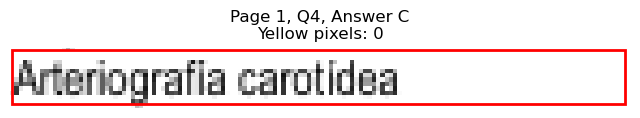

Page 1, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=426.3, y1=341.9
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 491
Page 1, Q4, D: Yellow percentage: 0.0%


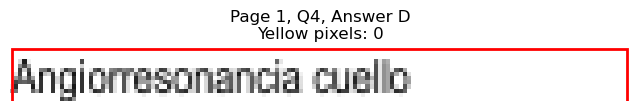

Page 1, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=495.6, y1=354.6
Page 1, Q4, E: Yellow pixels: 2063
Page 1, Q4, E: Total non-white pixels: 2995
Page 1, Q4, E: Yellow percentage: 68.9%


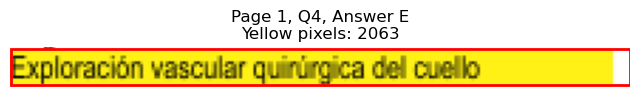


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=161.7, y1=417.6
Page 1, Q5, A: Yellow pixels: 1522
Page 1, Q5, A: Total non-white pixels: 2016
Page 1, Q5, A: Yellow percentage: 75.5%


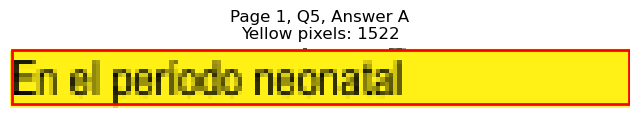

Page 1, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=127.6, y1=430.3
Page 1, Q5, B: Yellow pixels: 110
Page 1, Q5, B: Total non-white pixels: 374
Page 1, Q5, B: Yellow percentage: 29.4%


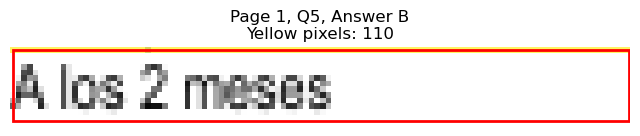

Page 1, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=123.5, y1=442.9
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 257
Page 1, Q5, C: Yellow percentage: 0.0%


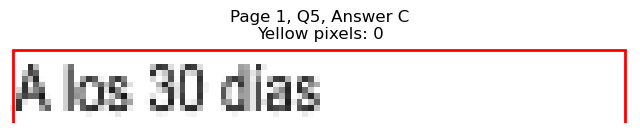

Page 1, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=422.8, y1=417.6
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 459
Page 1, Q5, D: Yellow percentage: 0.0%


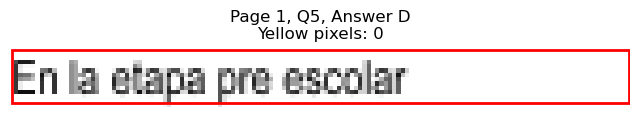

Page 1, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=355.1, y1=430.3
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 131
Page 1, Q5, E: Yellow percentage: 0.0%


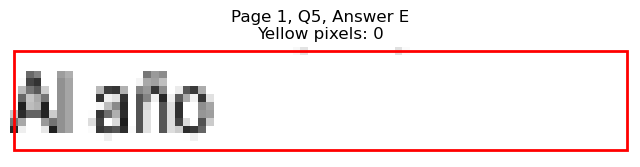


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=97.9, y1=480.7
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 125
Page 1, Q6, A: Yellow percentage: 0.0%


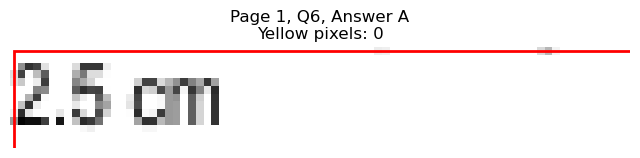

Page 1, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=97.9, y1=493.4
Page 1, Q6, B: Yellow pixels: 80
Page 1, Q6, B: Total non-white pixels: 204
Page 1, Q6, B: Yellow percentage: 39.2%


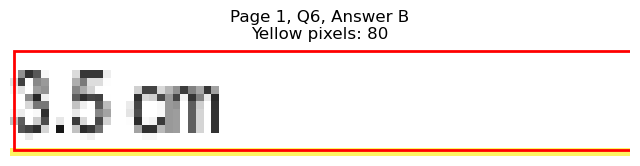

Page 1, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=98.4, y1=506.0
Page 1, Q6, C: Yellow pixels: 961
Page 1, Q6, C: Total non-white pixels: 1053
Page 1, Q6, C: Yellow percentage: 91.3%


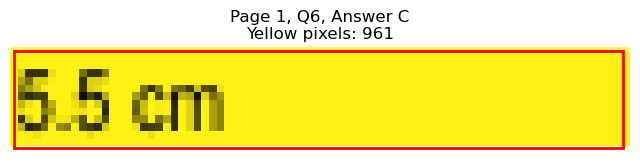

Page 1, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=349.6, y1=480.7
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 85
Page 1, Q6, D: Yellow percentage: 0.0%


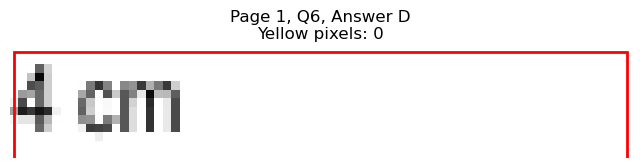

Page 1, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=349.1, y1=493.4
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 82
Page 1, Q6, E: Yellow percentage: 0.0%


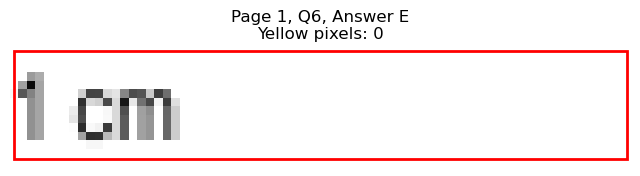


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=203.7, y1=543.8
Page 1, Q7, A: Yellow pixels: 1898
Page 1, Q7, A: Total non-white pixels: 2418
Page 1, Q7, A: Yellow percentage: 78.5%


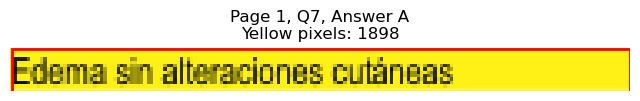

Page 1, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=137.1, y1=556.4
Page 1, Q7, B: Yellow pixels: 120
Page 1, Q7, B: Total non-white pixels: 463
Page 1, Q7, B: Yellow percentage: 25.9%


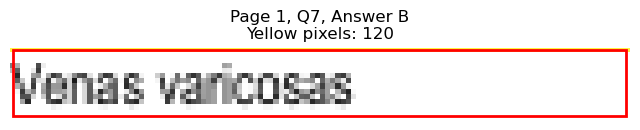

Page 1, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=255.9, y1=569.2
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 991
Page 1, Q7, C: Yellow percentage: 0.0%


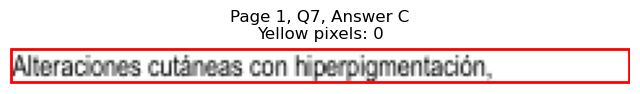

Page 1, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=520.2, y1=543.8
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 972
Page 1, Q7, D: Yellow percentage: 0.0%


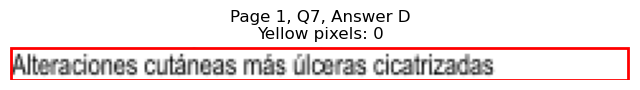

Page 1, Q7 - E: Detected box: x0=327.0, y0=543.8, x1=500.1, y1=556.4
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 887
Page 1, Q7, E: Yellow percentage: 0.0%


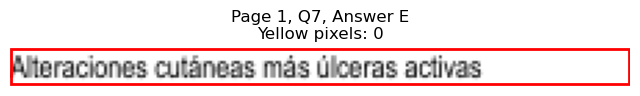


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=194.7, y1=632.3
Page 1, Q8, A: Yellow pixels: 1616
Page 1, Q8, A: Total non-white pixels: 2478
Page 1, Q8, A: Yellow percentage: 65.2%


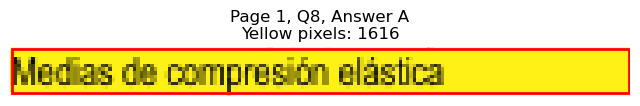

Page 1, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=225.8, y1=644.9
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 995
Page 1, Q8, B: Yellow percentage: 0.0%


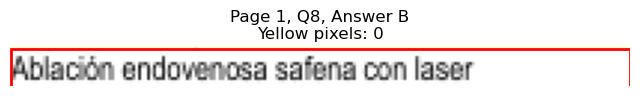

Page 1, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=238.8, y1=657.5
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 855
Page 1, Q8, C: Yellow percentage: 0.0%


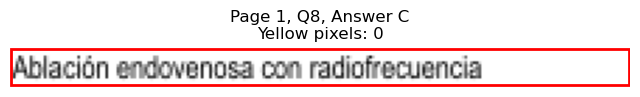

Page 1, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=460.0, y1=632.3
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 642
Page 1, Q8, D: Yellow percentage: 0.0%


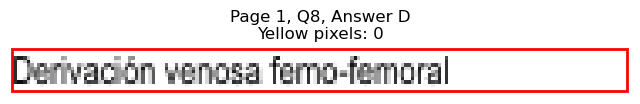

Page 1, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=461.6, y1=644.9
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 689
Page 1, Q8, E: Yellow percentage: 0.0%


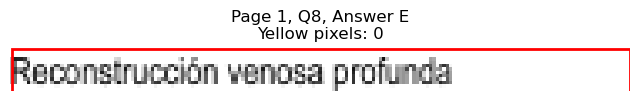


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=275.0, y1=708.0
Page 1, Q9, A: Yellow pixels: 2594
Page 1, Q9, A: Total non-white pixels: 3343
Page 1, Q9, A: Yellow percentage: 77.6%


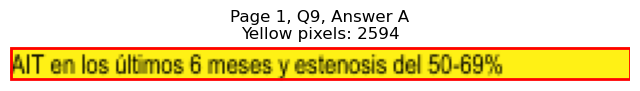

Page 1, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=298.7, y1=720.6
Page 1, Q9, B: Yellow pixels: 279
Page 1, Q9, B: Total non-white pixels: 1368
Page 1, Q9, B: Yellow percentage: 20.4%


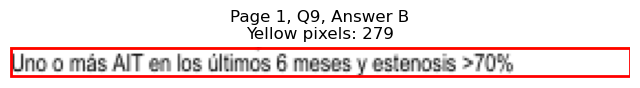

Page 1, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=168.9, y1=733.2
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 485
Page 1, Q9, C: Yellow percentage: 0.0%


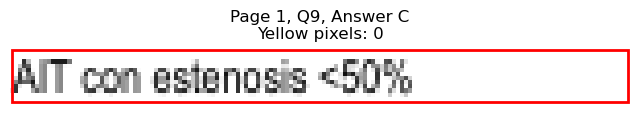

Page 1, Q9 - D: Detected box: x0=68.8, y0=733.2, x1=193.0, y1=745.8
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 600
Page 1, Q9, D: Yellow percentage: 0.0%


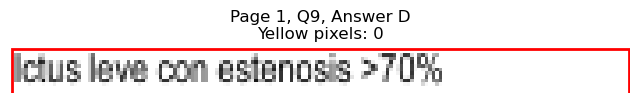

Page 1, Q9 - E: Detected box: x0=68.3, y0=745.8, x1=192.5, y1=758.4
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 595
Page 1, Q9, E: Yellow percentage: 0.0%


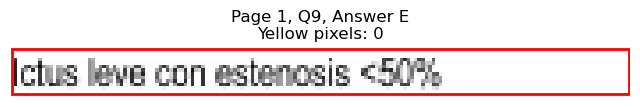


Page 1, Q9 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 10 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=156.0, y1=102.1
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 457
Page 2, Q1, A: Yellow percentage: 0.0%


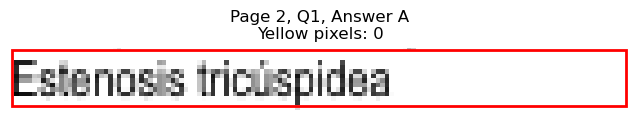

Page 2, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=145.0, y1=114.7
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 364
Page 2, Q1, B: Yellow percentage: 0.0%


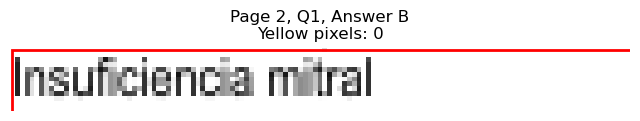

Page 2, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=135.0, y1=127.3
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 320
Page 2, Q1, C: Yellow percentage: 0.0%


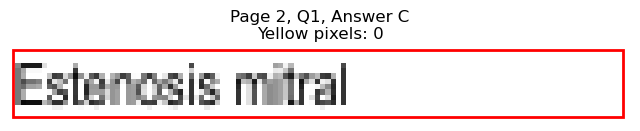

Page 2, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=425.8, y1=102.1
Page 2, Q1, D: Yellow pixels: 1533
Page 2, Q1, D: Total non-white pixels: 2086
Page 2, Q1, D: Yellow percentage: 73.5%


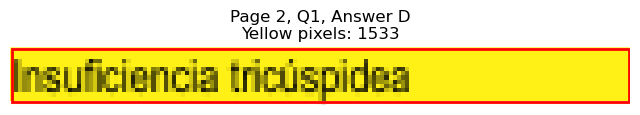

Page 2, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=408.8, y1=114.7
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 546
Page 2, Q1, E: Yellow percentage: 0.0%


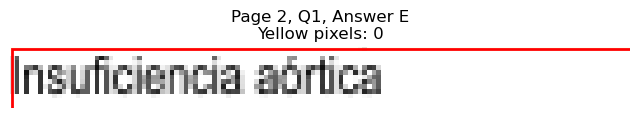


Page 2, Q1 - Selected Answer: D (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=230.8, y1=190.4
Page 2, Q2, A: Yellow pixels: 1900
Page 2, Q2, A: Total non-white pixels: 2982
Page 2, Q2, A: Yellow percentage: 63.7%


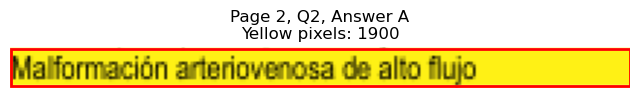

Page 2, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=156.6, y1=203.0
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 581
Page 2, Q2, B: Yellow percentage: 0.0%


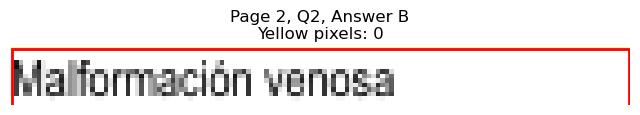

Page 2, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=158.5, y1=215.6
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 463
Page 2, Q2, C: Yellow percentage: 0.0%


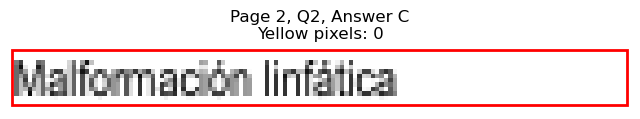

Page 2, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=413.3, y1=190.4
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 448
Page 2, Q2, D: Yellow percentage: 0.0%


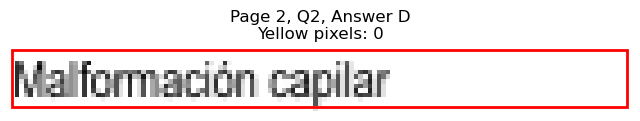

Page 2, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=391.7, y1=203.0
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 294
Page 2, Q2, E: Yellow percentage: 0.0%


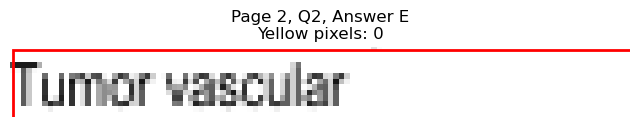


Page 2, Q2 - Selected Answer: A (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=132.0, y1=253.5
Page 2, Q3, A: Yellow pixels: 1278
Page 2, Q3, A: Total non-white pixels: 1610
Page 2, Q3, A: Yellow percentage: 79.4%


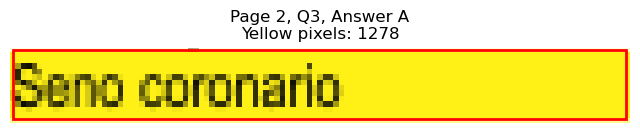

Page 2, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=141.5, y1=266.1
Page 2, Q3, B: Yellow pixels: 124
Page 2, Q3, B: Total non-white pixels: 470
Page 2, Q3, B: Yellow percentage: 26.4%


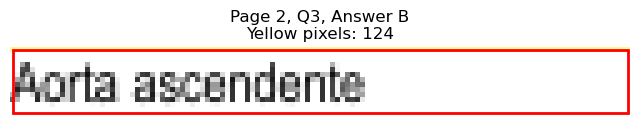

Page 2, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=138.0, y1=278.7
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 340
Page 2, Q3, C: Yellow percentage: 0.0%


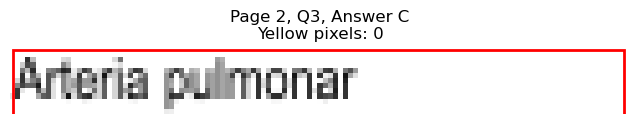

Page 2, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=426.3, y1=253.5
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 486
Page 2, Q3, D: Yellow percentage: 0.0%


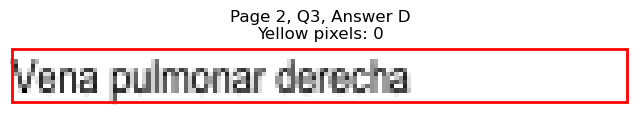

Page 2, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=399.8, y1=266.1
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 360
Page 2, Q3, E: Yellow percentage: 0.0%


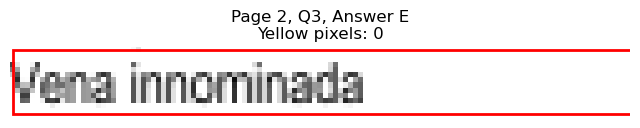


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=113.4, y1=316.7
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 230
Page 2, Q4, A: Yellow percentage: 0.0%


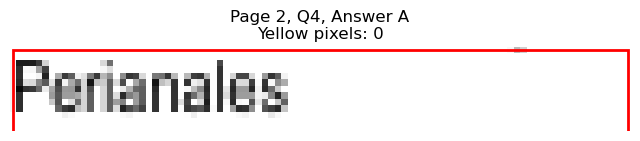

Page 2, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=140.1, y1=329.3
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 370
Page 2, Q4, B: Yellow percentage: 0.0%


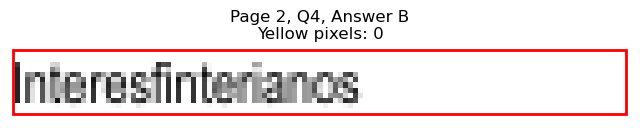

Page 2, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=145.5, y1=341.9
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 385
Page 2, Q4, C: Yellow percentage: 0.0%


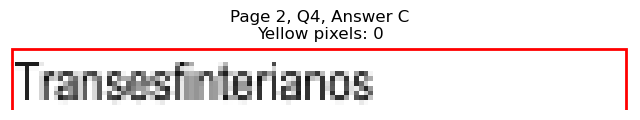

Page 2, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=388.7, y1=316.7
Page 2, Q4, D: Yellow pixels: 1220
Page 2, Q4, D: Total non-white pixels: 1456
Page 2, Q4, D: Yellow percentage: 83.8%


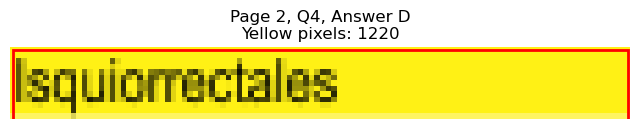

Page 2, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=397.7, y1=329.3
Page 2, Q4, E: Yellow pixels: 121
Page 2, Q4, E: Total non-white pixels: 501
Page 2, Q4, E: Yellow percentage: 24.2%


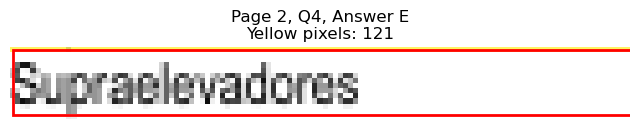


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=92.4, y1=379.8
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 118
Page 2, Q5, A: Yellow percentage: 0.0%


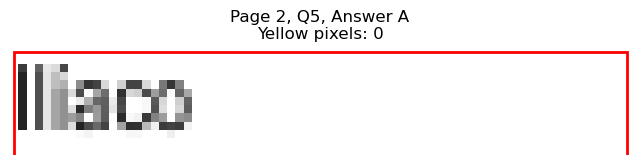

Page 2, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=103.9, y1=392.4
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 155
Page 2, Q5, B: Yellow percentage: 0.0%


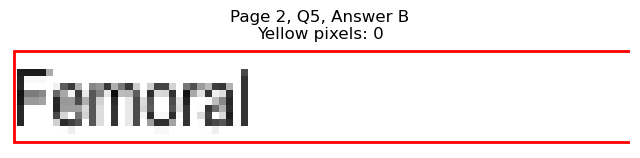

Page 2, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=94.3, y1=405.0
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 132
Page 2, Q5, C: Yellow percentage: 0.0%


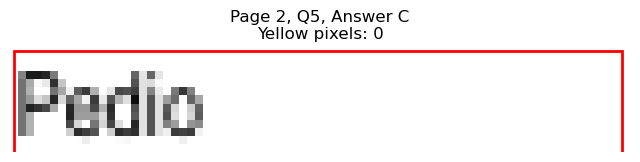

Page 2, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=351.7, y1=379.8
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 205
Page 2, Q5, D: Yellow percentage: 0.0%


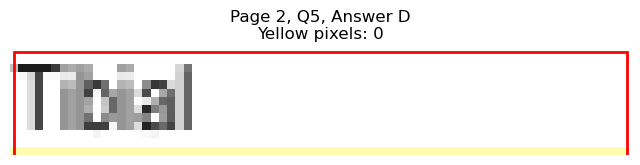

Page 2, Q5 - E: Detected box: x0=327.0, y0=379.7, x1=362.7, y1=392.4
Page 2, Q5, E: Yellow pixels: 873
Page 2, Q5, E: Total non-white pixels: 1204
Page 2, Q5, E: Yellow percentage: 72.5%


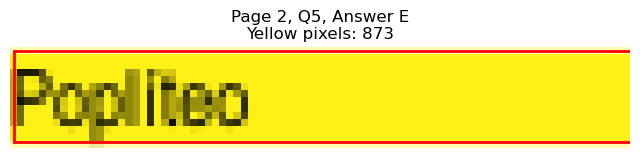


Page 2, Q5 - Selected Answer: E (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=245.1, y1=455.5
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 878
Page 2, Q6, A: Yellow percentage: 0.0%


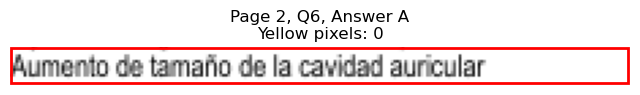

Page 2, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=203.7, y1=480.7
Page 2, Q6, B: Yellow pixels: 1900
Page 2, Q6, B: Total non-white pixels: 2418
Page 2, Q6, B: Yellow percentage: 78.6%


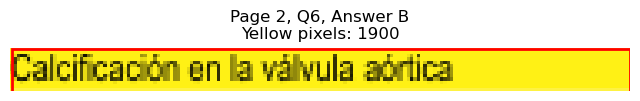

Page 2, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=169.1, y1=493.4
Page 2, Q6, C: Yellow pixels: 152
Page 2, Q6, C: Total non-white pixels: 668
Page 2, Q6, C: Yellow percentage: 22.8%


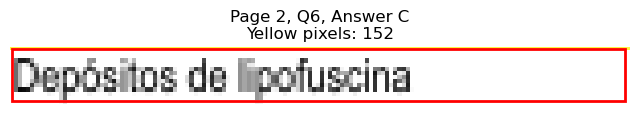

Page 2, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=498.1, y1=455.5
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 849
Page 2, Q6, D: Yellow percentage: 0.0%


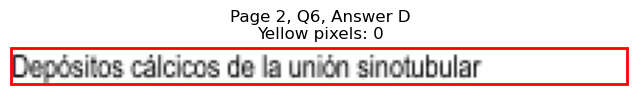

Page 2, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=427.4, y1=468.1
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 533
Page 2, Q6, E: Yellow percentage: 0.0%


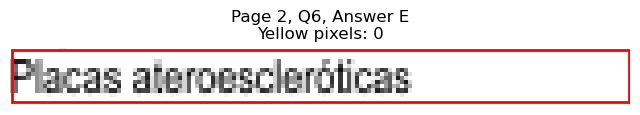


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=149.5, y1=531.2
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 398
Page 2, Q7, A: Yellow percentage: 0.0%


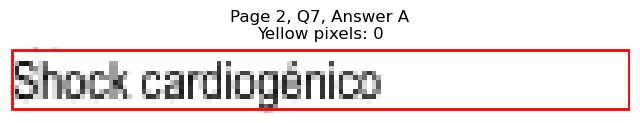

Page 2, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=202.1, y1=543.8
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 662
Page 2, Q7, B: Yellow percentage: 0.0%


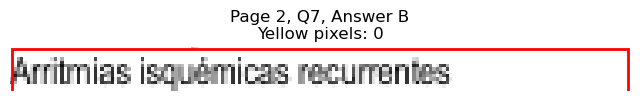

Page 2, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=203.7, y1=556.4
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 693
Page 2, Q7, C: Yellow percentage: 0.0%


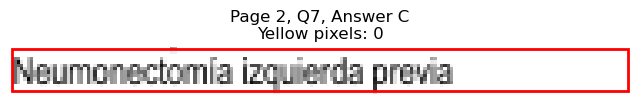

Page 2, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=495.6, y1=531.2
Page 2, Q7, D: Yellow pixels: 2101
Page 2, Q7, D: Total non-white pixels: 2996
Page 2, Q7, D: Yellow percentage: 70.1%


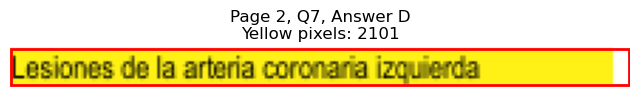

Page 2, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=432.9, y1=543.8
Page 2, Q7, E: Yellow pixels: 0
Page 2, Q7, E: Total non-white pixels: 683
Page 2, Q7, E: Yellow percentage: 0.0%


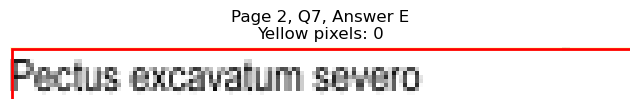


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=82.3, y1=607.0
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 117
Page 2, Q8, A: Yellow percentage: 0.0%


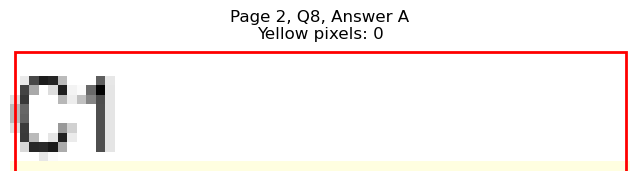

Page 2, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=82.3, y1=619.6
Page 2, Q8, B: Yellow pixels: 802
Page 2, Q8, B: Total non-white pixels: 910
Page 2, Q8, B: Yellow percentage: 88.1%


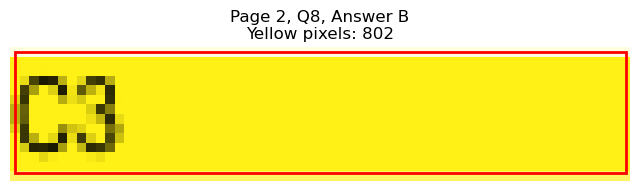

Page 2, Q8 - C: Detected box: x0=68.8, y0=619.6, x1=82.8, y1=632.3
Page 2, Q8, C: Yellow pixels: 65
Page 2, Q8, C: Total non-white pixels: 126
Page 2, Q8, C: Yellow percentage: 51.6%


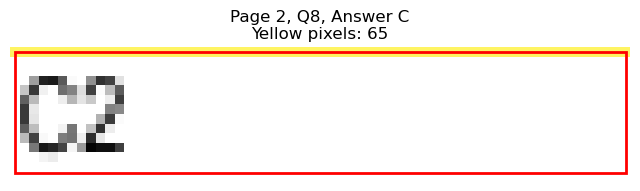

Page 2, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=341.6, y1=607.0
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 60
Page 2, Q8, D: Yellow percentage: 0.0%


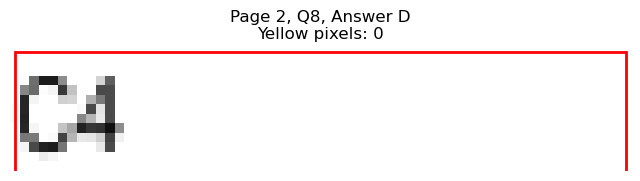

Page 2, Q8 - E: Detected box: x0=327.0, y0=606.9, x1=341.1, y1=619.6
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 64
Page 2, Q8, E: Yellow percentage: 0.0%


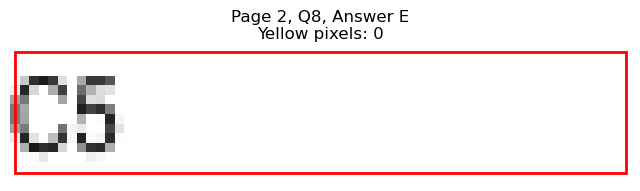


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=670.1, x1=161.5, y1=682.7
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 621
Page 2, Q9, A: Yellow percentage: 0.0%


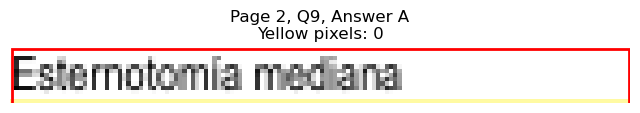

Page 2, Q9 - B: Detected box: x0=68.3, y0=682.7, x1=213.3, y1=695.3
Page 2, Q9, B: Yellow pixels: 1789
Page 2, Q9, B: Total non-white pixels: 2744
Page 2, Q9, B: Yellow percentage: 65.2%


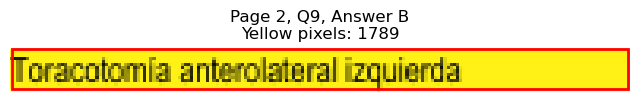

Page 2, Q9 - C: Detected box: x0=68.8, y0=695.4, x1=146.1, y1=708.0
Page 2, Q9, C: Yellow pixels: 1
Page 2, Q9, C: Total non-white pixels: 492
Page 2, Q9, C: Yellow percentage: 0.2%


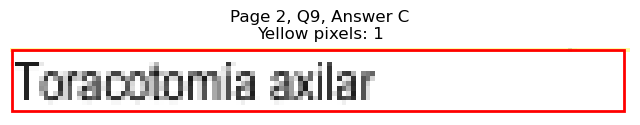

Page 2, Q9 - D: Detected box: x0=327.5, y0=670.1, x1=440.3, y1=682.7
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 571
Page 2, Q9, D: Yellow percentage: 0.0%


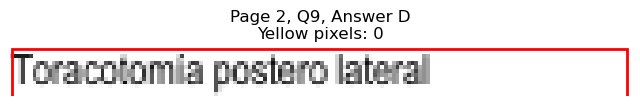

Page 2, Q9 - E: Detected box: x0=327.0, y0=682.7, x1=444.4, y1=695.3
Page 2, Q9, E: Yellow pixels: 0
Page 2, Q9, E: Total non-white pixels: 601
Page 2, Q9, E: Yellow percentage: 0.0%


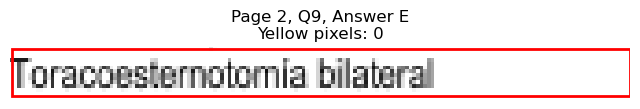


Page 2, Q9 - Selected Answer: B (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=179.2, y1=745.8
Page 2, Q10, A: Yellow pixels: 0
Page 2, Q10, A: Total non-white pixels: 539
Page 2, Q10, A: Yellow percentage: 0.0%


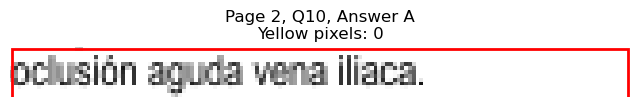

Page 2, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=196.2, y1=758.4
Page 2, Q10, B: Yellow pixels: 0
Page 2, Q10, B: Total non-white pixels: 622
Page 2, Q10, B: Yellow percentage: 0.0%


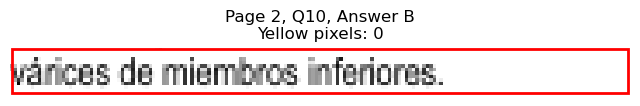

Page 2, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=189.6, y1=771.2
Page 2, Q10, C: Yellow pixels: 0
Page 2, Q10, C: Total non-white pixels: 582
Page 2, Q10, C: Yellow percentage: 0.0%


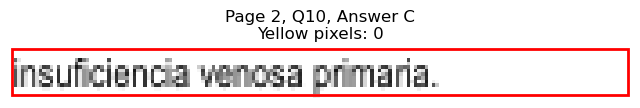

Page 2, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=371.7, y1=745.8
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 305
Page 2, Q10, D: Yellow percentage: 0.0%


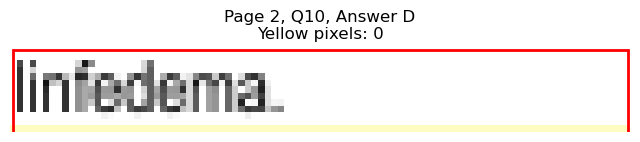

Page 2, Q10 - E: Detected box: x0=327.0, y0=745.8, x1=439.5, y1=758.4
Page 2, Q10, E: Yellow pixels: 1704
Page 2, Q10, E: Total non-white pixels: 2282
Page 2, Q10, E: Yellow percentage: 74.7%


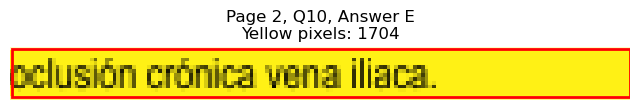


Page 2, Q10 - Selected Answer: E (based on yellow pixel count)





Page 3: Found 9 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=271.4, y1=102.1
Page 3, Q1, A: Yellow pixels: 8
Page 3, Q1, A: Total non-white pixels: 1088
Page 3, Q1, A: Yellow percentage: 0.7%


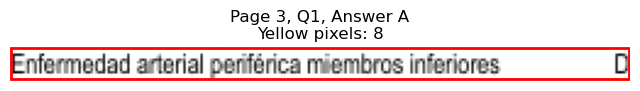

Page 3, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=140.1, y1=114.7
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 341
Page 3, Q1, B: Yellow percentage: 0.0%


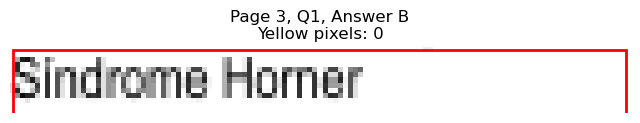

Page 3, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=170.1, y1=127.3
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 520
Page 3, Q1, C: Yellow percentage: 0.0%


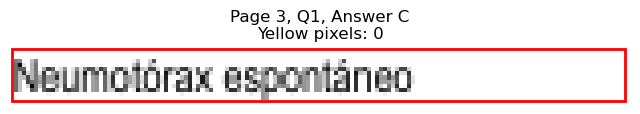

Page 3, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=371.2, y1=102.1
Page 3, Q1, D: Yellow pixels: 95
Page 3, Q1, D: Total non-white pixels: 318
Page 3, Q1, D: Yellow percentage: 29.9%


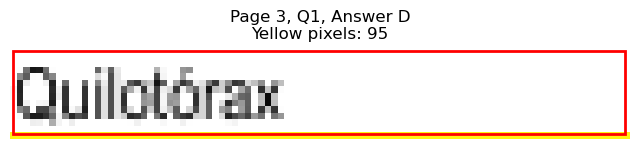

Page 3, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=443.3, y1=114.7
Page 3, Q1, E: Yellow pixels: 1734
Page 3, Q1, E: Total non-white pixels: 2171
Page 3, Q1, E: Yellow percentage: 79.9%


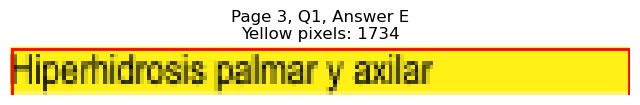


Page 3, Q1 - Selected Answer: E (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=606.9, x1=150.1, y1=619.6
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 545
Page 3, Q2, A: Yellow percentage: 0.0%


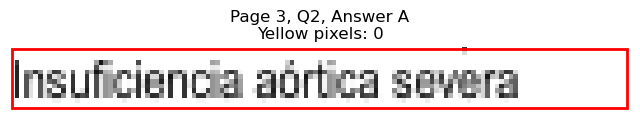

Page 3, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=195.7, y1=177.8
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 625
Page 3, Q2, B: Yellow percentage: 0.0%


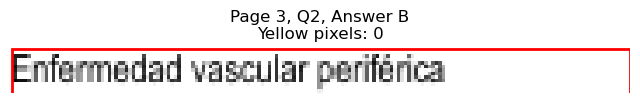

Page 3, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=150.0, y1=190.4
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 431
Page 3, Q2, C: Yellow percentage: 0.0%


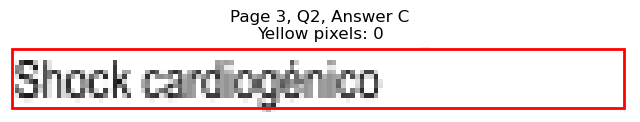

Page 3, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=424.9, y1=165.2
Page 3, Q2, D: Yellow pixels: 148
Page 3, Q2, D: Total non-white pixels: 639
Page 3, Q2, D: Yellow percentage: 23.2%


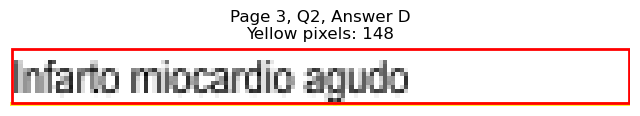

Page 3, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=429.9, y1=177.8
Page 3, Q2, E: Yellow pixels: 1577
Page 3, Q2, E: Total non-white pixels: 1989
Page 3, Q2, E: Yellow percentage: 79.3%


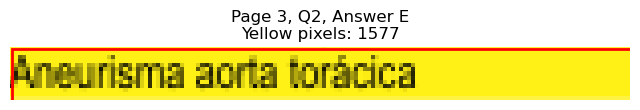


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=244.8, y1=228.3
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 909
Page 3, Q3, A: Yellow percentage: 0.0%


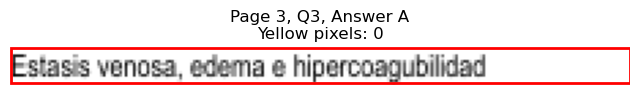

Page 3, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=251.9, y1=240.9
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 967
Page 3, Q3, B: Yellow percentage: 0.0%


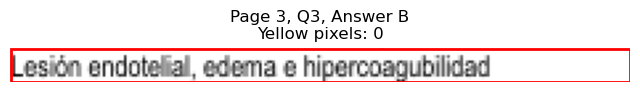

Page 3, Q3 - C: Detected box: x0=68.8, y0=240.9, x1=264.4, y1=253.5
Page 3, Q3, C: Yellow pixels: 1
Page 3, Q3, C: Total non-white pixels: 1019
Page 3, Q3, C: Yellow percentage: 0.1%


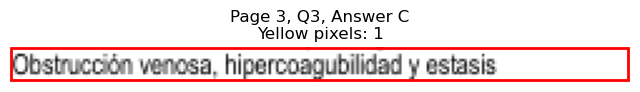

Page 3, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=517.7, y1=228.3
Page 3, Q3, D: Yellow pixels: 213
Page 3, Q3, D: Total non-white pixels: 1149
Page 3, Q3, D: Yellow percentage: 18.5%


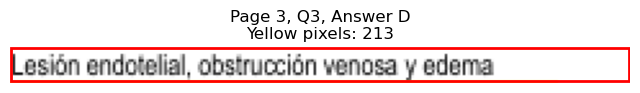

Page 3, Q3 - E: Detected box: x0=327.0, y0=228.3, x1=540.2, y1=240.9
Page 3, Q3, E: Yellow pixels: 1916
Page 3, Q3, E: Total non-white pixels: 2782
Page 3, Q3, E: Yellow percentage: 68.9%


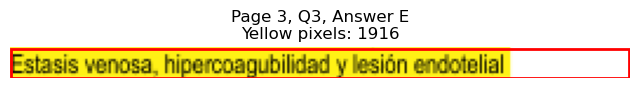


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=143.1, y1=304.1
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 336
Page 3, Q4, A: Yellow percentage: 0.0%


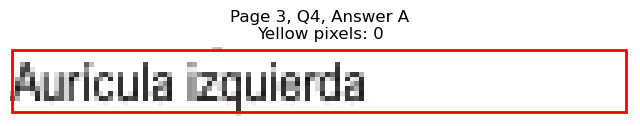

Page 3, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=150.5, y1=316.7
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 554
Page 3, Q4, B: Yellow percentage: 0.0%


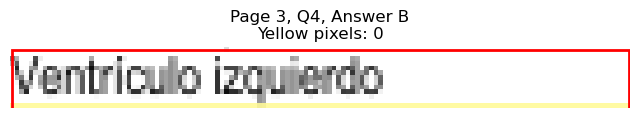

Page 3, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=147.0, y1=329.3
Page 3, Q4, C: Yellow pixels: 1257
Page 3, Q4, C: Total non-white pixels: 1820
Page 3, Q4, C: Yellow percentage: 69.1%


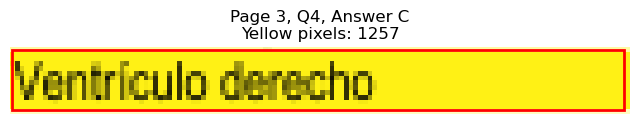

Page 3, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=405.8, y1=304.1
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 402
Page 3, Q4, D: Yellow percentage: 0.0%


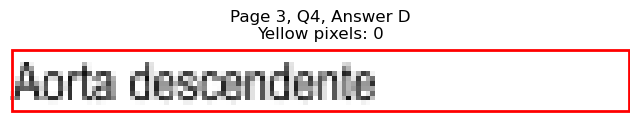

Page 3, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=397.7, y1=316.7
Page 3, Q4, E: Yellow pixels: 0
Page 3, Q4, E: Total non-white pixels: 358
Page 3, Q4, E: Yellow percentage: 0.0%


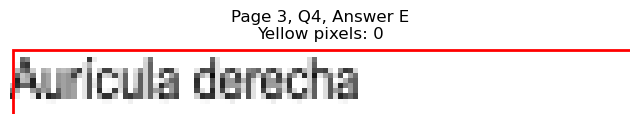


Page 3, Q4 - Selected Answer: C (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=146.5, y1=392.4
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 417
Page 3, Q5, A: Yellow percentage: 0.0%


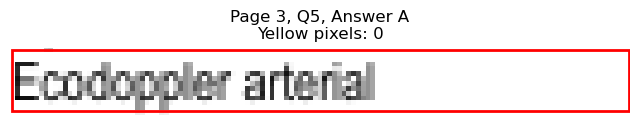

Page 3, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=109.0, y1=405.0
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 218
Page 3, Q5, B: Yellow percentage: 0.0%


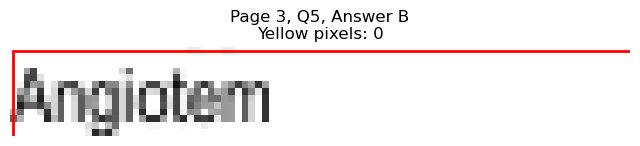

Page 3, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=141.5, y1=417.6
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 375
Page 3, Q5, C: Yellow percentage: 0.0%


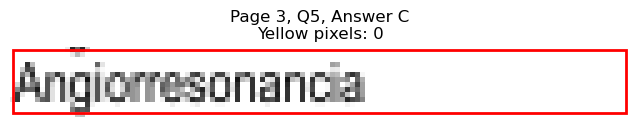

Page 3, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=379.7, y1=392.4
Page 3, Q5, D: Yellow pixels: 103
Page 3, Q5, D: Total non-white pixels: 377
Page 3, Q5, D: Yellow percentage: 27.3%


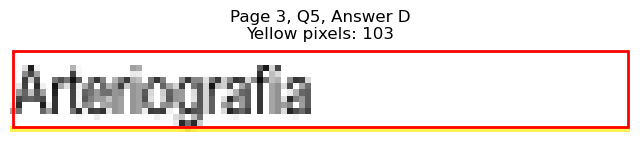

Page 3, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=455.0, y1=405.0
Page 3, Q5, E: Yellow pixels: 1811
Page 3, Q5, E: Total non-white pixels: 2314
Page 3, Q5, E: Yellow percentage: 78.3%


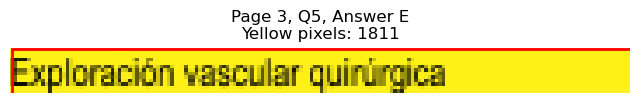


Page 3, Q5 - Selected Answer: E (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=146.5, y1=455.5
Page 3, Q6, A: Yellow pixels: 129
Page 3, Q6, A: Total non-white pixels: 513
Page 3, Q6, A: Yellow percentage: 25.1%


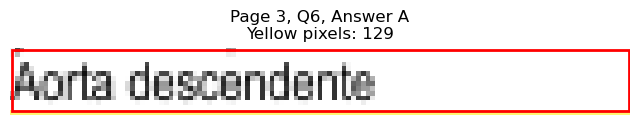

Page 3, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=122.4, y1=468.1
Page 3, Q6, B: Yellow pixels: 1162
Page 3, Q6, B: Total non-white pixels: 1470
Page 3, Q6, B: Yellow percentage: 79.0%


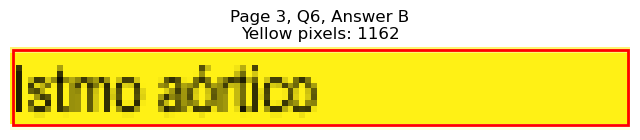

Page 3, Q6 - C: Detected box: x0=68.8, y0=468.1, x1=262.8, y1=480.7
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 1178
Page 3, Q6, C: Yellow percentage: 0.0%


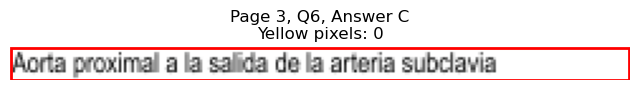

Page 3, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=467.0, y1=455.5
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 683
Page 3, Q6, D: Yellow percentage: 0.0%


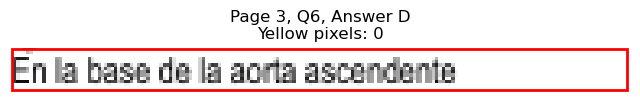

Page 3, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=400.3, y1=468.1
Page 3, Q6, E: Yellow pixels: 0
Page 3, Q6, E: Total non-white pixels: 368
Page 3, Q6, E: Yellow percentage: 0.0%


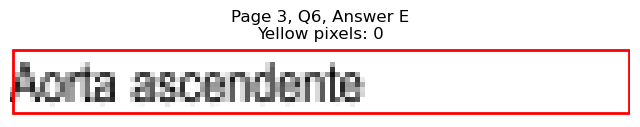


Page 3, Q6 - Selected Answer: B (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=198.3, y1=556.4
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 638
Page 3, Q7, A: Yellow percentage: 0.0%


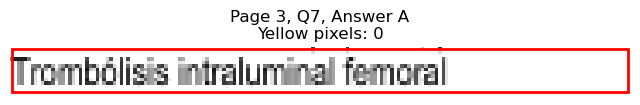

Page 3, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=177.1, y1=569.2
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 556
Page 3, Q7, B: Yellow percentage: 0.0%


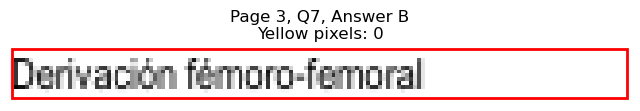

Page 3, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=179.1, y1=581.8
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 542
Page 3, Q7, C: Yellow percentage: 0.0%


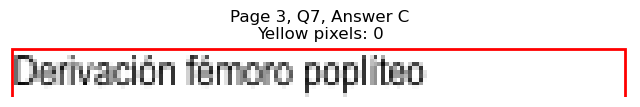

Page 3, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=411.8, y1=556.4
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 425
Page 3, Q7, D: Yellow percentage: 0.0%


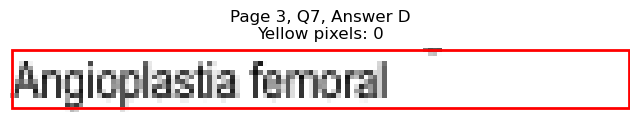

Page 3, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=521.7, y1=569.2
Page 3, Q7, E: Yellow pixels: 2033
Page 3, Q7, E: Total non-white pixels: 2995
Page 3, Q7, E: Yellow percentage: 67.9%


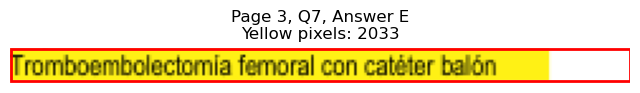


Page 3, Q7 - Selected Answer: E (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=179.7, y1=619.6
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 545
Page 3, Q8, A: Yellow percentage: 0.0%


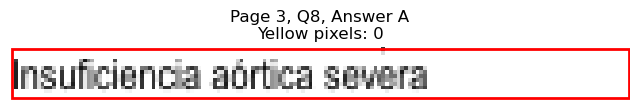

Page 3, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=158.5, y1=632.3
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 455
Page 3, Q8, B: Yellow percentage: 0.0%


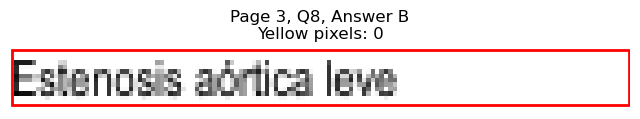

Page 3, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=276.9, y1=644.9
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 1038
Page 3, Q8, C: Yellow percentage: 0.0%


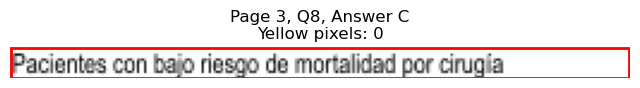

Page 3, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=428.3, y1=619.6
Page 3, Q8, D: Yellow pixels: 1590
Page 3, Q8, D: Total non-white pixels: 2128
Page 3, Q8, D: Yellow percentage: 74.7%


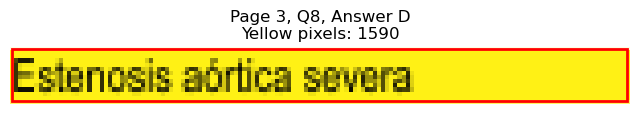

Page 3, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=466.5, y1=632.3
Page 3, Q8, E: Yellow pixels: 190
Page 3, Q8, E: Total non-white pixels: 861
Page 3, Q8, E: Yellow percentage: 22.1%


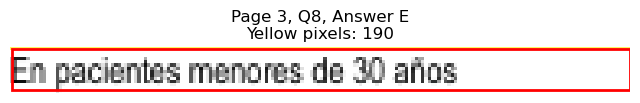


Page 3, Q8 - Selected Answer: D (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=109.5, y1=708.0
Page 3, Q9, A: Yellow pixels: 92
Page 3, Q9, A: Total non-white pixels: 384
Page 3, Q9, A: Yellow percentage: 24.0%


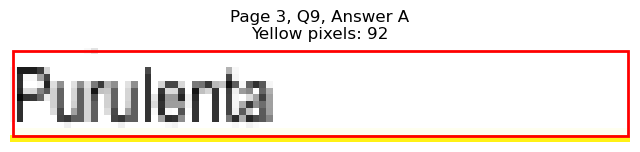

Page 3, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=107.9, y1=720.6
Page 3, Q9, B: Yellow pixels: 1013
Page 3, Q9, B: Total non-white pixels: 1260
Page 3, Q9, B: Yellow percentage: 80.4%


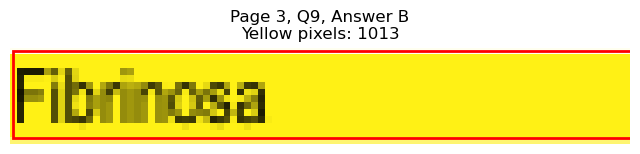

Page 3, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=122.9, y1=733.2
Page 3, Q9, C: Yellow pixels: 105
Page 3, Q9, C: Total non-white pixels: 395
Page 3, Q9, C: Yellow percentage: 26.6%


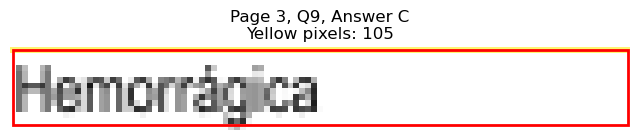

Page 3, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=365.7, y1=708.0
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 194
Page 3, Q9, D: Yellow percentage: 0.0%


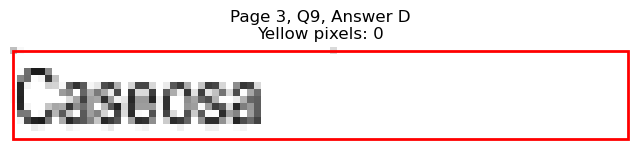

Page 3, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=355.7, y1=720.6
Page 3, Q9, E: Yellow pixels: 0
Page 3, Q9, E: Total non-white pixels: 158
Page 3, Q9, E: Yellow percentage: 0.0%


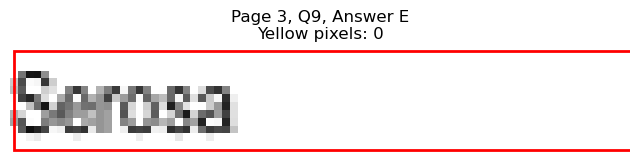


Page 3, Q9 - Selected Answer: B (based on yellow pixel count)





Page 4: Found 9 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=194.7, y1=102.1
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 632
Page 4, Q1, A: Yellow percentage: 0.0%


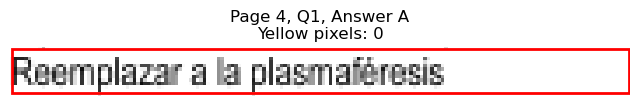

Page 4, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=259.4, y1=114.7
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 922
Page 4, Q1, B: Yellow percentage: 0.0%


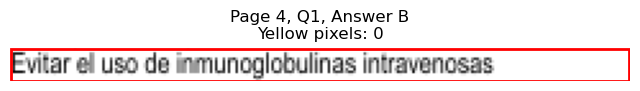

Page 4, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=179.2, y1=127.3
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 543
Page 4, Q1, C: Yellow percentage: 0.0%


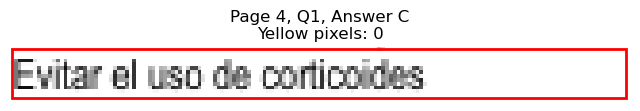

Page 4, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=507.1, y1=102.1
Page 4, Q1, D: Yellow pixels: 2079
Page 4, Q1, D: Total non-white pixels: 2995
Page 4, Q1, D: Yellow percentage: 69.4%


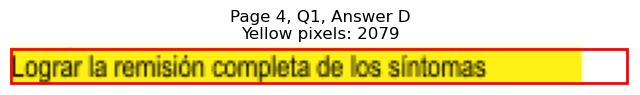

Page 4, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=531.2, y1=114.7
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 1215
Page 4, Q1, E: Yellow percentage: 0.0%


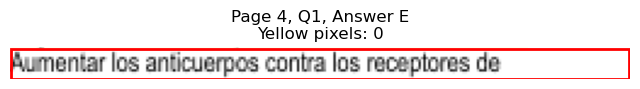


Page 4, Q1 - Selected Answer: D (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=198.7, y1=165.2
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 637
Page 4, Q2, A: Yellow percentage: 0.0%


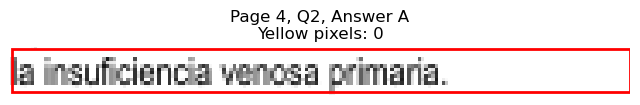

Page 4, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=210.3, y1=177.8
Page 4, Q2, B: Yellow pixels: 0
Page 4, Q2, B: Total non-white pixels: 896
Page 4, Q2, B: Yellow percentage: 0.0%


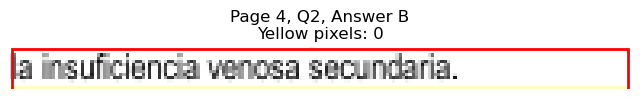

Page 4, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=122.4, y1=190.4
Page 4, Q2, C: Yellow pixels: 1057
Page 4, Q2, C: Total non-white pixels: 1470
Page 4, Q2, C: Yellow percentage: 71.9%


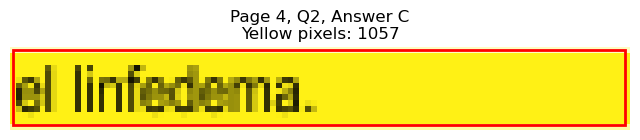

Page 4, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=460.0, y1=165.2
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 668
Page 4, Q2, D: Yellow percentage: 0.0%


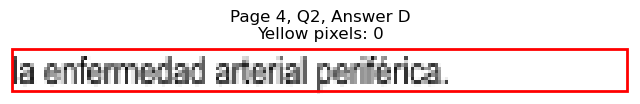

Page 4, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=450.4, y1=177.8
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 590
Page 4, Q2, E: Yellow percentage: 0.0%


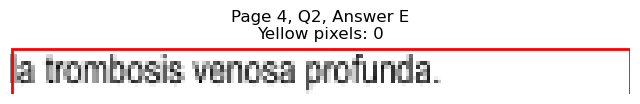


Page 4, Q2 - Selected Answer: C (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=162.6, y1=253.5
Page 4, Q3, A: Yellow pixels: 1505
Page 4, Q3, A: Total non-white pixels: 2030
Page 4, Q3, A: Yellow percentage: 74.1%


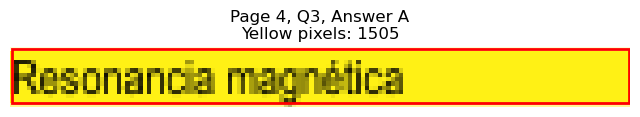

Page 4, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=134.1, y1=266.1
Page 4, Q3, B: Yellow pixels: 116
Page 4, Q3, B: Total non-white pixels: 443
Page 4, Q3, B: Yellow percentage: 26.2%


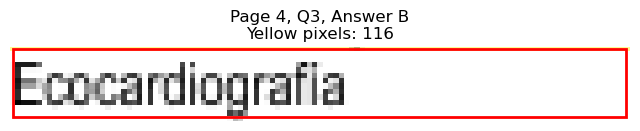

Page 4, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=179.1, y1=278.7
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 560
Page 4, Q3, C: Yellow percentage: 0.0%


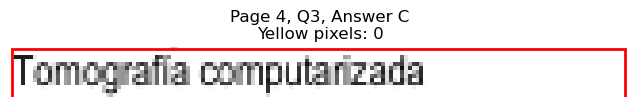

Page 4, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=405.8, y1=253.5
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 412
Page 4, Q3, D: Yellow percentage: 0.0%


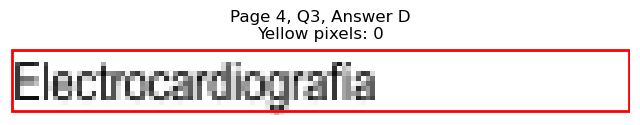

Page 4, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=418.4, y1=266.1
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 461
Page 4, Q3, E: Yellow percentage: 0.0%


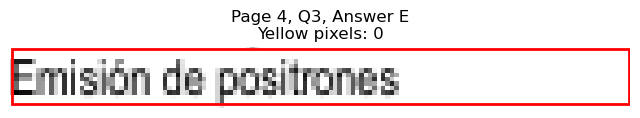


Page 4, Q3 - Selected Answer: A (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=134.1, y1=316.7
Page 4, Q4, A: Yellow pixels: 1277
Page 4, Q4, A: Total non-white pixels: 1521
Page 4, Q4, A: Yellow percentage: 84.0%


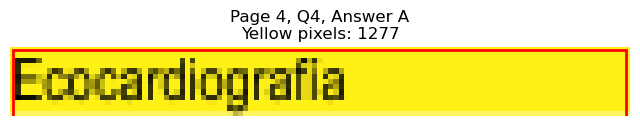

Page 4, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=116.9, y1=329.3
Page 4, Q4, B: Yellow pixels: 97
Page 4, Q4, B: Total non-white pixels: 327
Page 4, Q4, B: Yellow percentage: 29.7%


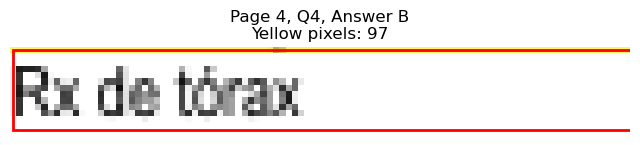

Page 4, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=156.5, y1=341.9
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 424
Page 4, Q4, C: Yellow percentage: 0.0%


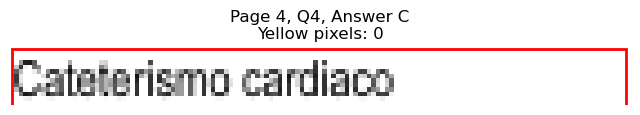

Page 4, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=384.2, y1=316.7
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 275
Page 4, Q4, D: Yellow percentage: 0.0%


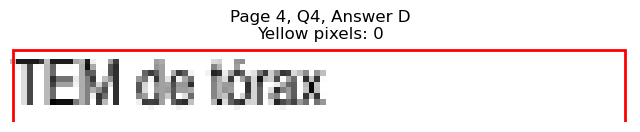

Page 4, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=385.3, y1=329.3
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 293
Page 4, Q4, E: Yellow percentage: 0.0%


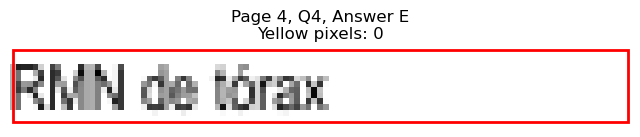


Page 4, Q4 - Selected Answer: A (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=76.8, y1=392.4
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 32
Page 4, Q5, A: Yellow percentage: 0.0%


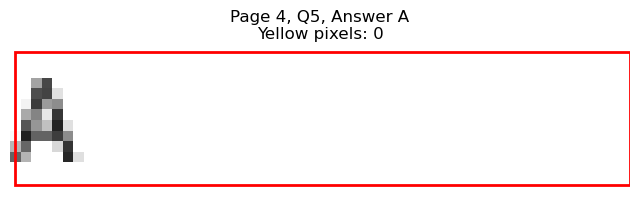

Page 4, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=77.3, y1=405.0
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 38
Page 4, Q5, B: Yellow percentage: 0.0%


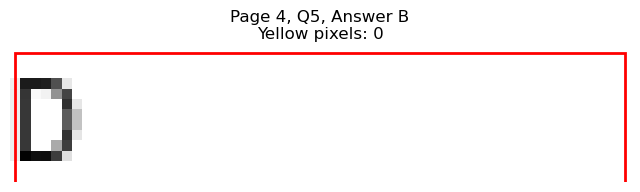

Page 4, Q5 - C: Detected box: x0=56.6, y0=404.9, x1=65.6, y1=417.6
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 70
Page 4, Q5, C: Yellow percentage: 0.0%


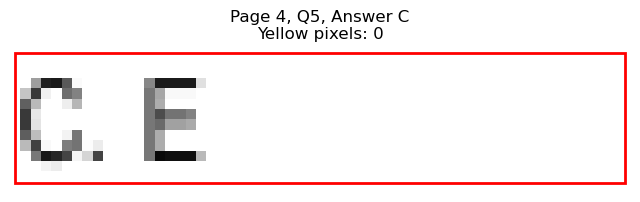

Page 4, Q5 - D: Detected box: x0=315.4, y0=379.7, x1=324.4, y1=392.4
Page 4, Q5, D: Yellow pixels: 60
Page 4, Q5, D: Total non-white pixels: 137
Page 4, Q5, D: Yellow percentage: 43.8%


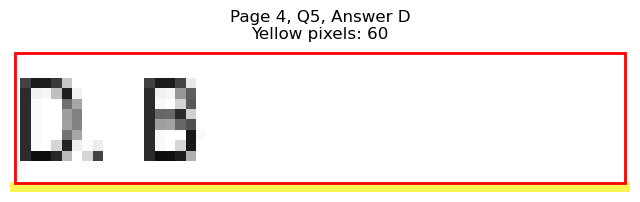

Page 4, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=336.1, y1=405.0
Page 4, Q5, E: Yellow pixels: 755
Page 4, Q5, E: Total non-white pixels: 780
Page 4, Q5, E: Yellow percentage: 96.8%


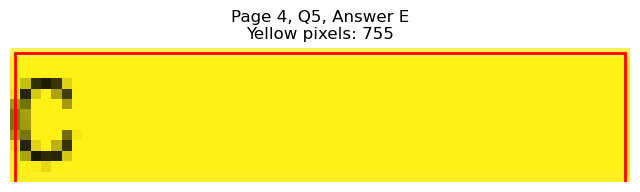


Page 4, Q5 - Selected Answer: E (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=189.1, y1=455.5
Page 4, Q6, A: Yellow pixels: 172
Page 4, Q6, A: Total non-white pixels: 762
Page 4, Q6, A: Yellow percentage: 22.6%


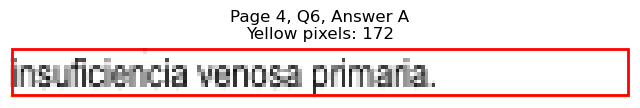

Page 4, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=112.5, y1=468.1
Page 4, Q6, B: Yellow pixels: 1052
Page 4, Q6, B: Total non-white pixels: 1330
Page 4, Q6, B: Yellow percentage: 79.1%


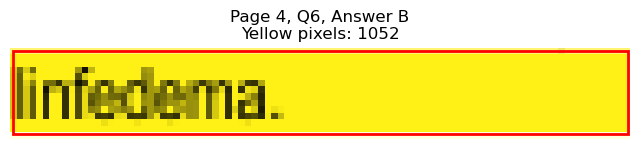

Page 4, Q6 - C: Detected box: x0=68.8, y0=468.1, x1=201.3, y1=480.7
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 839
Page 4, Q6, C: Yellow percentage: 0.0%


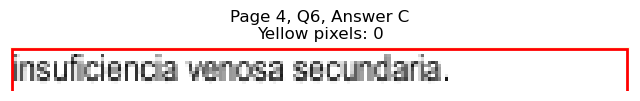

Page 4, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=442.9, y1=455.5
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 577
Page 4, Q6, D: Yellow percentage: 0.0%


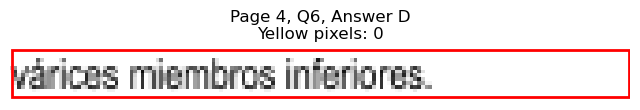

Page 4, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=449.9, y1=468.1
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 636
Page 4, Q6, E: Yellow percentage: 0.0%


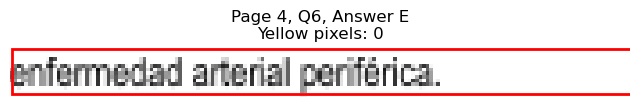


Page 4, Q6 - Selected Answer: B (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=149.5, y1=543.8
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 427
Page 4, Q7, A: Yellow percentage: 0.0%


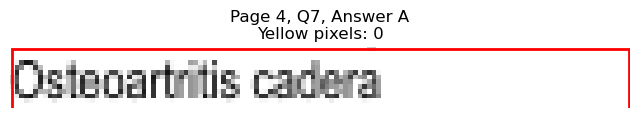

Page 4, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=146.1, y1=556.4
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 382
Page 4, Q7, B: Yellow percentage: 0.0%


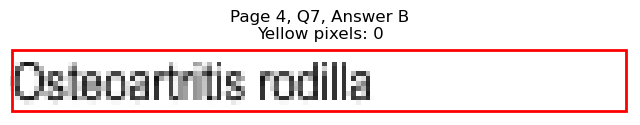

Page 4, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=151.5, y1=569.2
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 405
Page 4, Q7, C: Yellow percentage: 0.0%


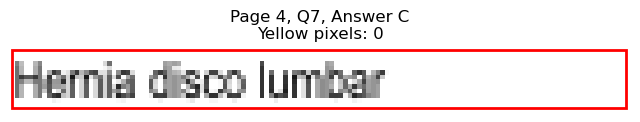

Page 4, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=442.9, y1=543.8
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 752
Page 4, Q7, D: Yellow percentage: 0.0%


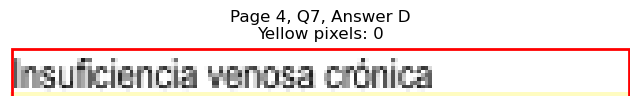

Page 4, Q7 - E: Detected box: x0=327.0, y0=543.8, x1=448.4, y1=556.4
Page 4, Q7, E: Yellow pixels: 1717
Page 4, Q7, E: Total non-white pixels: 2408
Page 4, Q7, E: Yellow percentage: 71.3%


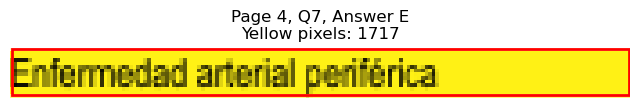


Page 4, Q7 - Selected Answer: E (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=106.9, y1=632.3
Page 4, Q8, A: Yellow pixels: 89
Page 4, Q8, A: Total non-white pixels: 278
Page 4, Q8, A: Yellow percentage: 32.0%


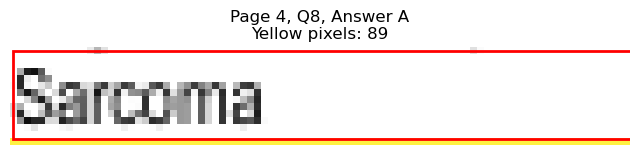

Page 4, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=102.4, y1=644.9
Page 4, Q8, B: Yellow pixels: 974
Page 4, Q8, B: Total non-white pixels: 1105
Page 4, Q8, B: Yellow percentage: 88.1%


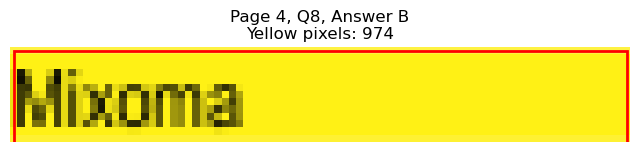

Page 4, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=100.9, y1=657.5
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 152
Page 4, Q8, C: Yellow percentage: 0.0%


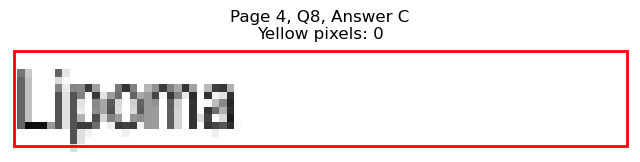

Page 4, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=416.8, y1=632.3
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 487
Page 4, Q8, D: Yellow percentage: 0.0%


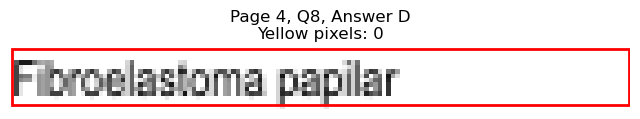

Page 4, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=383.2, y1=644.9
Page 4, Q8, E: Yellow pixels: 0
Page 4, Q8, E: Total non-white pixels: 282
Page 4, Q8, E: Yellow percentage: 0.0%


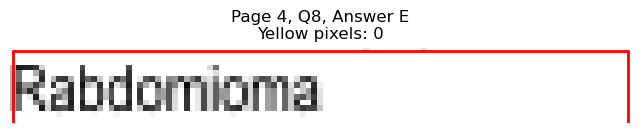


Page 4, Q8 - Selected Answer: B (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=80.9, y1=708.0
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 55
Page 4, Q9, A: Yellow percentage: 0.0%


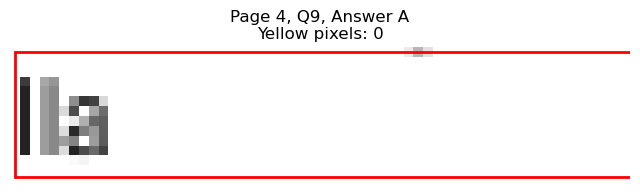

Page 4, Q9 - B: Detected box: x0=56.6, y0=708.0, x1=65.2, y1=720.6
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 50
Page 4, Q9, B: Yellow percentage: 0.0%


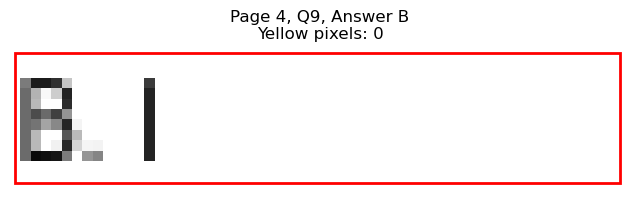

Page 4, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=78.9, y1=733.2
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 40
Page 4, Q9, C: Yellow percentage: 0.0%


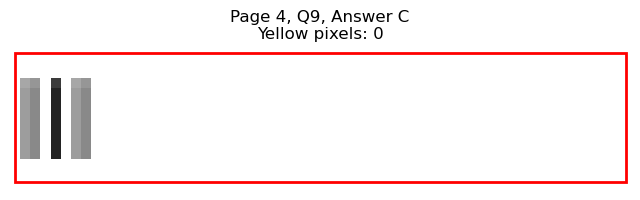

Page 4, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=340.1, y1=708.0
Page 4, Q9, D: Yellow pixels: 789
Page 4, Q9, D: Total non-white pixels: 832
Page 4, Q9, D: Yellow percentage: 94.8%


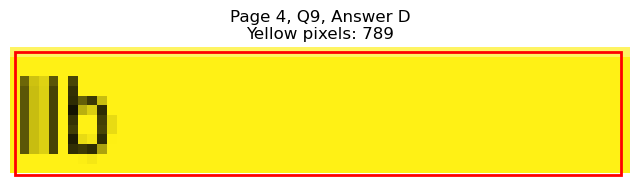

Page 4, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=338.1, y1=720.6
Page 4, Q9, E: Yellow pixels: 62
Page 4, Q9, E: Total non-white pixels: 107
Page 4, Q9, E: Yellow percentage: 57.9%


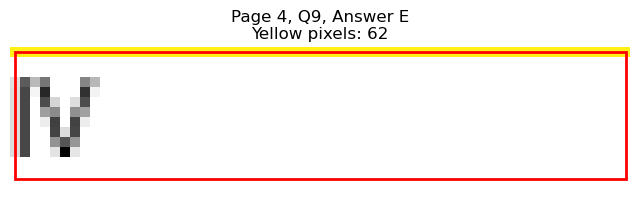


Page 4, Q9 - Selected Answer: D (based on yellow pixel count)





Page 5: Found 9 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=220.8, y1=127.3
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 782
Page 5, Q1, A: Yellow percentage: 0.0%


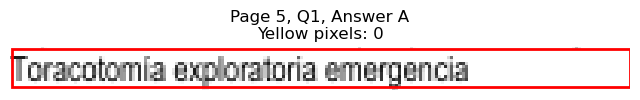

Page 5, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=121.9, y1=139.9
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 288
Page 5, Q1, B: Yellow percentage: 0.0%


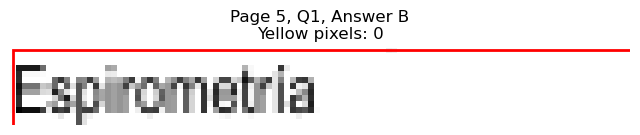

Page 5, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=204.6, y1=152.6
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 669
Page 5, Q1, C: Yellow percentage: 0.0%


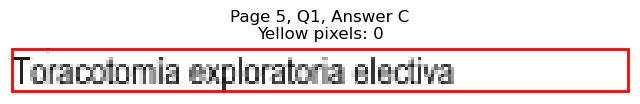

Page 5, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=423.8, y1=127.3
Page 5, Q1, D: Yellow pixels: 147
Page 5, Q1, D: Total non-white pixels: 643
Page 5, Q1, D: Yellow percentage: 22.9%


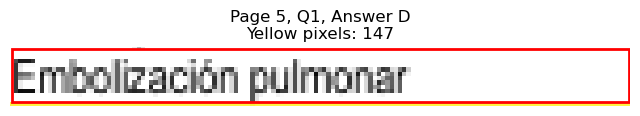

Page 5, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=430.9, y1=139.9
Page 5, Q1, E: Yellow pixels: 1600
Page 5, Q1, E: Total non-white pixels: 2002
Page 5, Q1, E: Yellow percentage: 79.9%


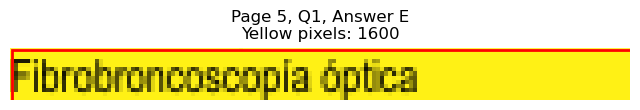


Page 5, Q1 - Selected Answer: E (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=80.9, y1=190.4
Page 5, Q2, A: Yellow pixels: 63
Page 5, Q2, A: Total non-white pixels: 108
Page 5, Q2, A: Yellow percentage: 58.3%


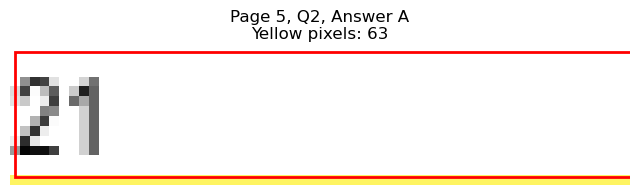

Page 5, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=80.9, y1=203.0
Page 5, Q2, B: Yellow pixels: 784
Page 5, Q2, B: Total non-white pixels: 819
Page 5, Q2, B: Yellow percentage: 95.7%


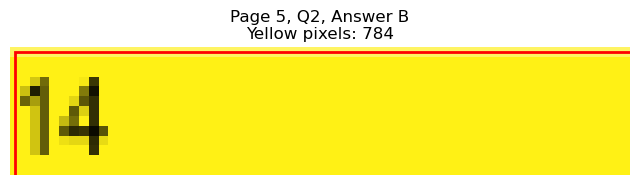

Page 5, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=81.4, y1=215.6
Page 5, Q2, C: Yellow pixels: 64
Page 5, Q2, C: Total non-white pixels: 124
Page 5, Q2, C: Yellow percentage: 51.6%


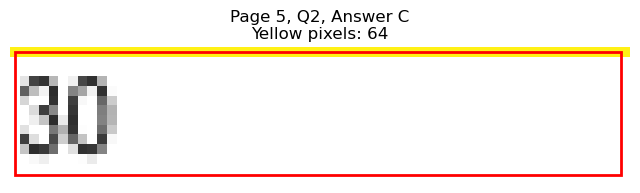

Page 5, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=340.1, y1=190.4
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 61
Page 5, Q2, D: Yellow percentage: 0.0%


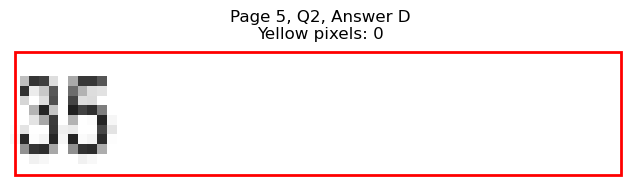

Page 5, Q2 - E: Detected box: x0=315.4, y0=190.3, x1=323.9, y1=203.0
Page 5, Q2, E: Yellow pixels: 0
Page 5, Q2, E: Total non-white pixels: 58
Page 5, Q2, E: Yellow percentage: 0.0%


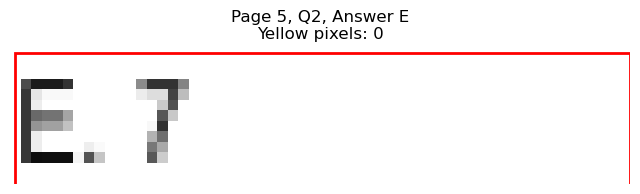


Page 5, Q2 - Selected Answer: B (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=94.3, y1=253.5
Page 5, Q3, A: Yellow pixels: 77
Page 5, Q3, A: Total non-white pixels: 218
Page 5, Q3, A: Yellow percentage: 35.3%


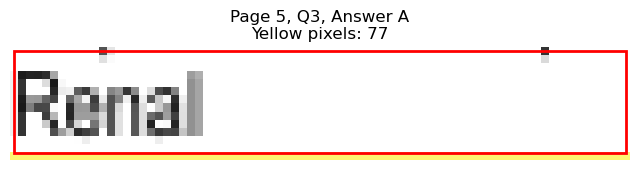

Page 5, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=109.9, y1=266.1
Page 5, Q3, B: Yellow pixels: 1013
Page 5, Q3, B: Total non-white pixels: 1288
Page 5, Q3, B: Yellow percentage: 78.6%


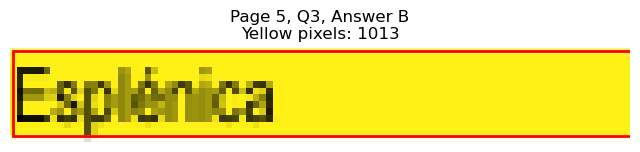

Page 5, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=106.9, y1=278.7
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 293
Page 5, Q3, C: Yellow percentage: 0.0%


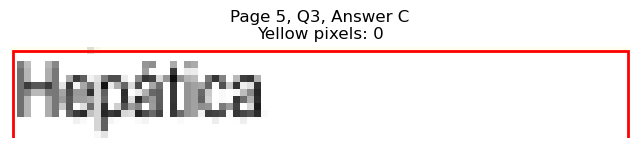

Page 5, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=369.7, y1=253.5
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 211
Page 5, Q3, D: Yellow percentage: 0.0%


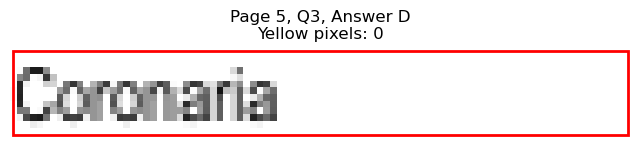

Page 5, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=372.2, y1=266.1
Page 5, Q3, E: Yellow pixels: 0
Page 5, Q3, E: Total non-white pixels: 234
Page 5, Q3, E: Yellow percentage: 0.0%


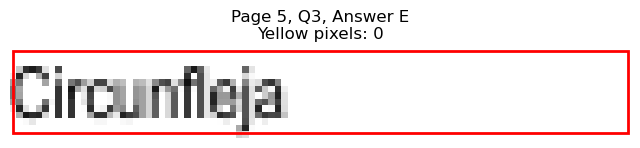


Page 5, Q3 - Selected Answer: B (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=258.9, y1=329.3
Page 5, Q4, A: Yellow pixels: 213
Page 5, Q4, A: Total non-white pixels: 1164
Page 5, Q4, A: Yellow percentage: 18.3%


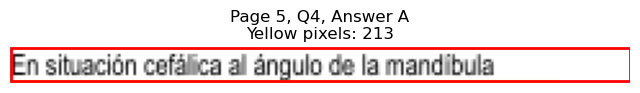

Page 5, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=204.3, y1=341.9
Page 5, Q4, B: Yellow pixels: 1914
Page 5, Q4, B: Total non-white pixels: 2431
Page 5, Q4, B: Yellow percentage: 78.7%


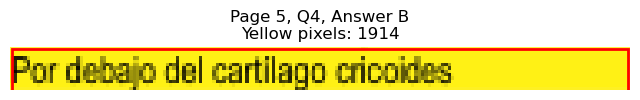

Page 5, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=249.9, y1=354.6
Page 5, Q4, C: Yellow pixels: 206
Page 5, Q4, C: Total non-white pixels: 1108
Page 5, Q4, C: Yellow percentage: 18.6%


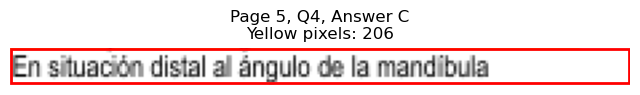

Page 5, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=465.4, y1=329.3
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 679
Page 5, Q4, D: Yellow percentage: 0.0%


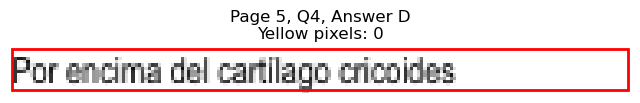

Page 5, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=524.1, y1=341.9
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 983
Page 5, Q4, E: Yellow percentage: 0.0%


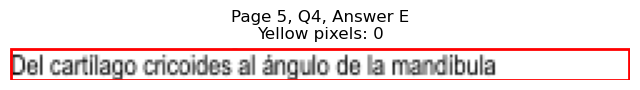


Page 5, Q4 - Selected Answer: B (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=275.4, y1=417.6
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 1055
Page 5, Q5, A: Yellow percentage: 0.0%


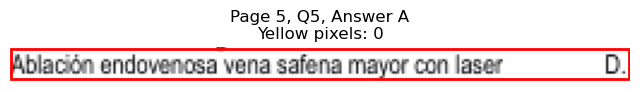

Page 5, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=185.2, y1=430.3
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 606
Page 5, Q5, B: Yellow percentage: 0.0%


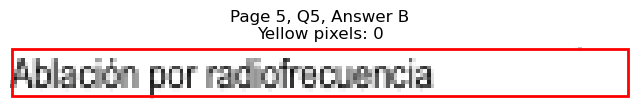

Page 5, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=182.2, y1=442.9
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 575
Page 5, Q5, C: Yellow percentage: 0.0%


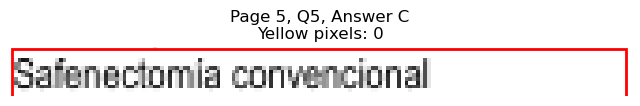

Page 5, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=418.9, y1=417.6
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 478
Page 5, Q5, D: Yellow percentage: 0.0%


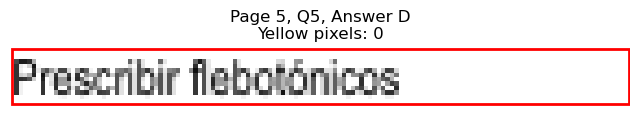

Page 5, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=387.3, y1=430.3
Page 5, Q5, E: Yellow pixels: 1081
Page 5, Q5, E: Total non-white pixels: 1554
Page 5, Q5, E: Yellow percentage: 69.6%


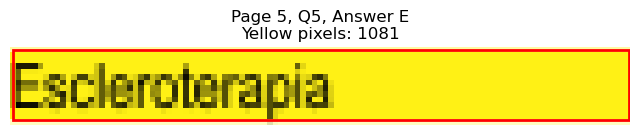


Page 5, Q5 - Selected Answer: E (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=145.0, y1=480.7
Page 5, Q6, A: Yellow pixels: 0
Page 5, Q6, A: Total non-white pixels: 365
Page 5, Q6, A: Yellow percentage: 0.0%


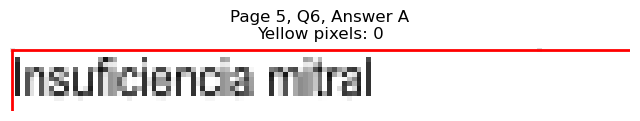

Page 5, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=165.6, y1=493.4
Page 5, Q6, B: Yellow pixels: 1394
Page 5, Q6, B: Total non-white pixels: 2072
Page 5, Q6, B: Yellow percentage: 67.3%


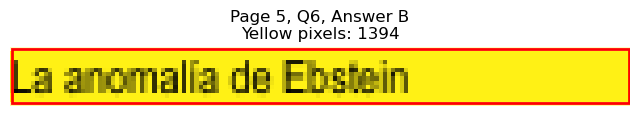

Page 5, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=150.5, y1=506.0
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 551
Page 5, Q6, C: Yellow percentage: 0.0%


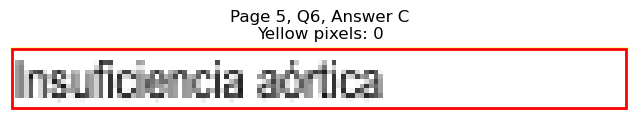

Page 5, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=393.8, y1=480.7
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 343
Page 5, Q6, D: Yellow percentage: 0.0%


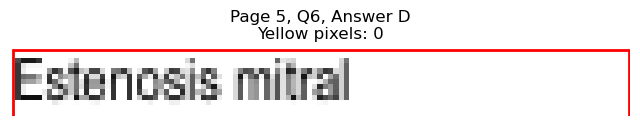

Page 5, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=398.3, y1=493.4
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 375
Page 5, Q6, E: Yellow percentage: 0.0%


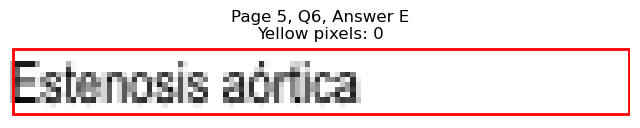


Page 5, Q6 - Selected Answer: B (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=306.0, y1=543.8
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 1128
Page 5, Q7, A: Yellow percentage: 0.0%


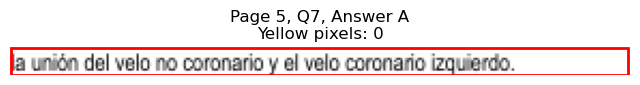

Page 5, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=302.1, y1=556.4
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 1096
Page 5, Q7, B: Yellow percentage: 0.0%


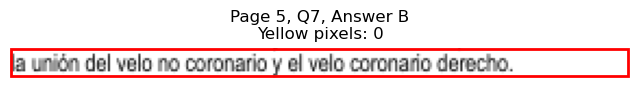

Page 5, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=191.7, y1=569.2
Page 5, Q7, C: Yellow pixels: 1820
Page 5, Q7, C: Total non-white pixels: 2436
Page 5, Q7, C: Yellow percentage: 74.7%


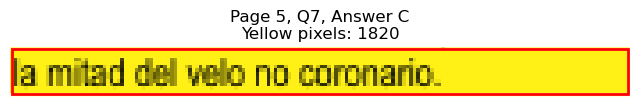

Page 5, Q7 - D: Detected box: x0=68.8, y0=569.1, x1=218.3, y1=581.8
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 935
Page 5, Q7, D: Yellow percentage: 0.0%


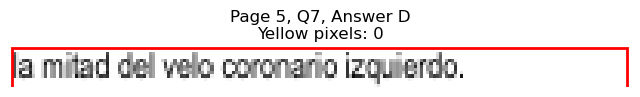

Page 5, Q7 - E: Detected box: x0=68.3, y0=581.7, x1=213.8, y1=594.4
Page 5, Q7, E: Yellow pixels: 0
Page 5, Q7, E: Total non-white pixels: 666
Page 5, Q7, E: Yellow percentage: 0.0%


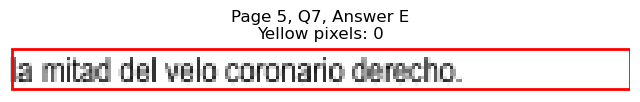


Page 5, Q7 - Selected Answer: C (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=204.3, y1=657.5
Page 5, Q8, A: Yellow pixels: 1860
Page 5, Q8, A: Total non-white pixels: 2618
Page 5, Q8, A: Yellow percentage: 71.0%


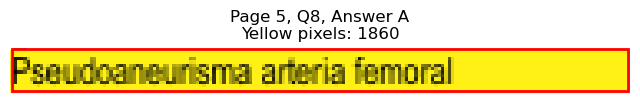

Page 5, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=146.7, y1=670.1
Page 5, Q8, B: Yellow pixels: 129
Page 5, Q8, B: Total non-white pixels: 510
Page 5, Q8, B: Yellow percentage: 25.3%


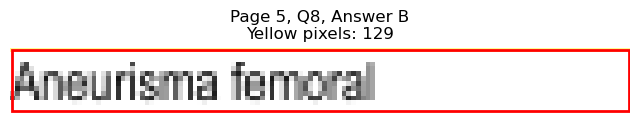

Page 5, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=149.2, y1=682.7
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 374
Page 5, Q8, C: Yellow percentage: 0.0%


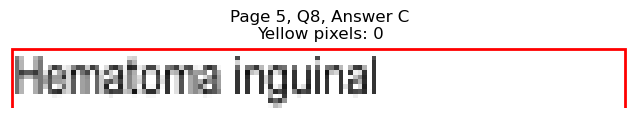

Page 5, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=450.1, y1=657.5
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 595
Page 5, Q8, D: Yellow percentage: 0.0%


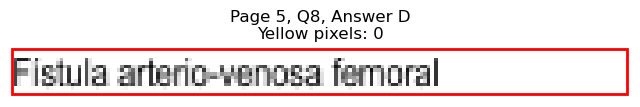

Page 5, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=461.9, y1=670.1
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 670
Page 5, Q8, E: Yellow percentage: 0.0%


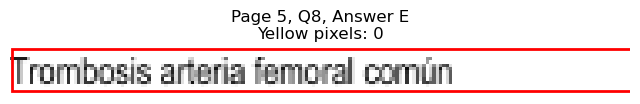


Page 5, Q8 - Selected Answer: A (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=95.9, y1=720.6
Page 5, Q9, A: Yellow pixels: 0
Page 5, Q9, A: Total non-white pixels: 159
Page 5, Q9, A: Yellow percentage: 0.0%


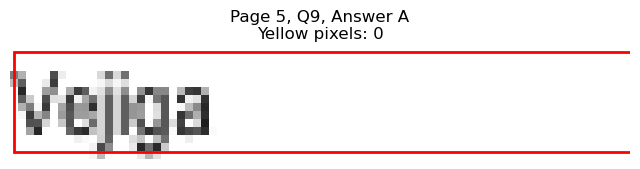

Page 5, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=109.0, y1=733.2
Page 5, Q9, B: Yellow pixels: 0
Page 5, Q9, B: Total non-white pixels: 214
Page 5, Q9, B: Yellow percentage: 0.0%


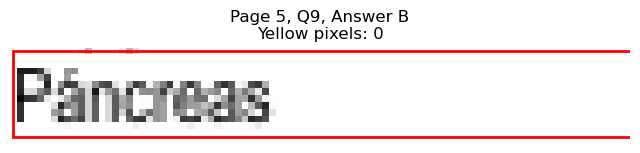

Page 5, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=104.9, y1=745.8
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 182
Page 5, Q9, C: Yellow percentage: 0.0%


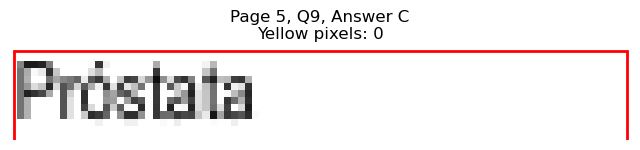

Page 5, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=360.7, y1=720.6
Page 5, Q9, D: Yellow pixels: 978
Page 5, Q9, D: Total non-white pixels: 1176
Page 5, Q9, D: Yellow percentage: 83.2%


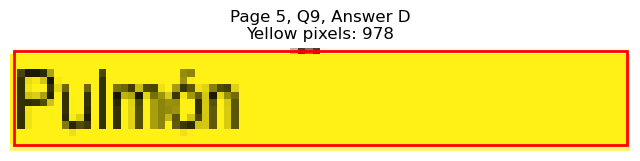

Page 5, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=359.7, y1=733.2
Page 5, Q9, E: Yellow pixels: 83
Page 5, Q9, E: Total non-white pixels: 248
Page 5, Q9, E: Yellow percentage: 33.5%


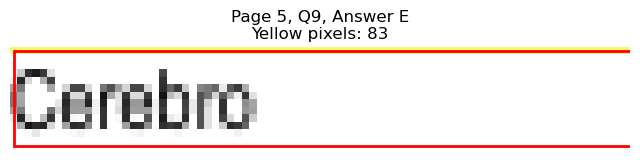


Page 5, Q9 - Selected Answer: D (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=204.6, y1=102.1
Page 6, Q1, A: Yellow pixels: 187
Page 6, Q1, A: Total non-white pixels: 837
Page 6, Q1, A: Yellow percentage: 22.3%


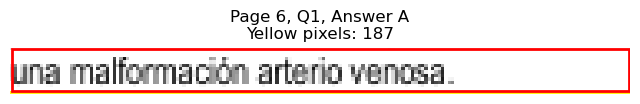

Page 6, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=225.3, y1=114.7
Page 6, Q1, B: Yellow pixels: 2067
Page 6, Q1, B: Total non-white pixels: 2704
Page 6, Q1, B: Yellow percentage: 76.4%


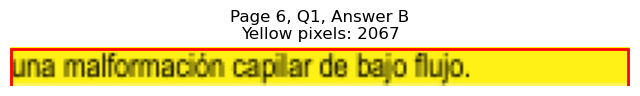

Page 6, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=177.1, y1=127.3
Page 6, Q1, C: Yellow pixels: 158
Page 6, Q1, C: Total non-white pixels: 663
Page 6, Q1, C: Yellow percentage: 23.8%


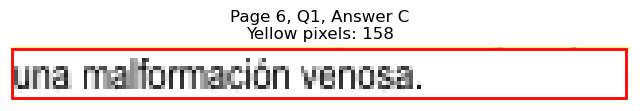

Page 6, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=437.3, y1=102.1
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 539
Page 6, Q1, D: Yellow percentage: 0.0%


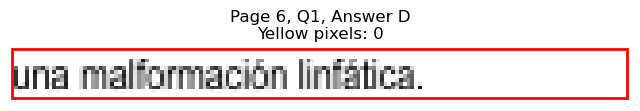

Page 6, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=403.7, y1=114.7
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 356
Page 6, Q1, E: Yellow percentage: 0.0%


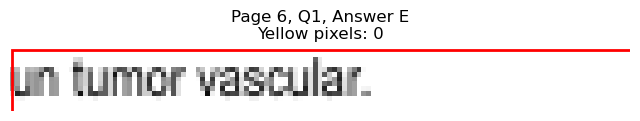


Page 6, Q1 - Selected Answer: B (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=128.5, y1=165.2
Page 6, Q2, A: Yellow pixels: 1197
Page 6, Q2, A: Total non-white pixels: 1554
Page 6, Q2, A: Yellow percentage: 77.0%


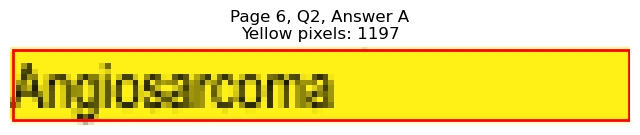

Page 6, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=121.9, y1=177.8
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 399
Page 6, Q2, B: Yellow percentage: 0.0%


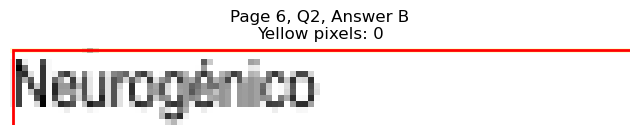

Page 6, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=115.5, y1=190.4
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 232
Page 6, Q2, C: Yellow percentage: 0.0%


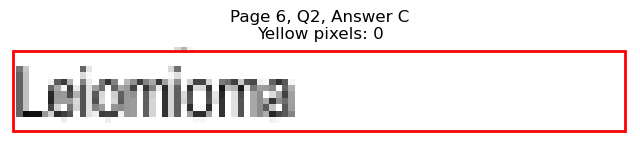

Page 6, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=362.1, y1=165.2
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 146
Page 6, Q2, D: Yellow percentage: 0.0%


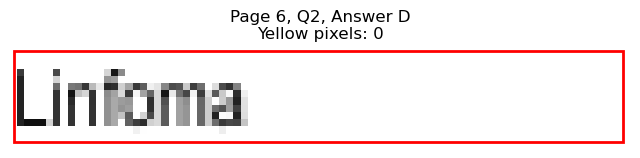

Page 6, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=368.2, y1=177.8
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 202
Page 6, Q2, E: Yellow percentage: 0.0%


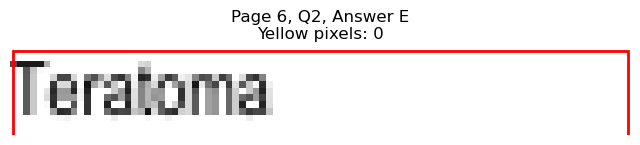


Page 6, Q2 - Selected Answer: A (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=165.6, y1=228.3
Page 6, Q3, A: Yellow pixels: 148
Page 6, Q3, A: Total non-white pixels: 651
Page 6, Q3, A: Yellow percentage: 22.7%


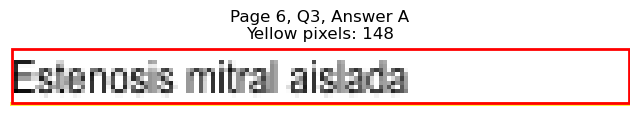

Page 6, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=193.7, y1=240.9
Page 6, Q3, B: Yellow pixels: 1785
Page 6, Q3, B: Total non-white pixels: 2288
Page 6, Q3, B: Yellow percentage: 78.0%


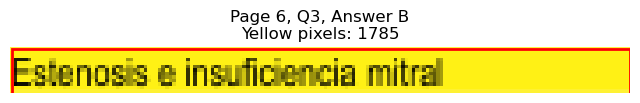

Page 6, Q3 - C: Detected box: x0=68.8, y0=240.9, x1=176.7, y1=253.5
Page 6, Q3, C: Yellow pixels: 159
Page 6, Q3, C: Total non-white pixels: 710
Page 6, Q3, C: Yellow percentage: 22.4%


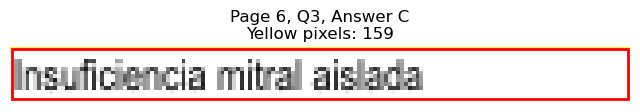

Page 6, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=538.7, y1=228.3
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 1069
Page 6, Q3, D: Yellow percentage: 0.0%


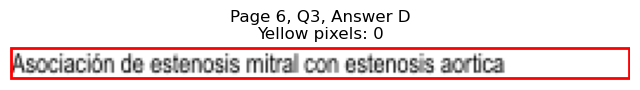

Page 6, Q3 - E: Detected box: x0=327.0, y0=228.3, x1=402.3, y1=240.9
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 394
Page 6, Q3, E: Yellow percentage: 0.0%


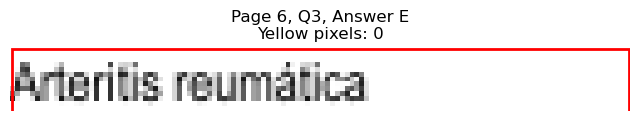


Page 6, Q3 - Selected Answer: B (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=117.5, y1=291.5
Page 6, Q4, A: Yellow pixels: 1088
Page 6, Q4, A: Total non-white pixels: 1400
Page 6, Q4, A: Yellow percentage: 77.7%


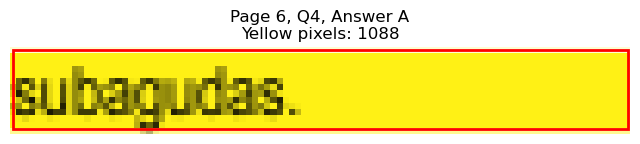

Page 6, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=103.0, y1=304.1
Page 6, Q4, B: Yellow pixels: 84
Page 6, Q4, B: Total non-white pixels: 255
Page 6, Q4, B: Yellow percentage: 32.9%


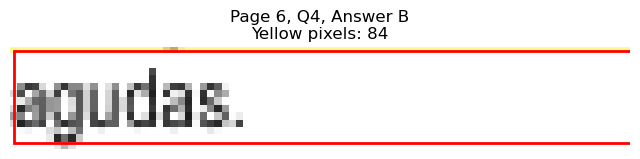

Page 6, Q4 - C: Detected box: x0=68.8, y0=304.0, x1=128.4, y1=316.7
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 295
Page 6, Q4, C: Yellow percentage: 0.0%


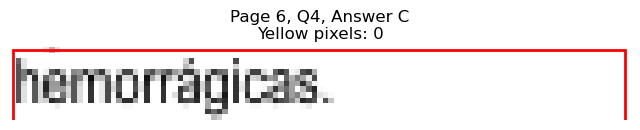

Page 6, Q4 - D: Detected box: x0=327.5, y0=278.8, x1=379.1, y1=291.5
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 261
Page 6, Q4, D: Yellow percentage: 0.0%


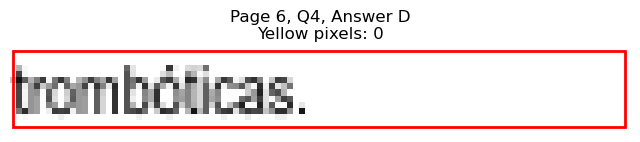

Page 6, Q4 - E: Detected box: x0=327.0, y0=291.4, x1=368.2, y1=304.1
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 198
Page 6, Q4, E: Yellow percentage: 0.0%


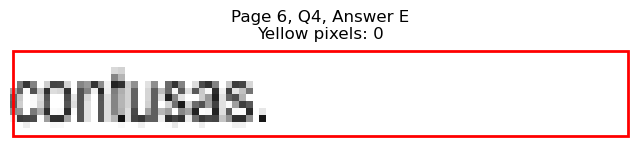


Page 6, Q4 - Selected Answer: A (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=168.1, y1=367.2
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 518
Page 6, Q5, A: Yellow percentage: 0.0%


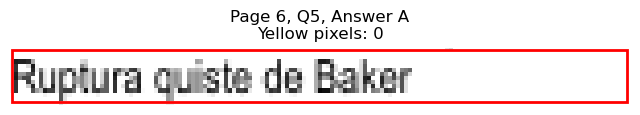

Page 6, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=249.4, y1=379.8
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 912
Page 6, Q5, B: Yellow percentage: 0.0%


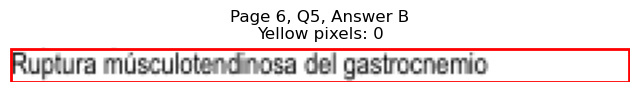

Page 6, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=183.3, y1=405.0
Page 6, Q5, C: Yellow pixels: 1725
Page 6, Q5, C: Total non-white pixels: 2158
Page 6, Q5, C: Yellow percentage: 79.9%


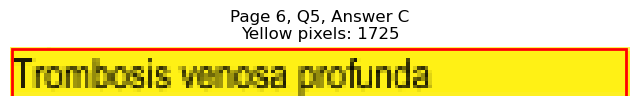

Page 6, Q5 - D: Detected box: x0=327.5, y0=354.5, x1=361.7, y1=367.2
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 191
Page 6, Q5, D: Yellow percentage: 0.0%


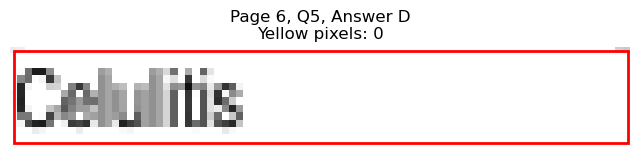

Page 6, Q5 - E: Detected box: x0=327.0, y0=367.1, x1=371.7, y1=379.8
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 221
Page 6, Q5, E: Yellow percentage: 0.0%


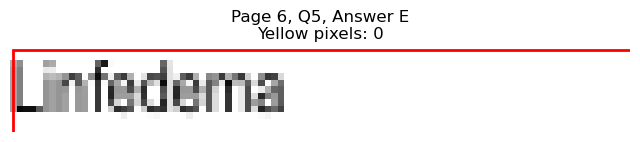


Page 6, Q5 - Selected Answer: C (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=192.1, y1=455.5
Page 6, Q6, A: Yellow pixels: 175
Page 6, Q6, A: Total non-white pixels: 799
Page 6, Q6, A: Yellow percentage: 21.9%


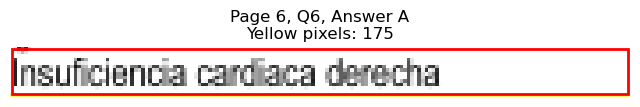

Page 6, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=209.8, y1=468.1
Page 6, Q6, B: Yellow pixels: 1929
Page 6, Q6, B: Total non-white pixels: 2688
Page 6, Q6, B: Yellow percentage: 71.8%


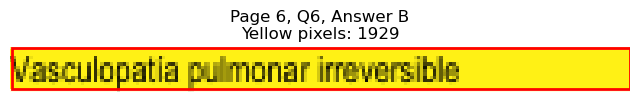

Page 6, Q6 - C: Detected box: x0=68.8, y0=468.1, x1=155.5, y1=480.7
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 606
Page 6, Q6, C: Yellow percentage: 0.0%


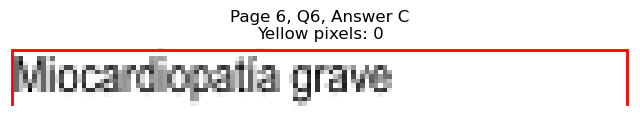

Page 6, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=413.3, y1=455.5
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 448
Page 6, Q6, D: Yellow percentage: 0.0%


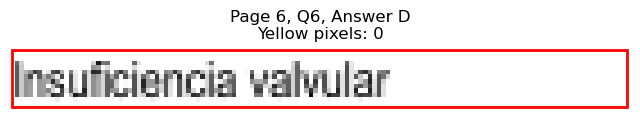

Page 6, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=402.3, y1=468.1
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 390
Page 6, Q6, E: Yellow percentage: 0.0%


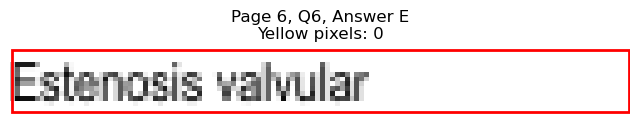


Page 6, Q6 - Selected Answer: B (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=506.0, x1=242.3, y1=518.6
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 853
Page 6, Q7, A: Yellow percentage: 0.0%


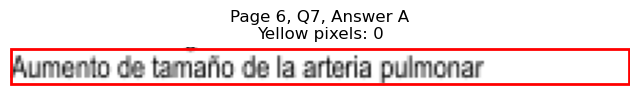

Page 6, Q7 - B: Detected box: x0=68.3, y0=518.6, x1=330.6, y1=531.2
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 1281
Page 6, Q7, B: Yellow percentage: 0.0%


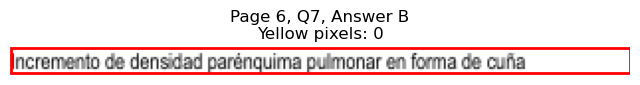

Page 6, Q7 - C: Detected box: x0=68.8, y0=531.2, x1=155.5, y1=543.8
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 580
Page 6, Q7, C: Yellow percentage: 0.0%


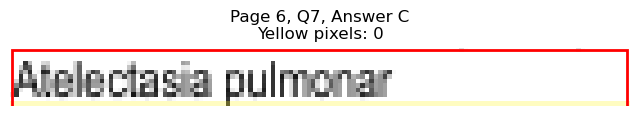

Page 6, Q7 - D: Detected box: x0=68.8, y0=543.8, x1=303.0, y1=556.4
Page 6, Q7, D: Yellow pixels: 2821
Page 6, Q7, D: Total non-white pixels: 4004
Page 6, Q7, D: Yellow percentage: 70.5%


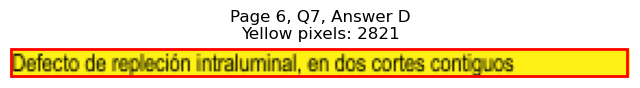

Page 6, Q7 - E: Detected box: x0=68.3, y0=556.5, x1=293.0, y1=569.2
Page 6, Q7, E: Yellow pixels: 274
Page 6, Q7, E: Total non-white pixels: 1380
Page 6, Q7, E: Yellow percentage: 19.9%


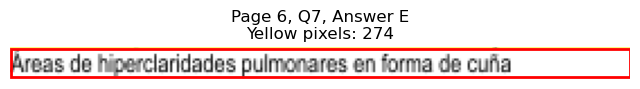


Page 6, Q7 - Selected Answer: D (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=126.0, y1=607.0
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 417
Page 6, Q8, A: Yellow percentage: 0.0%


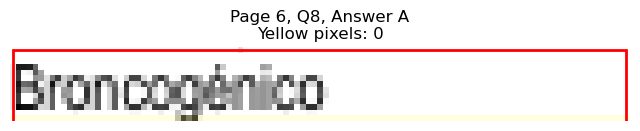

Page 6, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=115.9, y1=619.6
Page 6, Q8, B: Yellow pixels: 1071
Page 6, Q8, B: Total non-white pixels: 1372
Page 6, Q8, B: Yellow percentage: 78.1%


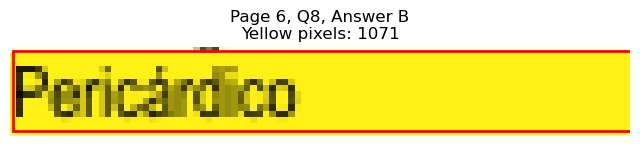

Page 6, Q8 - C: Detected box: x0=68.8, y0=619.6, x1=104.4, y1=632.3
Page 6, Q8, C: Yellow pixels: 87
Page 6, Q8, C: Total non-white pixels: 271
Page 6, Q8, C: Yellow percentage: 32.1%


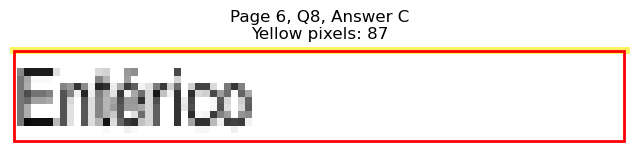

Page 6, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=366.2, y1=607.0
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 182
Page 6, Q8, D: Yellow percentage: 0.0%


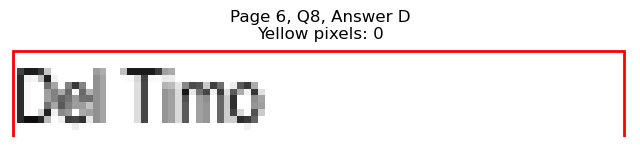

Page 6, Q8 - E: Detected box: x0=327.0, y0=606.9, x1=378.2, y1=619.6
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 267
Page 6, Q8, E: Yellow percentage: 0.0%


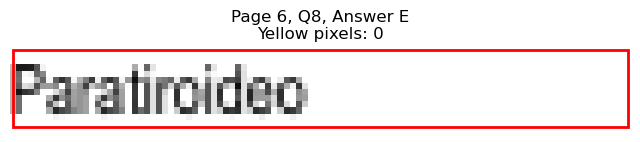


Page 6, Q8 - Selected Answer: B (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=657.5, x1=150.5, y1=670.1
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 424
Page 6, Q9, A: Yellow percentage: 0.0%


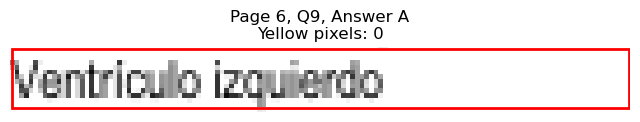

Page 6, Q9 - B: Detected box: x0=68.3, y0=670.1, x1=139.0, y1=682.7
Page 6, Q9, B: Yellow pixels: 0
Page 6, Q9, B: Total non-white pixels: 444
Page 6, Q9, B: Yellow percentage: 0.0%


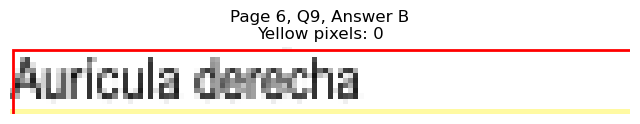

Page 6, Q9 - C: Detected box: x0=68.8, y0=682.7, x1=147.0, y1=695.3
Page 6, Q9, C: Yellow pixels: 1257
Page 6, Q9, C: Total non-white pixels: 1820
Page 6, Q9, C: Yellow percentage: 69.1%


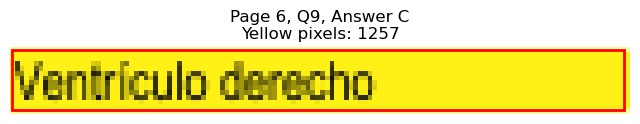

Page 6, Q9 - D: Detected box: x0=327.5, y0=657.5, x1=402.3, y1=670.1
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 368
Page 6, Q9, D: Yellow percentage: 0.0%


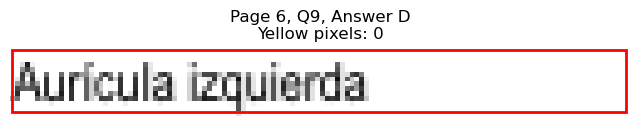

Page 6, Q9 - E: Detected box: x0=327.0, y0=670.1, x1=435.4, y1=682.7
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 548
Page 6, Q9, E: Yellow percentage: 0.0%


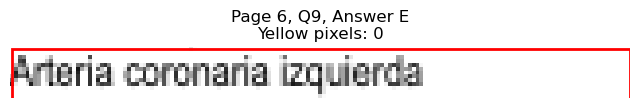


Page 6, Q9 - Selected Answer: C (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=168.6, y1=745.8
Page 6, Q10, A: Yellow pixels: 0
Page 6, Q10, A: Total non-white pixels: 503
Page 6, Q10, A: Yellow percentage: 0.0%


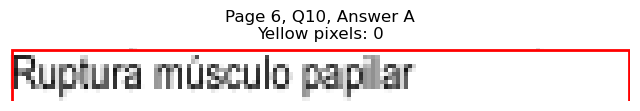

Page 6, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=149.5, y1=758.4
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 400
Page 6, Q10, B: Yellow percentage: 0.0%


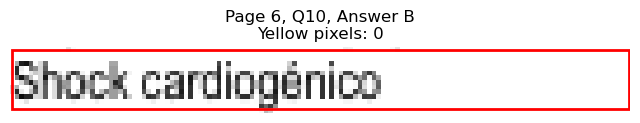

Page 6, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=192.6, y1=771.2
Page 6, Q10, C: Yellow pixels: 0
Page 6, Q10, C: Total non-white pixels: 609
Page 6, Q10, C: Yellow percentage: 0.0%


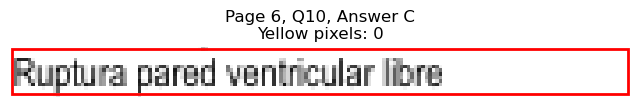

Page 6, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=479.0, y1=745.8
Page 6, Q10, D: Yellow pixels: 2030
Page 6, Q10, D: Total non-white pixels: 2639
Page 6, Q10, D: Yellow percentage: 76.9%


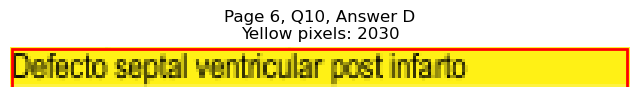

Page 6, Q10 - E: Detected box: x0=327.0, y0=745.8, x1=450.8, y1=758.4
Page 6, Q10, E: Yellow pixels: 174
Page 6, Q10, E: Total non-white pixels: 813
Page 6, Q10, E: Yellow percentage: 21.4%


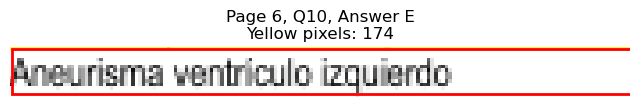


Page 6, Q10 - Selected Answer: D (based on yellow pixel count)





Page 7: Found 9 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=135.0, y1=102.1
Page 7, Q1, A: Yellow pixels: 1294
Page 7, Q1, A: Total non-white pixels: 1652
Page 7, Q1, A: Yellow percentage: 78.3%


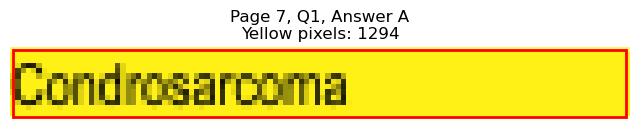

Page 7, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=129.5, y1=114.7
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 429
Page 7, Q1, B: Yellow percentage: 0.0%


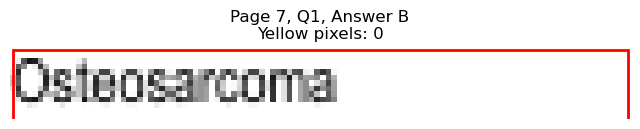

Page 7, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=147.0, y1=127.3
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 364
Page 7, Q1, C: Yellow percentage: 0.0%


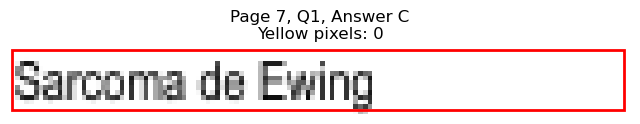

Page 7, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=386.7, y1=102.1
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 290
Page 7, Q1, D: Yellow percentage: 0.0%


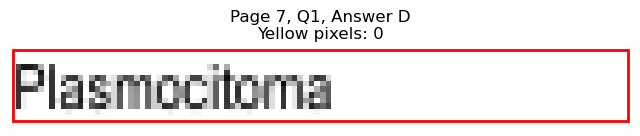

Page 7, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=397.3, y1=114.7
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 365
Page 7, Q1, E: Yellow percentage: 0.0%


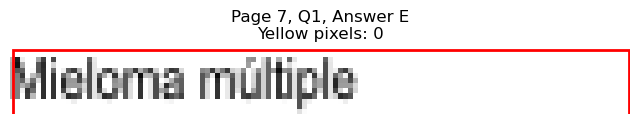


Page 7, Q1 - Selected Answer: A (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=187.1, y1=177.8
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 581
Page 7, Q2, A: Yellow percentage: 0.0%


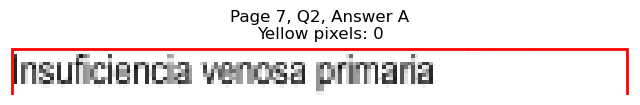

Page 7, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=182.7, y1=190.4
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 573
Page 7, Q2, B: Yellow percentage: 0.0%


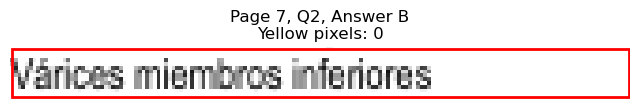

Page 7, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=190.1, y1=203.0
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 634
Page 7, Q2, C: Yellow percentage: 0.0%


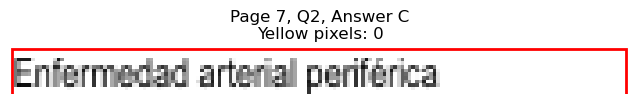

Page 7, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=372.2, y1=177.8
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 306
Page 7, Q2, D: Yellow percentage: 0.0%


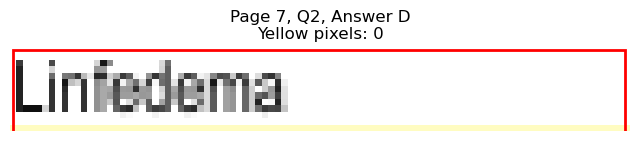

Page 7, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=427.9, y1=190.4
Page 7, Q2, E: Yellow pixels: 1425
Page 7, Q2, E: Total non-white pixels: 2114
Page 7, Q2, E: Yellow percentage: 67.4%


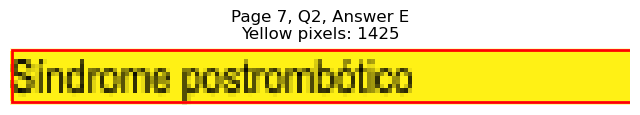


Page 7, Q2 - Selected Answer: E (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=176.2, y1=266.1
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 565
Page 7, Q3, A: Yellow percentage: 0.0%


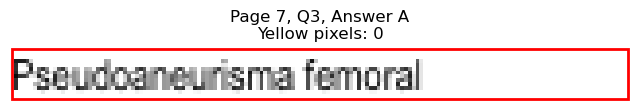

Page 7, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=147.6, y1=278.7
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 399
Page 7, Q3, B: Yellow percentage: 0.0%


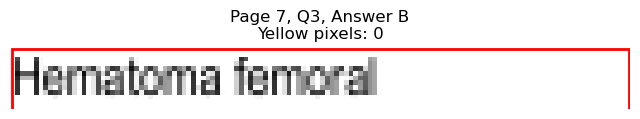

Page 7, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=191.2, y1=291.5
Page 7, Q3, C: Yellow pixels: 1781
Page 7, Q3, C: Total non-white pixels: 2436
Page 7, Q3, C: Yellow percentage: 73.1%


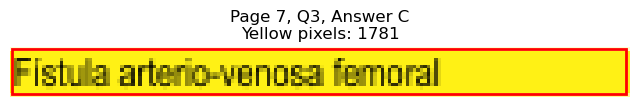

Page 7, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=483.0, y1=266.1
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 810
Page 7, Q3, D: Yellow percentage: 0.0%


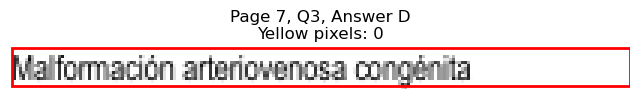

Page 7, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=442.5, y1=278.7
Page 7, Q3, E: Yellow pixels: 0
Page 7, Q3, E: Total non-white pixels: 571
Page 7, Q3, E: Yellow percentage: 0.0%


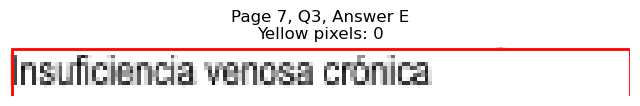


Page 7, Q3 - Selected Answer: C (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=124.0, y1=329.3
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 283
Page 7, Q4, A: Yellow percentage: 0.0%


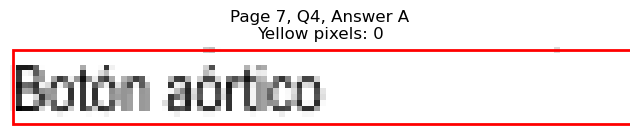

Page 7, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=173.7, y1=341.9
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 496
Page 7, Q4, B: Yellow percentage: 0.0%


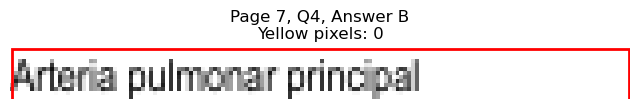

Page 7, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=104.4, y1=354.6
Page 7, Q4, C: Yellow pixels: 993
Page 7, Q4, C: Total non-white pixels: 1218
Page 7, Q4, C: Yellow percentage: 81.5%


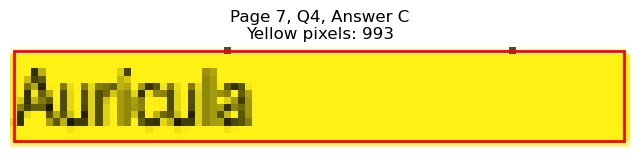

Page 7, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=370.6, y1=329.3
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 208
Page 7, Q4, D: Yellow percentage: 0.0%


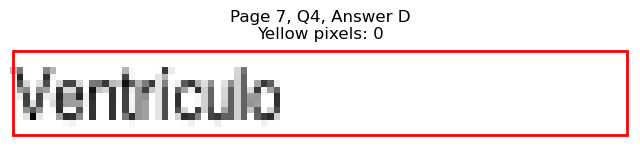

Page 7, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=452.5, y1=341.9
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 609
Page 7, Q4, E: Yellow percentage: 0.0%


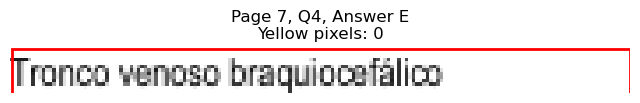


Page 7, Q4 - Selected Answer: C (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=182.2, y1=417.6
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 579
Page 7, Q5, A: Yellow percentage: 0.0%


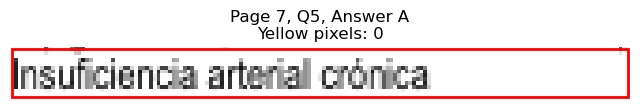

Page 7, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=183.6, y1=430.3
Page 7, Q5, B: Yellow pixels: 1565
Page 7, Q5, B: Total non-white pixels: 2324
Page 7, Q5, B: Yellow percentage: 67.3%


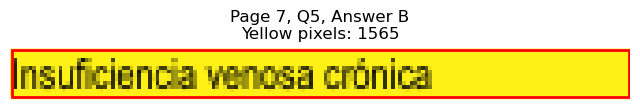

Page 7, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=165.6, y1=442.9
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 602
Page 7, Q5, C: Yellow percentage: 0.0%


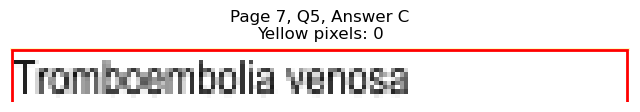

Page 7, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=441.9, y1=417.6
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 567
Page 7, Q5, D: Yellow percentage: 0.0%


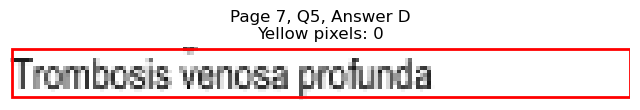

Page 7, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=413.8, y1=430.3
Page 7, Q5, E: Yellow pixels: 0
Page 7, Q5, E: Total non-white pixels: 452
Page 7, Q5, E: Yellow percentage: 0.0%


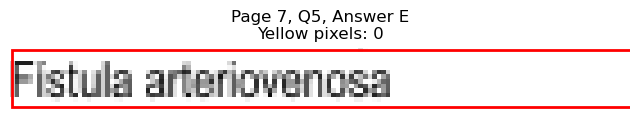


Page 7, Q5 - Selected Answer: B (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=118.0, y1=480.7
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 242
Page 7, Q6, A: Yellow percentage: 0.0%


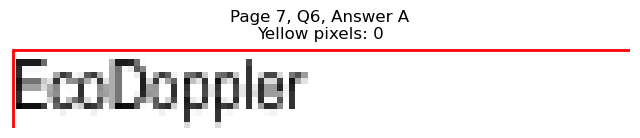

Page 7, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=137.1, y1=493.4
Page 7, Q6, B: Yellow pixels: 1169
Page 7, Q6, B: Total non-white pixels: 1680
Page 7, Q6, B: Yellow percentage: 69.6%


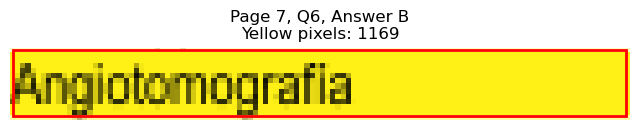

Page 7, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=138.5, y1=506.0
Page 7, Q6, C: Yellow pixels: 3
Page 7, Q6, C: Total non-white pixels: 474
Page 7, Q6, C: Yellow percentage: 0.6%


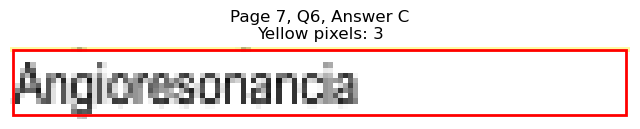

Page 7, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=374.7, y1=480.7
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 252
Page 7, Q6, D: Yellow percentage: 0.0%


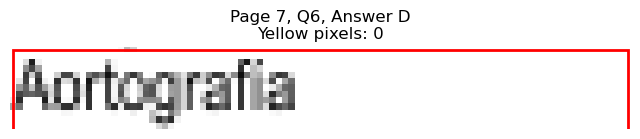

Page 7, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=370.1, y1=493.4
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 205
Page 7, Q6, E: Yellow percentage: 0.0%


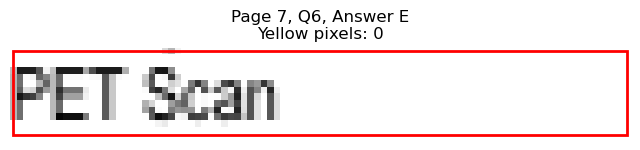


Page 7, Q6 - Selected Answer: B (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=246.9, y1=569.2
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 915
Page 7, Q7, A: Yellow percentage: 0.0%


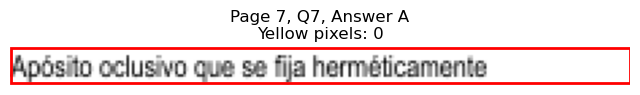

Page 7, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=144.1, y1=581.8
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 513
Page 7, Q7, B: Yellow percentage: 0.0%


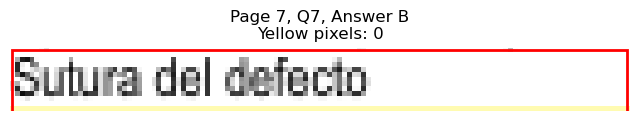

Page 7, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=248.4, y1=594.4
Page 7, Q7, C: Yellow pixels: 1883
Page 7, Q7, C: Total non-white pixels: 2996
Page 7, Q7, C: Yellow percentage: 62.9%


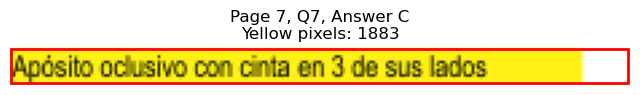

Page 7, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=430.4, y1=569.2
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 522
Page 7, Q7, D: Yellow percentage: 0.0%


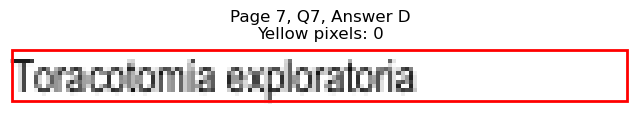

Page 7, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=384.3, y1=581.8
Page 7, Q7, E: Yellow pixels: 0
Page 7, Q7, E: Total non-white pixels: 274
Page 7, Q7, E: Yellow percentage: 0.0%


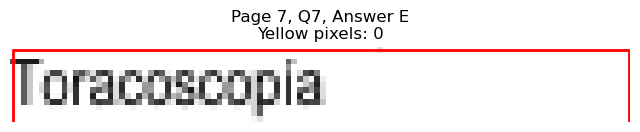


Page 7, Q7 - Selected Answer: C (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=247.5, y1=632.3
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 849
Page 7, Q8, A: Yellow percentage: 0.0%


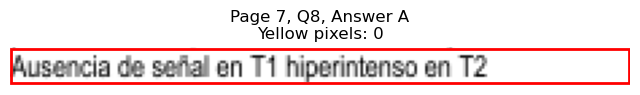

Page 7, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=221.3, y1=644.9
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 725
Page 7, Q8, B: Yellow percentage: 0.0%


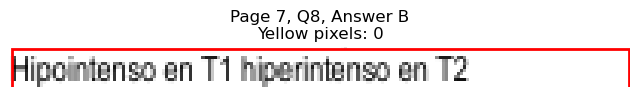

Page 7, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=248.4, y1=657.5
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 842
Page 7, Q8, C: Yellow percentage: 0.0%


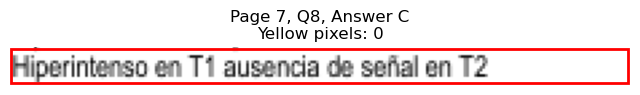

Page 7, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=503.6, y1=632.3
Page 7, Q8, D: Yellow pixels: 213
Page 7, Q8, D: Total non-white pixels: 1035
Page 7, Q8, D: Yellow percentage: 20.6%


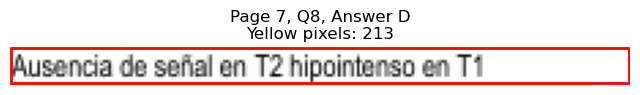

Page 7, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=480.1, y1=644.9
Page 7, Q8, E: Yellow pixels: 2096
Page 7, Q8, E: Total non-white pixels: 2652
Page 7, Q8, E: Yellow percentage: 79.0%


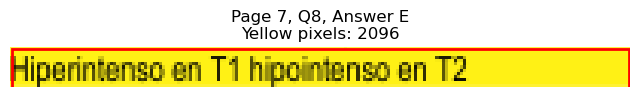


Page 7, Q8 - Selected Answer: E (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=88.8, y1=720.6
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 87
Page 7, Q9, A: Yellow percentage: 0.0%


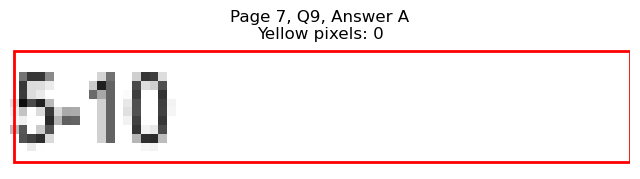

Page 7, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=93.9, y1=733.2
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 103
Page 7, Q9, B: Yellow percentage: 0.0%


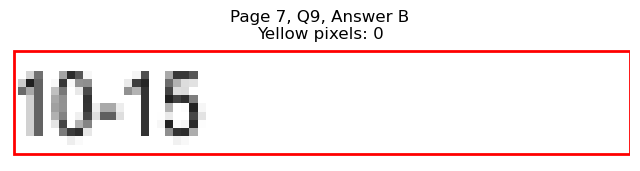

Page 7, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=94.3, y1=745.8
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 135
Page 7, Q9, C: Yellow percentage: 0.0%


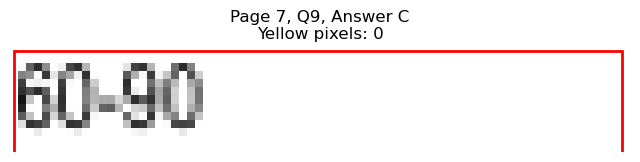

Page 7, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=358.1, y1=720.6
Page 7, Q9, D: Yellow pixels: 82
Page 7, Q9, D: Total non-white pixels: 225
Page 7, Q9, D: Yellow percentage: 36.4%


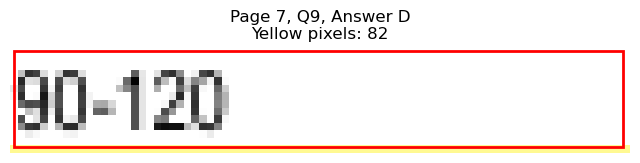

Page 7, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=350.2, y1=733.2
Page 7, Q9, E: Yellow pixels: 865
Page 7, Q9, E: Total non-white pixels: 1036
Page 7, Q9, E: Yellow percentage: 83.5%


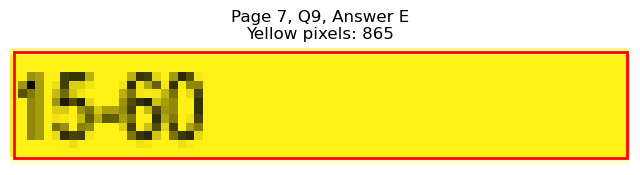


Page 7, Q9 - Selected Answer: E (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=103.3, y1=102.1
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 162
Page 8, Q1, A: Yellow percentage: 0.0%


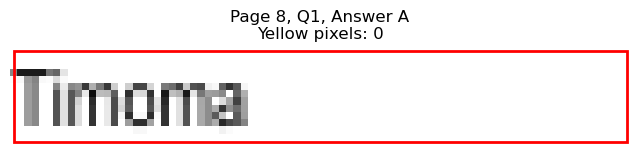

Page 8, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=102.9, y1=114.7
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 250
Page 8, Q1, B: Yellow percentage: 0.0%


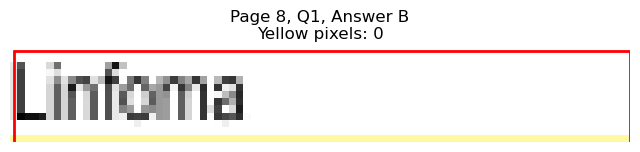

Page 8, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=115.5, y1=127.3
Page 8, Q1, C: Yellow pixels: 979
Page 8, Q1, C: Total non-white pixels: 1372
Page 8, Q1, C: Yellow percentage: 71.4%


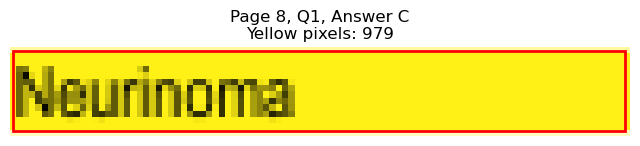

Page 8, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=402.8, y1=102.1
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 390
Page 8, Q1, D: Yellow percentage: 0.0%


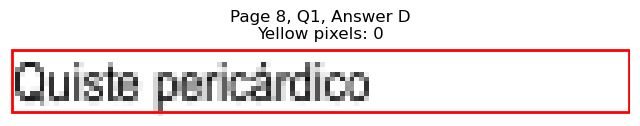

Page 8, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=368.2, y1=114.7
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 204
Page 8, Q1, E: Yellow percentage: 0.0%


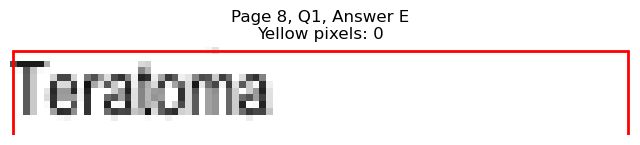


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=148.6, y1=165.2
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 407
Page 8, Q2, A: Yellow percentage: 0.0%


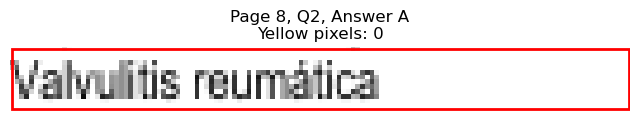

Page 8, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=222.3, y1=177.8
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 792
Page 8, Q2, B: Yellow percentage: 0.0%


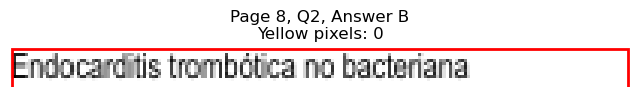

Page 8, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=193.7, y1=190.4
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 656
Page 8, Q2, C: Yellow percentage: 0.0%


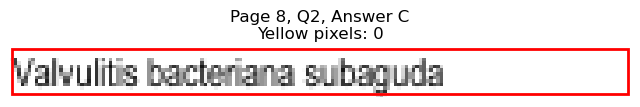

Page 8, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=457.0, y1=165.2
Page 8, Q2, D: Yellow pixels: 1883
Page 8, Q2, D: Total non-white pixels: 2534
Page 8, Q2, D: Yellow percentage: 74.3%


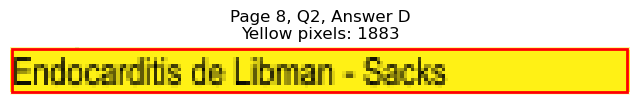

Page 8, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=451.5, y1=177.8
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 844
Page 8, Q2, E: Yellow percentage: 0.0%


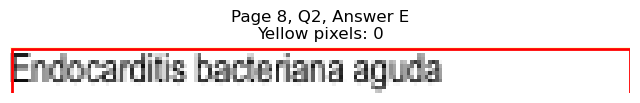


Page 8, Q2 - Selected Answer: D (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=518.7, y1=228.3
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 2188
Page 8, Q3, A: Yellow percentage: 0.0%


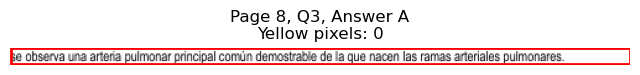

Page 8, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=437.9, y1=240.9
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 1752
Page 8, Q3, B: Yellow percentage: 0.0%


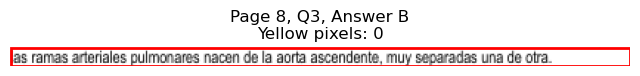

Page 8, Q3 - C: Detected box: x0=68.8, y0=240.9, x1=418.3, y1=253.5
Page 8, Q3, C: Yellow pixels: 401
Page 8, Q3, C: Total non-white pixels: 2093
Page 8, Q3, C: Yellow percentage: 19.2%


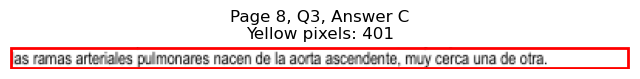

Page 8, Q3 - D: Detected box: x0=68.8, y0=253.5, x1=443.5, y1=266.1
Page 8, Q3, D: Yellow pixels: 4191
Page 8, Q3, D: Total non-white pixels: 5964
Page 8, Q3, D: Yellow percentage: 70.3%


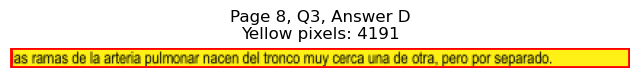

Page 8, Q3 - E: Detected box: x0=68.3, y0=266.1, x1=469.5, y1=278.7
Page 8, Q3, E: Yellow pixels: 0
Page 8, Q3, E: Total non-white pixels: 2368
Page 8, Q3, E: Yellow percentage: 0.0%


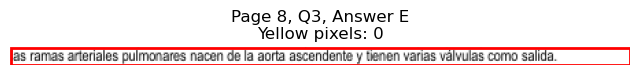


Page 8, Q3 - Selected Answer: D (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=248.9, y1=316.7
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 896
Page 8, Q4, A: Yellow percentage: 0.0%


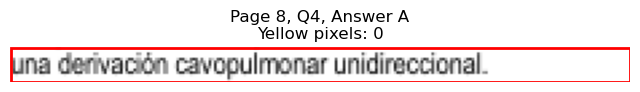

Page 8, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=243.9, y1=329.3
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 875
Page 8, Q4, B: Yellow percentage: 0.0%


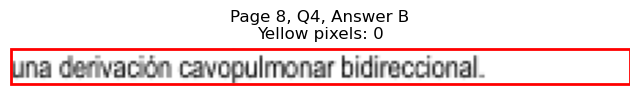

Page 8, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=270.4, y1=341.9
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 934
Page 8, Q4, C: Yellow percentage: 0.0%


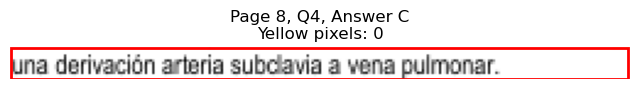

Page 8, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=518.6, y1=316.7
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 1104
Page 8, Q4, D: Yellow percentage: 0.0%


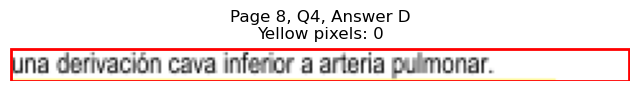

Page 8, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=534.7, y1=329.3
Page 8, Q4, E: Yellow pixels: 1774
Page 8, Q4, E: Total non-white pixels: 2996
Page 8, Q4, E: Yellow percentage: 59.2%


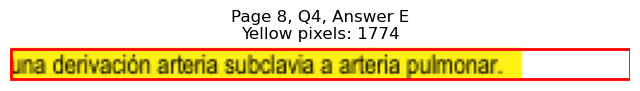


Page 8, Q4 - Selected Answer: E (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=297.8, y1=379.8
Page 8, Q5, A: Yellow pixels: 2829
Page 8, Q5, A: Total non-white pixels: 3640
Page 8, Q5, A: Yellow percentage: 77.7%


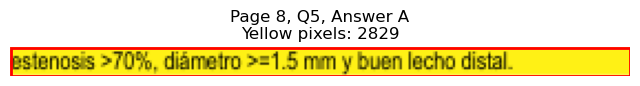

Page 8, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=214.5, y1=392.4
Page 8, Q5, B: Yellow pixels: 197
Page 8, Q5, B: Total non-white pixels: 916
Page 8, Q5, B: Yellow percentage: 21.5%


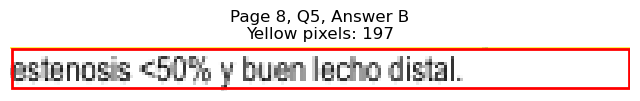

Page 8, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=222.3, y1=405.0
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 750
Page 8, Q5, C: Yellow percentage: 0.0%


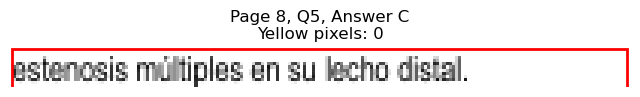

Page 8, Q5 - D: Detected box: x0=68.8, y0=404.9, x1=139.2, y1=417.6
Page 8, Q5, D: Yellow pixels: 0
Page 8, Q5, D: Total non-white pixels: 315
Page 8, Q5, D: Yellow percentage: 0.0%


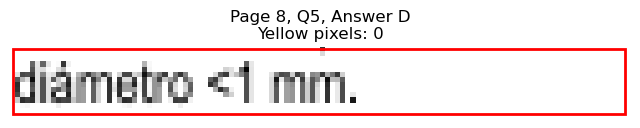

Page 8, Q5 - E: Detected box: x0=68.3, y0=417.6, x1=244.1, y1=430.3
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 866
Page 8, Q5, E: Yellow percentage: 0.0%


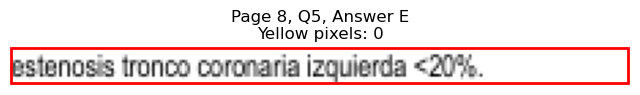


Page 8, Q5 - Selected Answer: A (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=185.7, y1=493.4
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 557
Page 8, Q6, A: Yellow percentage: 0.0%


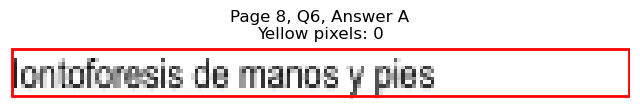

Page 8, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=266.0, y1=506.0
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 977
Page 8, Q6, B: Yellow percentage: 0.0%


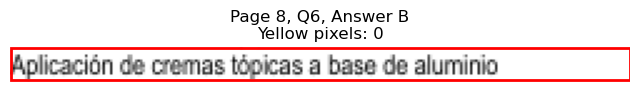

Page 8, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=199.1, y1=518.6
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 651
Page 8, Q6, C: Yellow percentage: 0.0%


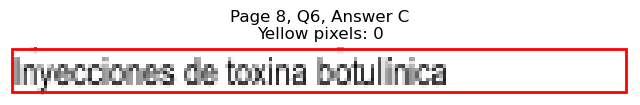

Page 8, Q6 - D: Detected box: x0=68.8, y0=518.6, x1=361.6, y1=531.2
Page 8, Q6, D: Yellow pixels: 344
Page 8, Q6, D: Total non-white pixels: 1840
Page 8, Q6, D: Yellow percentage: 18.7%


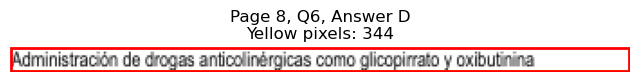

Page 8, Q6 - E: Detected box: x0=68.3, y0=531.2, x1=269.9, y1=543.8
Page 8, Q6, E: Yellow pixels: 2454
Page 8, Q6, E: Total non-white pixels: 3276
Page 8, Q6, E: Yellow percentage: 74.9%


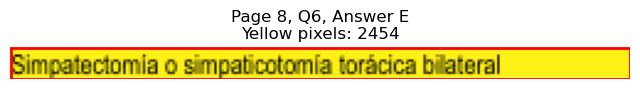


Page 8, Q6 - Selected Answer: E (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=192.7, y1=581.8
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 624
Page 8, Q7, A: Yellow percentage: 0.0%


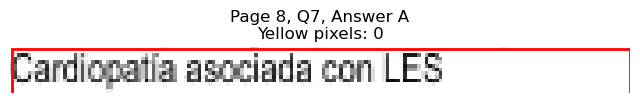

Page 8, Q7 - B: Detected box: x0=68.3, y0=165.1, x1=222.3, y1=177.8
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 792
Page 8, Q7, B: Yellow percentage: 0.0%


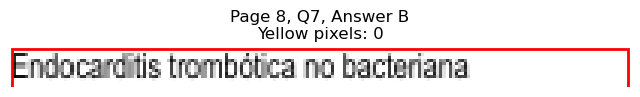

Page 8, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=161.5, y1=607.0
Page 8, Q7, C: Yellow pixels: 1497
Page 8, Q7, C: Total non-white pixels: 1872
Page 8, Q7, C: Yellow percentage: 80.0%


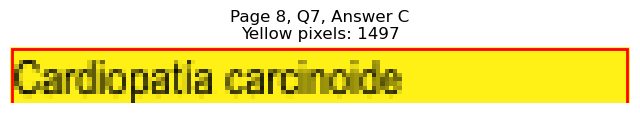

Page 8, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=452.0, y1=581.8
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 626
Page 8, Q7, D: Yellow percentage: 0.0%


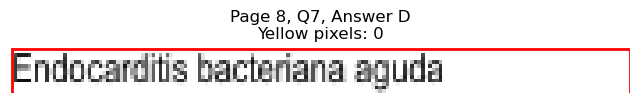

Page 8, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=391.7, y1=594.4
Page 8, Q7, E: Yellow pixels: 0
Page 8, Q7, E: Total non-white pixels: 336
Page 8, Q7, E: Yellow percentage: 0.0%


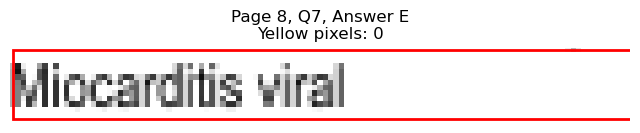


Page 8, Q7 - Selected Answer: C (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=106.9, y1=644.9
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 186
Page 8, Q8, A: Yellow percentage: 0.0%


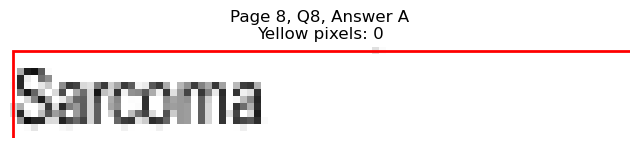

Page 8, Q8 - B: Detected box: x0=68.3, y0=102.0, x1=102.9, y1=114.7
Page 8, Q8, B: Yellow pixels: 0
Page 8, Q8, B: Total non-white pixels: 250
Page 8, Q8, B: Yellow percentage: 0.0%


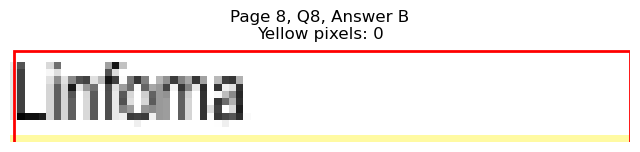

Page 8, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=109.9, y1=670.1
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 194
Page 8, Q8, C: Yellow percentage: 0.0%


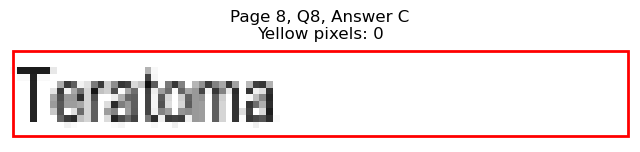

Page 8, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=361.6, y1=644.9
Page 8, Q8, D: Yellow pixels: 965
Page 8, Q8, D: Total non-white pixels: 1105
Page 8, Q8, D: Yellow percentage: 87.3%


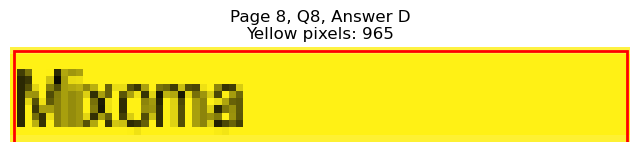

Page 8, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=359.2, y1=657.5
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 158
Page 8, Q8, E: Yellow percentage: 0.0%


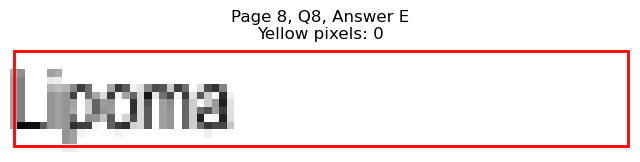


Page 8, Q8 - Selected Answer: D (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=171.1, y1=708.0
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 532
Page 8, Q9, A: Yellow percentage: 0.0%


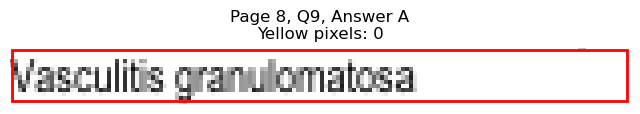

Page 8, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=160.6, y1=720.6
Page 8, Q9, B: Yellow pixels: 143
Page 8, Q9, B: Total non-white pixels: 602
Page 8, Q9, B: Yellow percentage: 23.8%


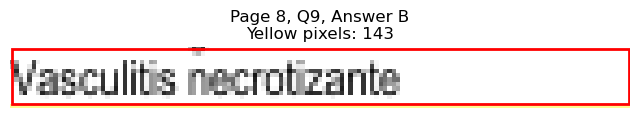

Page 8, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=181.6, y1=733.2
Page 8, Q9, C: Yellow pixels: 1622
Page 8, Q9, C: Total non-white pixels: 2296
Page 8, Q9, C: Yellow percentage: 70.6%


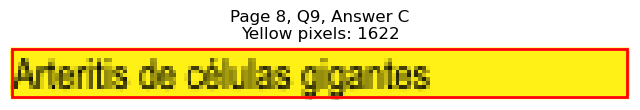

Page 8, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=436.4, y1=708.0
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 581
Page 8, Q9, D: Yellow percentage: 0.0%


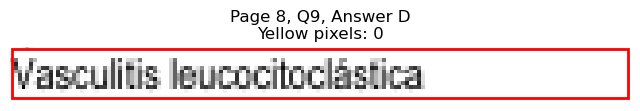

Page 8, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=433.9, y1=720.6
Page 8, Q9, E: Yellow pixels: 0
Page 8, Q9, E: Total non-white pixels: 573
Page 8, Q9, E: Yellow percentage: 0.0%


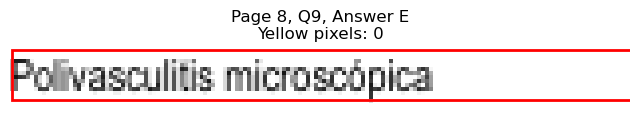


Page 8, Q9 - Selected Answer: C (based on yellow pixel count)





Page 9: Found 8 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=225.3, y1=114.7
Page 9, Q1, A: Yellow pixels: 2
Page 9, Q1, A: Total non-white pixels: 986
Page 9, Q1, A: Yellow percentage: 0.2%


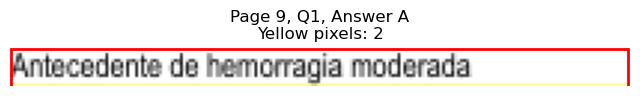

Page 9, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=208.2, y1=127.3
Page 9, Q1, B: Yellow pixels: 1764
Page 9, Q1, B: Total non-white pixels: 2674
Page 9, Q1, B: Yellow percentage: 66.0%


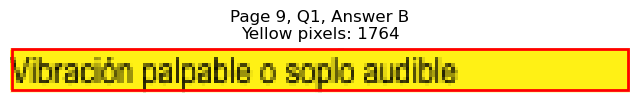

Page 9, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=188.2, y1=139.9
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 743
Page 9, Q1, C: Yellow percentage: 0.0%


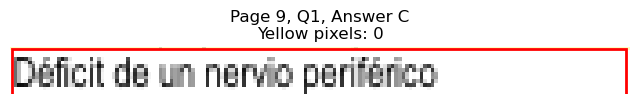

Page 9, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=446.9, y1=114.7
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 588
Page 9, Q1, D: Yellow percentage: 0.0%


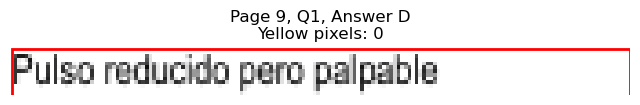

Page 9, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=396.3, y1=127.3
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 335
Page 9, Q1, E: Yellow percentage: 0.0%


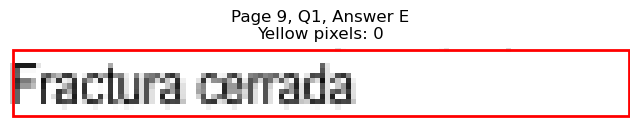


Page 9, Q1 - Selected Answer: B (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=333.2, y1=190.4
Page 9, Q2, A: Yellow pixels: 316
Page 9, Q2, A: Total non-white pixels: 1640
Page 9, Q2, A: Yellow percentage: 19.3%


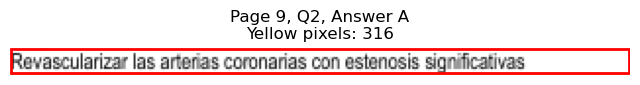

Page 9, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=343.3, y1=203.0
Page 9, Q2, B: Yellow pixels: 3224
Page 9, Q2, B: Total non-white pixels: 4238
Page 9, Q2, B: Yellow percentage: 76.1%


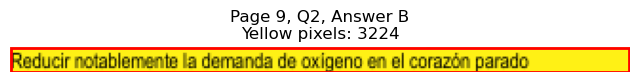

Page 9, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=258.8, y1=215.6
Page 9, Q2, C: Yellow pixels: 237
Page 9, Q2, C: Total non-white pixels: 1185
Page 9, Q2, C: Yellow percentage: 20.0%


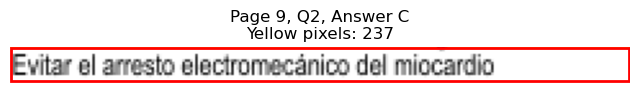

Page 9, Q2 - D: Detected box: x0=68.8, y0=215.7, x1=196.2, y1=228.3
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 613
Page 9, Q2, D: Yellow percentage: 0.0%


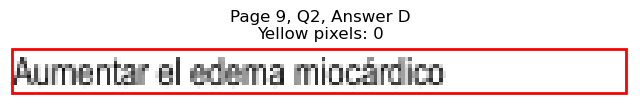

Page 9, Q2 - E: Detected box: x0=68.3, y0=228.3, x1=244.8, y1=240.9
Page 9, Q2, E: Yellow pixels: 0
Page 9, Q2, E: Total non-white pixels: 885
Page 9, Q2, E: Yellow percentage: 0.0%


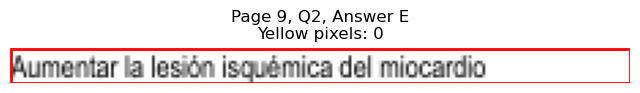


Page 9, Q2 - Selected Answer: B (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=183.6, y1=278.7
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 542
Page 9, Q3, A: Yellow percentage: 0.0%


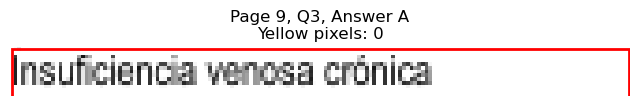

Page 9, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=112.9, y1=291.5
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 225
Page 9, Q3, B: Yellow percentage: 0.0%


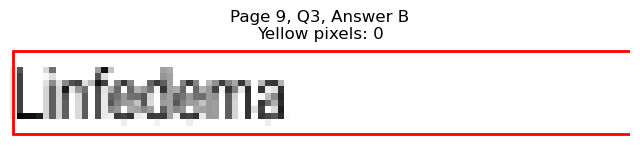

Page 9, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=190.1, y1=304.1
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 631
Page 9, Q3, C: Yellow percentage: 0.0%


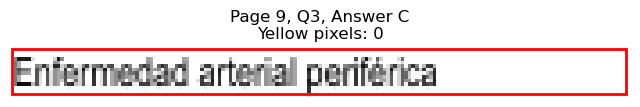

Page 9, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=413.3, y1=278.7
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 467
Page 9, Q3, D: Yellow percentage: 0.0%


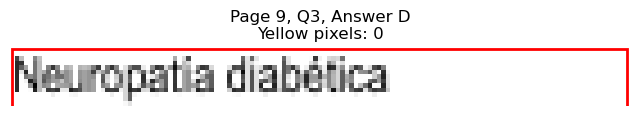

Page 9, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=441.4, y1=291.5
Page 9, Q3, E: Yellow pixels: 1716
Page 9, Q3, E: Total non-white pixels: 2310
Page 9, Q3, E: Yellow percentage: 74.3%


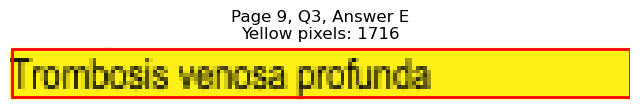


Page 9, Q3 - Selected Answer: E (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=269.4, y1=341.9
Page 9, Q4, A: Yellow pixels: 62
Page 9, Q4, A: Total non-white pixels: 1112
Page 9, Q4, A: Yellow percentage: 5.6%


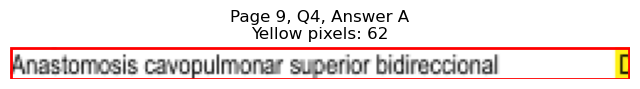

Page 9, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=259.4, y1=354.6
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 977
Page 9, Q4, B: Yellow percentage: 0.0%


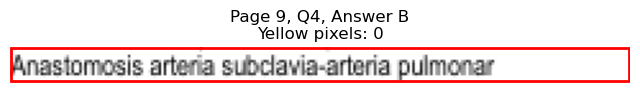

Page 9, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=272.8, y1=367.2
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 1018
Page 9, Q4, C: Yellow percentage: 0.0%


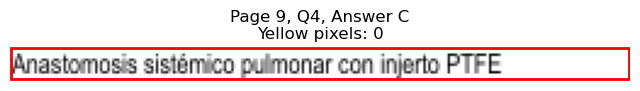

Page 9, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=533.7, y1=341.9
Page 9, Q4, D: Yellow pixels: 1956
Page 9, Q4, D: Total non-white pixels: 2782
Page 9, Q4, D: Yellow percentage: 70.3%


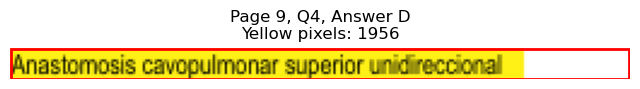

Page 9, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=501.6, y1=354.6
Page 9, Q4, E: Yellow pixels: 210
Page 9, Q4, E: Total non-white pixels: 1076
Page 9, Q4, E: Yellow percentage: 19.5%


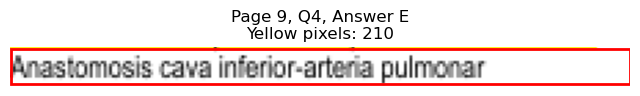


Page 9, Q4 - Selected Answer: D (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=125.5, y1=430.3
Page 9, Q5, A: Yellow pixels: 108
Page 9, Q5, A: Total non-white pixels: 382
Page 9, Q5, A: Yellow percentage: 28.3%


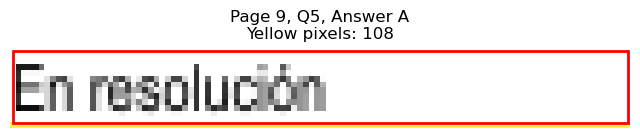

Page 9, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=103.9, y1=442.9
Page 9, Q5, B: Yellow pixels: 980
Page 9, Q5, B: Total non-white pixels: 1118
Page 9, Q5, B: Yellow percentage: 87.7%


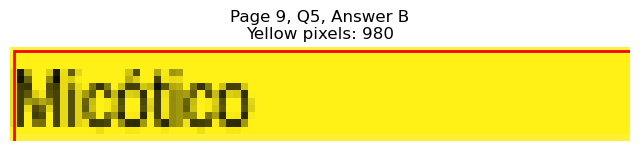

Page 9, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=113.4, y1=455.5
Page 9, Q5, C: Yellow pixels: 96
Page 9, Q5, C: Total non-white pixels: 324
Page 9, Q5, C: Yellow percentage: 29.6%


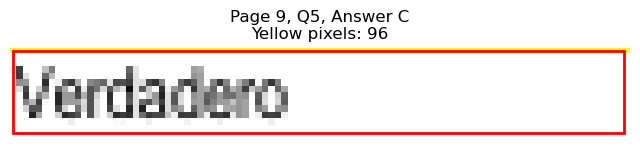

Page 9, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=394.7, y1=430.3
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 349
Page 9, Q5, D: Yellow percentage: 0.0%


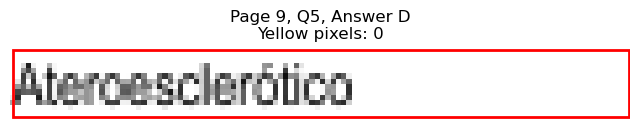

Page 9, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=376.7, y1=442.9
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 258
Page 9, Q5, E: Yellow percentage: 0.0%


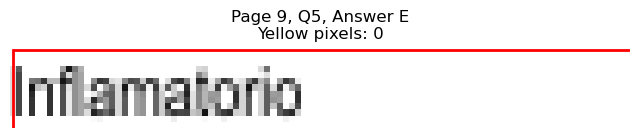


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=112.9, y1=518.6
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 242
Page 9, Q6, A: Yellow percentage: 0.0%


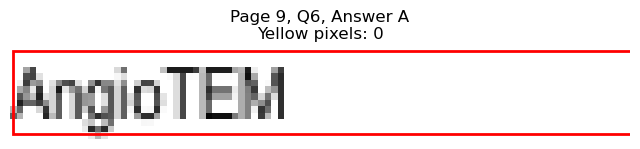

Page 9, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=141.0, y1=531.2
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 377
Page 9, Q6, B: Yellow percentage: 0.0%


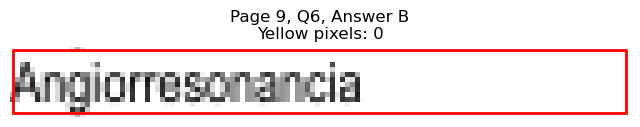

Page 9, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=121.0, y1=543.8
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 276
Page 9, Q6, C: Yellow percentage: 0.0%


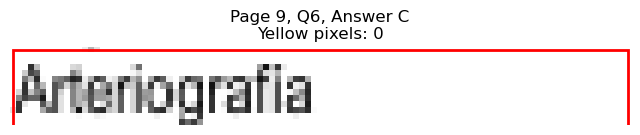

Page 9, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=375.7, y1=518.6
Page 9, Q6, D: Yellow pixels: 99
Page 9, Q6, D: Total non-white pixels: 357
Page 9, Q6, D: Yellow percentage: 27.7%


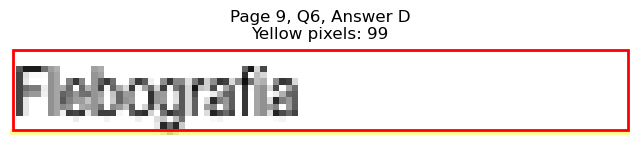

Page 9, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=405.3, y1=531.2
Page 9, Q6, E: Yellow pixels: 1373
Page 9, Q6, E: Total non-white pixels: 1806
Page 9, Q6, E: Yellow percentage: 76.0%


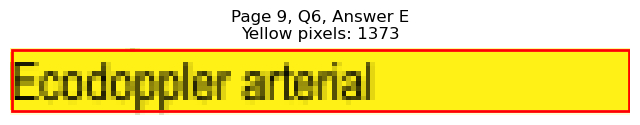


Page 9, Q6 - Selected Answer: E (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=594.3, x1=192.6, y1=607.0
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 660
Page 9, Q7, A: Yellow percentage: 0.0%


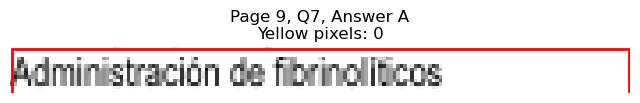

Page 9, Q7 - B: Detected box: x0=68.3, y0=606.9, x1=190.2, y1=619.6
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 633
Page 9, Q7, B: Yellow percentage: 0.0%


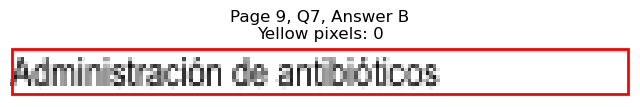

Page 9, Q7 - C: Detected box: x0=68.8, y0=619.6, x1=266.4, y1=632.3
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 966
Page 9, Q7, C: Yellow percentage: 0.0%


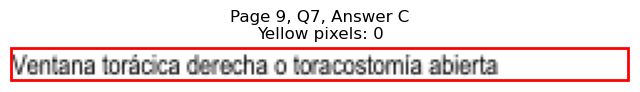

Page 9, Q7 - D: Detected box: x0=327.5, y0=594.3, x1=539.7, y1=607.0
Page 9, Q7, D: Yellow pixels: 1923
Page 9, Q7, D: Total non-white pixels: 2782
Page 9, Q7, D: Yellow percentage: 69.1%


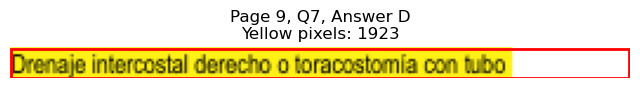

Page 9, Q7 - E: Detected box: x0=327.0, y0=606.9, x1=518.9, y1=619.6
Page 9, Q7, E: Yellow pixels: 211
Page 9, Q7, E: Total non-white pixels: 1142
Page 9, Q7, E: Yellow percentage: 18.5%


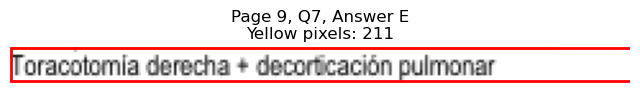


Page 9, Q7 - Selected Answer: D (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=682.7, x1=184.8, y1=695.3
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 588
Page 9, Q8, A: Yellow percentage: 0.0%


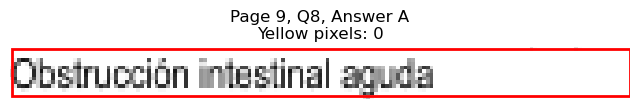

Page 9, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=145.7, y1=708.0
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 423
Page 9, Q8, B: Yellow percentage: 0.0%


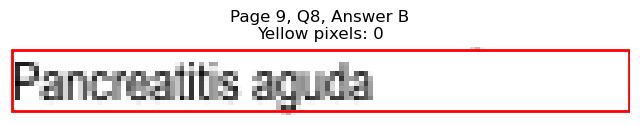

Page 9, Q8 - C: Detected box: x0=68.8, y0=708.0, x1=191.7, y1=720.6
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 625
Page 9, Q8, C: Yellow percentage: 0.0%


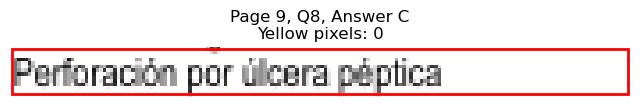

Page 9, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=446.0, y1=695.3
Page 9, Q8, D: Yellow pixels: 1572
Page 9, Q8, D: Total non-white pixels: 2366
Page 9, Q8, D: Yellow percentage: 66.4%


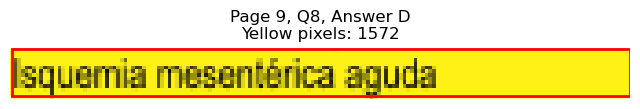

Page 9, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=427.4, y1=708.0
Page 9, Q8, E: Yellow pixels: 3
Page 9, Q8, E: Total non-white pixels: 671
Page 9, Q8, E: Yellow percentage: 0.4%


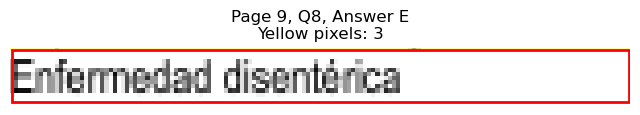


Page 9, Q8 - Selected Answer: D (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=227.4, y1=114.7
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 788
Page 10, Q1, A: Yellow percentage: 0.0%


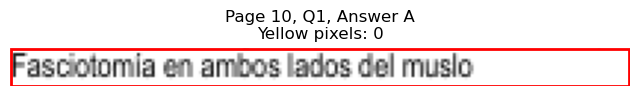

Page 10, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=249.5, y1=127.3
Page 10, Q1, B: Yellow pixels: 213
Page 10, Q1, B: Total non-white pixels: 1099
Page 10, Q1, B: Yellow percentage: 19.4%


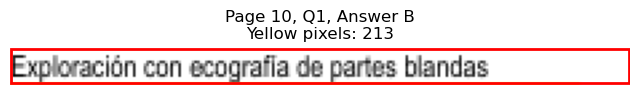

Page 10, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=225.4, y1=139.9
Page 10, Q1, C: Yellow pixels: 2088
Page 10, Q1, C: Total non-white pixels: 2704
Page 10, Q1, C: Yellow percentage: 77.2%


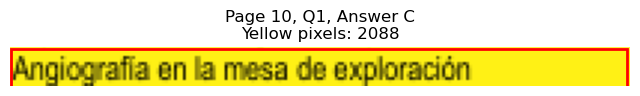

Page 10, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=434.9, y1=114.7
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 553
Page 10, Q1, D: Yellow percentage: 0.0%


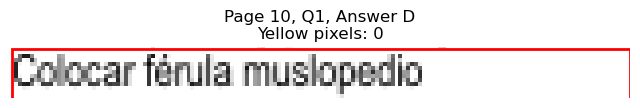

Page 10, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=507.7, y1=127.3
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 934
Page 10, Q1, E: Yellow percentage: 0.0%


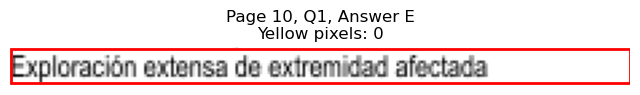


Page 10, Q1 - Selected Answer: C (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=235.8, y1=177.8
Page 10, Q2, A: Yellow pixels: 2
Page 10, Q2, A: Total non-white pixels: 1051
Page 10, Q2, A: Yellow percentage: 0.2%


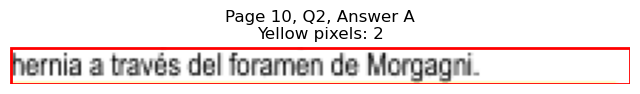

Page 10, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=240.4, y1=190.4
Page 10, Q2, B: Yellow pixels: 1924
Page 10, Q2, B: Total non-white pixels: 2996
Page 10, Q2, B: Yellow percentage: 64.2%


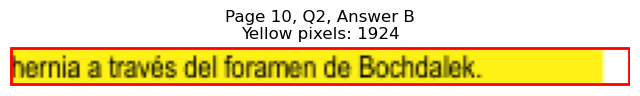

Page 10, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=182.2, y1=203.0
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 731
Page 10, Q2, C: Yellow percentage: 0.0%


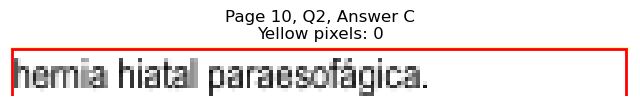

Page 10, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=435.9, y1=177.8
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 576
Page 10, Q2, D: Yellow percentage: 0.0%


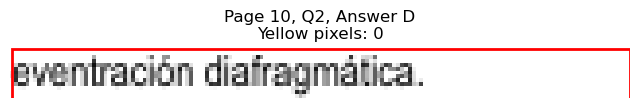

Page 10, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=442.4, y1=190.4
Page 10, Q2, E: Yellow pixels: 0
Page 10, Q2, E: Total non-white pixels: 584
Page 10, Q2, E: Yellow percentage: 0.0%


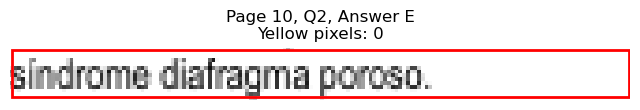


Page 10, Q2 - Selected Answer: B (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=516.2, y1=240.9
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 2252
Page 10, Q3, A: Yellow percentage: 0.0%


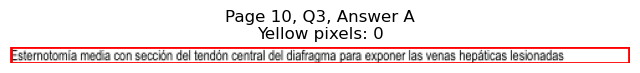

Page 10, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=428.6, y1=253.5
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 1800
Page 10, Q3, B: Yellow percentage: 0.0%


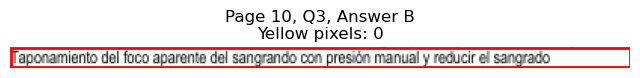

Page 10, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=404.8, y1=266.1
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 1649
Page 10, Q3, C: Yellow percentage: 0.0%


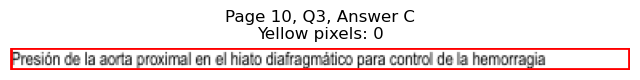

Page 10, Q3 - D: Detected box: x0=68.8, y0=266.1, x1=388.9, y1=278.7
Page 10, Q3, D: Yellow pixels: 0
Page 10, Q3, D: Total non-white pixels: 1610
Page 10, Q3, D: Yellow percentage: 0.0%


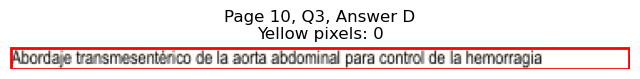

Page 10, Q3 - E: Detected box: x0=68.3, y0=278.8, x1=512.1, y1=291.5
Page 10, Q3, E: Yellow pixels: 4410
Page 10, Q3, E: Total non-white pixels: 6622
Page 10, Q3, E: Yellow percentage: 66.6%


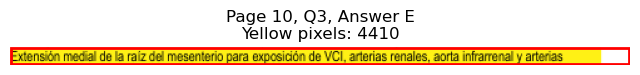


Page 10, Q3 - Selected Answer: E (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=93.9, y1=367.2
Page 10, Q4, A: Yellow pixels: 907
Page 10, Q4, A: Total non-white pixels: 1064
Page 10, Q4, A: Yellow percentage: 85.2%


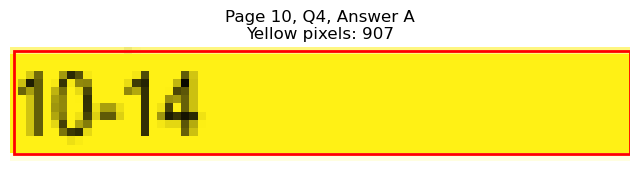

Page 10, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=83.9, y1=379.8
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 129
Page 10, Q4, B: Yellow percentage: 0.0%


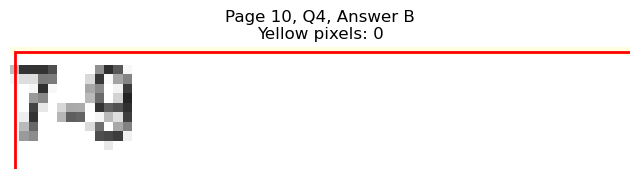

Page 10, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=84.4, y1=392.4
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 68
Page 10, Q4, C: Yellow percentage: 0.0%


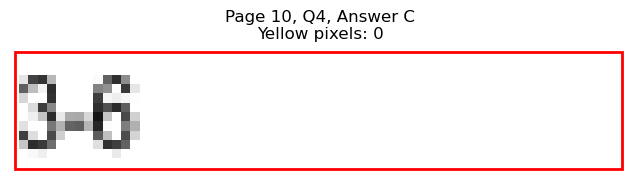

Page 10, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=343.1, y1=367.2
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 47
Page 10, Q4, D: Yellow percentage: 0.0%


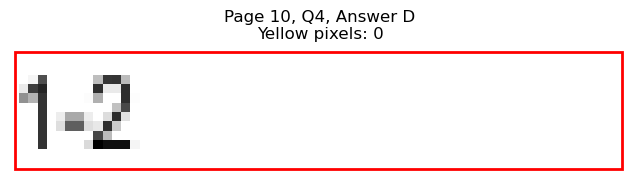

Page 10, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=352.6, y1=379.8
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 113
Page 10, Q4, E: Yellow percentage: 0.0%


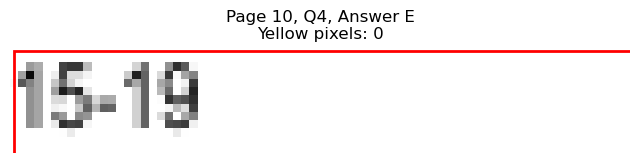


Page 10, Q4 - Selected Answer: A (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=181.6, y1=430.3
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 534
Page 10, Q5, A: Yellow percentage: 0.0%


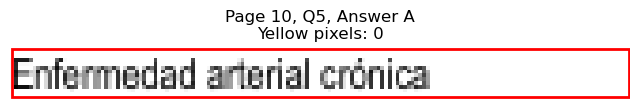

Page 10, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=155.1, y1=442.9
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 453
Page 10, Q5, B: Yellow percentage: 0.0%


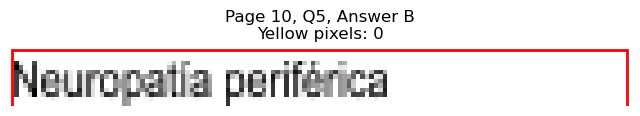

Page 10, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=183.1, y1=455.5
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 540
Page 10, Q5, C: Yellow percentage: 0.0%


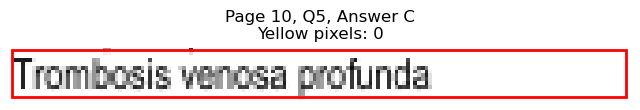

Page 10, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=372.2, y1=430.3
Page 10, Q5, D: Yellow pixels: 96
Page 10, Q5, D: Total non-white pixels: 306
Page 10, Q5, D: Yellow percentage: 31.4%


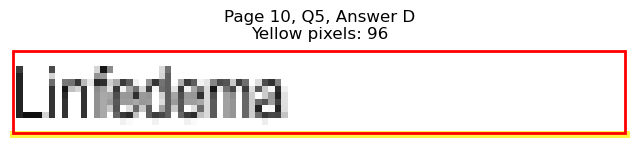

Page 10, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=442.4, y1=442.9
Page 10, Q5, E: Yellow pixels: 1737
Page 10, Q5, E: Total non-white pixels: 2158
Page 10, Q5, E: Yellow percentage: 80.5%


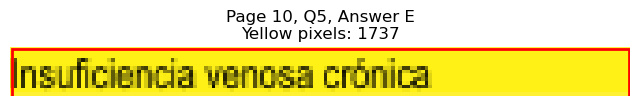


Page 10, Q5 - Selected Answer: E (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=136.7, y0=480.8, x1=388.0, y1=493.4
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 1160
Page 10, Q6, A: Yellow percentage: 0.0%


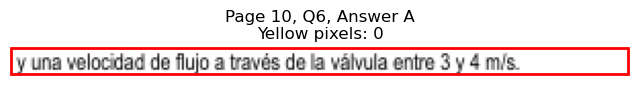

Page 10, Q6 - B: Detected box: x0=103.9, y0=493.4, x1=360.3, y1=506.0
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 1154
Page 10, Q6, B: Yellow percentage: 0.0%


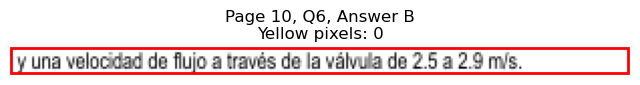

Page 10, Q6 - C: Detected box: x0=104.4, y0=506.0, x1=296.2, y1=518.6
Page 10, Q6, C: Yellow pixels: 243
Page 10, Q6, C: Total non-white pixels: 1123
Page 10, Q6, C: Yellow percentage: 21.6%


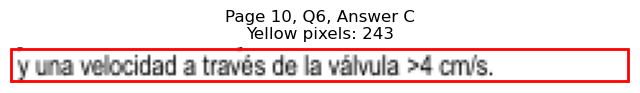

Page 10, Q6 - D: Detected box: x0=104.4, y0=518.6, x1=323.3, y1=531.2
Page 10, Q6, D: Yellow pixels: 2700
Page 10, Q6, D: Total non-white pixels: 3780
Page 10, Q6, D: Yellow percentage: 71.4%


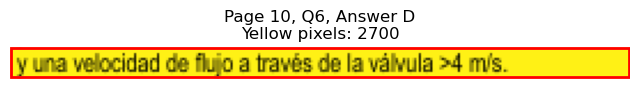

Page 10, Q6 - E: Detected box: x0=103.9, y0=531.2, x1=291.2, y1=543.8
Page 10, Q6, E: Yellow pixels: 0
Page 10, Q6, E: Total non-white pixels: 1073
Page 10, Q6, E: Yellow percentage: 0.0%


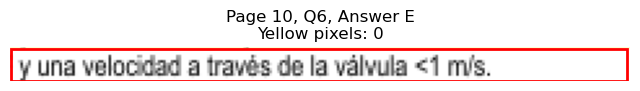


Page 10, Q6 - Selected Answer: D (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=229.7, y1=581.8
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 771
Page 10, Q7, A: Yellow percentage: 0.0%


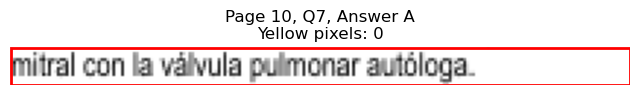

Page 10, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=246.4, y1=594.4
Page 10, Q7, B: Yellow pixels: 213
Page 10, Q7, B: Total non-white pixels: 1083
Page 10, Q7, B: Yellow percentage: 19.7%


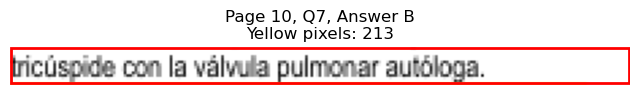

Page 10, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=235.2, y1=607.0
Page 10, Q7, C: Yellow pixels: 2147
Page 10, Q7, C: Total non-white pixels: 2782
Page 10, Q7, C: Yellow percentage: 77.2%


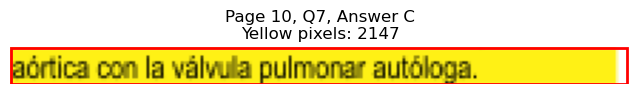

Page 10, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=452.9, y1=581.8
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 624
Page 10, Q7, D: Yellow percentage: 0.0%


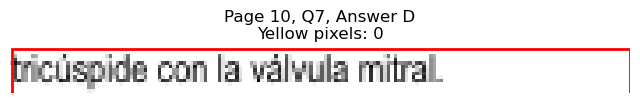

Page 10, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=493.7, y1=594.4
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 830
Page 10, Q7, E: Yellow percentage: 0.0%


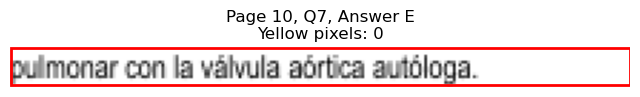


Page 10, Q7 - Selected Answer: C (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=657.5, x1=159.0, y1=670.1
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 453
Page 10, Q8, A: Yellow percentage: 0.0%


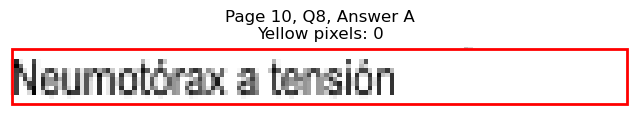

Page 10, Q8 - B: Detected box: x0=68.3, y0=670.1, x1=148.6, y1=682.7
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 414
Page 10, Q8, B: Yellow percentage: 0.0%


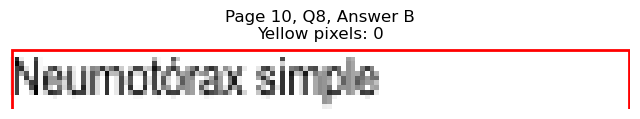

Page 10, Q8 - C: Detected box: x0=68.8, y0=682.7, x1=134.4, y1=695.3
Page 10, Q8, C: Yellow pixels: 0
Page 10, Q8, C: Total non-white pixels: 324
Page 10, Q8, C: Yellow percentage: 0.0%


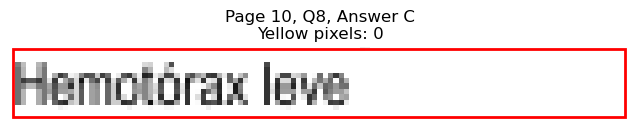

Page 10, Q8 - D: Detected box: x0=327.5, y0=657.5, x1=424.9, y1=670.1
Page 10, Q8, D: Yellow pixels: 1546
Page 10, Q8, D: Total non-white pixels: 2072
Page 10, Q8, D: Yellow percentage: 74.6%


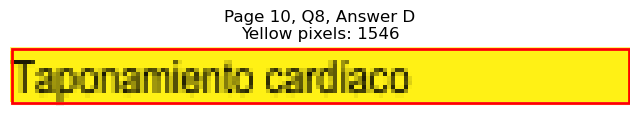

Page 10, Q8 - E: Detected box: x0=327.0, y0=670.1, x1=390.8, y1=682.7
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 446
Page 10, Q8, E: Yellow percentage: 0.0%


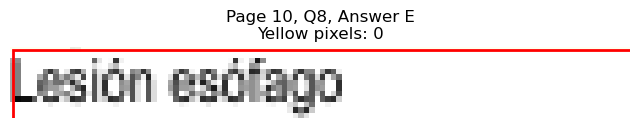


Page 10, Q8 - Selected Answer: D (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=183.6, y1=733.2
Page 10, Q9, A: Yellow pixels: 166
Page 10, Q9, A: Total non-white pixels: 706
Page 10, Q9, A: Yellow percentage: 23.5%


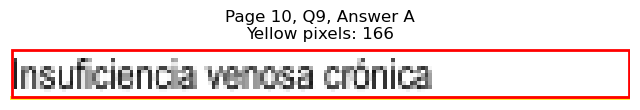

Page 10, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=189.6, y1=745.8
Page 10, Q9, B: Yellow pixels: 1746
Page 10, Q9, B: Total non-white pixels: 2236
Page 10, Q9, B: Yellow percentage: 78.1%


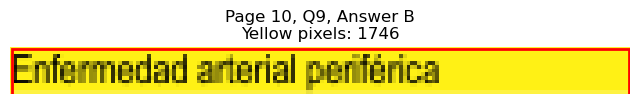

Page 10, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=113.4, y1=758.4
Page 10, Q9, C: Yellow pixels: 96
Page 10, Q9, C: Total non-white pixels: 319
Page 10, Q9, C: Yellow percentage: 30.1%


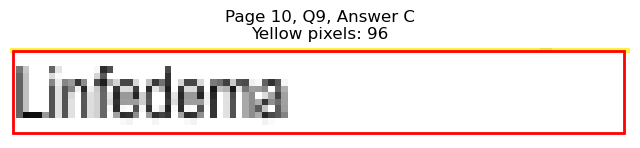

Page 10, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=413.3, y1=733.2
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 467
Page 10, Q9, D: Yellow percentage: 0.0%


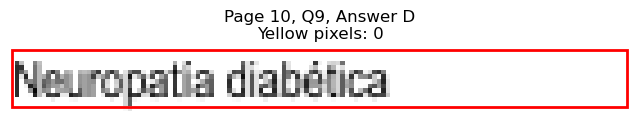

Page 10, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=439.0, y1=745.8
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 570
Page 10, Q9, E: Yellow percentage: 0.0%


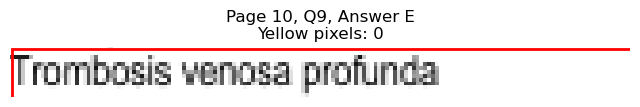


Page 10, Q9 - Selected Answer: B (based on yellow pixel count)





Page 11: Found 9 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=209.7, y1=102.1
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 690
Page 11, Q1, A: Yellow percentage: 0.0%


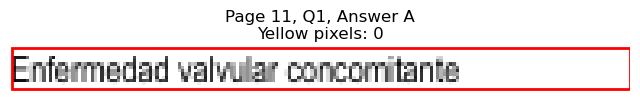

Page 11, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=178.1, y1=114.7
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 543
Page 11, Q1, B: Yellow percentage: 0.0%


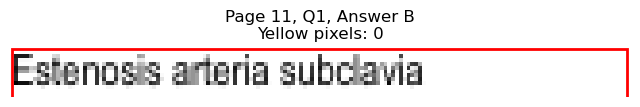

Page 11, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=248.8, y1=127.3
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 941
Page 11, Q1, C: Yellow percentage: 0.0%


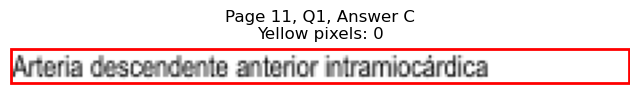

Page 11, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=509.6, y1=102.1
Page 11, Q1, D: Yellow pixels: 2046
Page 11, Q1, D: Total non-white pixels: 2995
Page 11, Q1, D: Yellow percentage: 68.3%


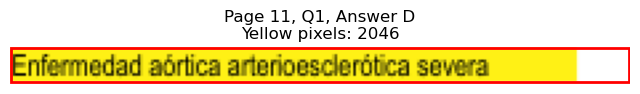

Page 11, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=540.2, y1=114.7
Page 11, Q1, E: Yellow pixels: 0
Page 11, Q1, E: Total non-white pixels: 1270
Page 11, Q1, E: Yellow percentage: 0.0%


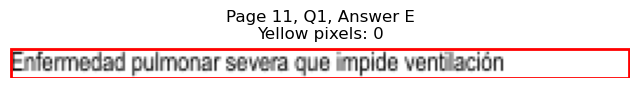


Page 11, Q1 - Selected Answer: D (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=225.8, y1=165.2
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 801
Page 11, Q2, A: Yellow percentage: 0.0%


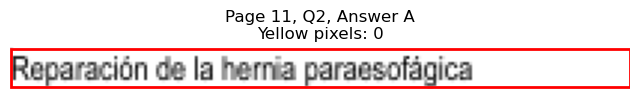

Page 11, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=224.8, y1=177.8
Page 11, Q2, B: Yellow pixels: 0
Page 11, Q2, B: Total non-white pixels: 1011
Page 11, Q2, B: Yellow percentage: 0.0%


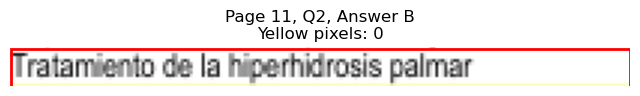

Page 11, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=246.9, y1=190.4
Page 11, Q2, C: Yellow pixels: 1857
Page 11, Q2, C: Total non-white pixels: 2996
Page 11, Q2, C: Yellow percentage: 62.0%


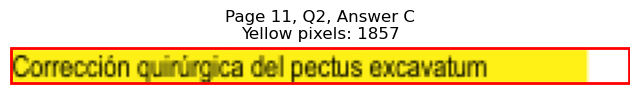

Page 11, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=435.9, y1=165.2
Page 11, Q2, D: Yellow pixels: 0
Page 11, Q2, D: Total non-white pixels: 545
Page 11, Q2, D: Yellow percentage: 0.0%


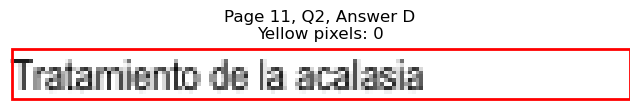

Page 11, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=461.9, y1=177.8
Page 11, Q2, E: Yellow pixels: 0
Page 11, Q2, E: Total non-white pixels: 705
Page 11, Q2, E: Yellow percentage: 0.0%


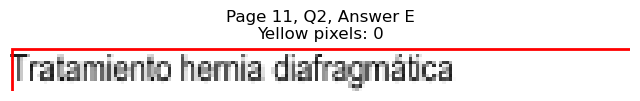


Page 11, Q2 - Selected Answer: C (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=181.7, y1=228.3
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 524
Page 11, Q3, A: Yellow percentage: 0.0%


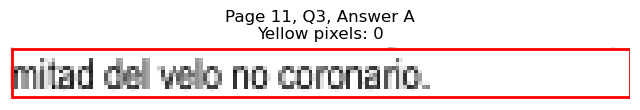

Page 11, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=292.5, y1=240.9
Page 11, Q3, B: Yellow pixels: 0
Page 11, Q3, B: Total non-white pixels: 1304
Page 11, Q3, B: Yellow percentage: 0.0%


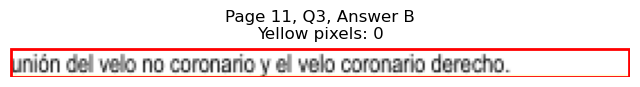

Page 11, Q3 - C: Detected box: x0=68.8, y0=240.9, x1=296.9, y1=253.5
Page 11, Q3, C: Yellow pixels: 2828
Page 11, Q3, C: Total non-white pixels: 3906
Page 11, Q3, C: Yellow percentage: 72.4%


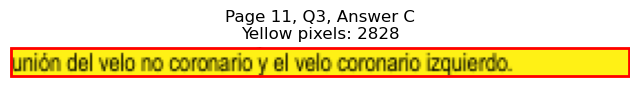

Page 11, Q3 - D: Detected box: x0=68.8, y0=253.5, x1=208.7, y1=266.1
Page 11, Q3, D: Yellow pixels: 190
Page 11, Q3, D: Total non-white pixels: 838
Page 11, Q3, D: Yellow percentage: 22.7%


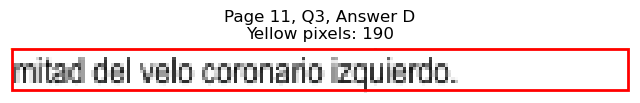

Page 11, Q3 - E: Detected box: x0=68.3, y0=266.1, x1=204.3, y1=278.7
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 666
Page 11, Q3, E: Yellow percentage: 0.0%


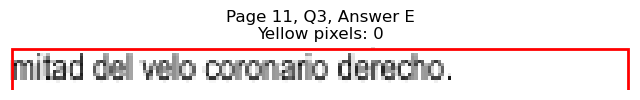


Page 11, Q3 - Selected Answer: C (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=140.1, y1=354.6
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 398
Page 11, Q4, A: Yellow percentage: 0.0%


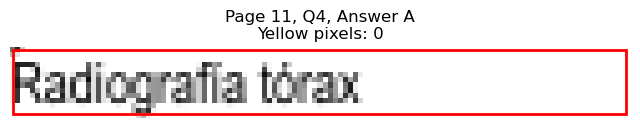

Page 11, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=124.9, y1=367.2
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 276
Page 11, Q4, B: Yellow percentage: 0.0%


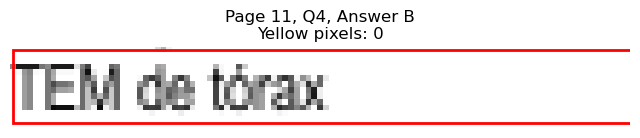

Page 11, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=191.2, y1=379.8
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 622
Page 11, Q4, C: Yellow percentage: 0.0%


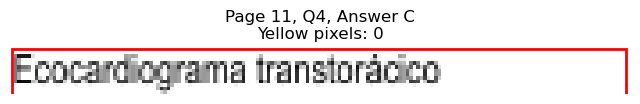

Page 11, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=465.4, y1=354.6
Page 11, Q4, D: Yellow pixels: 1914
Page 11, Q4, D: Total non-white pixels: 2646
Page 11, Q4, D: Yellow percentage: 72.3%


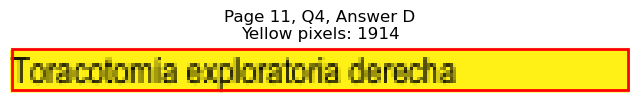

Page 11, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=404.3, y1=367.2
Page 11, Q4, E: Yellow pixels: 128
Page 11, Q4, E: Total non-white pixels: 500
Page 11, Q4, E: Yellow percentage: 25.6%


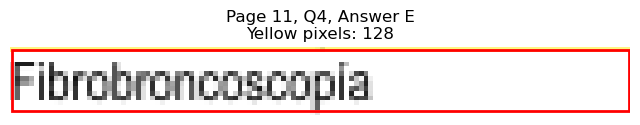


Page 11, Q4 - Selected Answer: D (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=99.4, y1=430.3
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 161
Page 11, Q5, A: Yellow percentage: 0.0%


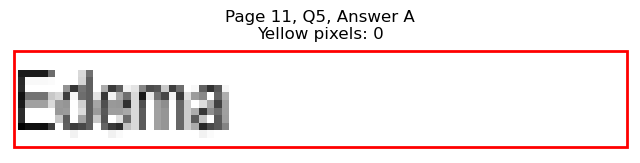

Page 11, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=135.0, y1=442.9
Page 11, Q5, B: Yellow pixels: 0
Page 11, Q5, B: Total non-white pixels: 313
Page 11, Q5, B: Yellow percentage: 0.0%


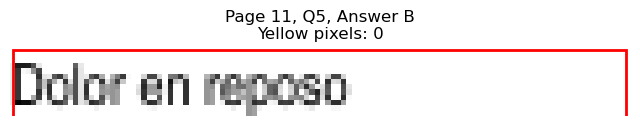

Page 11, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=185.7, y1=455.5
Page 11, Q5, C: Yellow pixels: 0
Page 11, Q5, C: Total non-white pixels: 540
Page 11, Q5, C: Yellow percentage: 0.0%


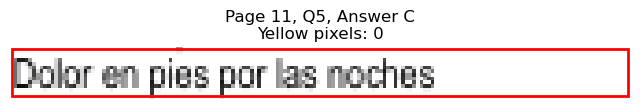

Page 11, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=431.3, y1=430.3
Page 11, Q5, D: Yellow pixels: 1431
Page 11, Q5, D: Total non-white pixels: 2170
Page 11, Q5, D: Yellow percentage: 65.9%


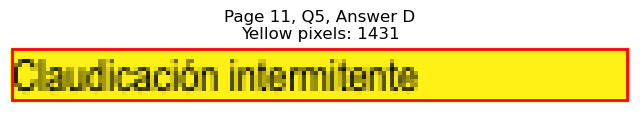

Page 11, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=392.8, y1=442.9
Page 11, Q5, E: Yellow pixels: 0
Page 11, Q5, E: Total non-white pixels: 446
Page 11, Q5, E: Yellow percentage: 0.0%


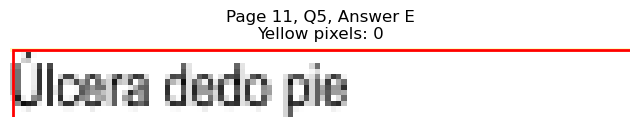


Page 11, Q5 - Selected Answer: D (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=139.6, y1=493.4
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 370
Page 11, Q6, A: Yellow percentage: 0.0%


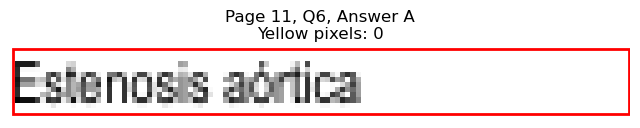

Page 11, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=134.5, y1=506.0
Page 11, Q6, B: Yellow pixels: 117
Page 11, Q6, B: Total non-white pixels: 573
Page 11, Q6, B: Yellow percentage: 20.4%


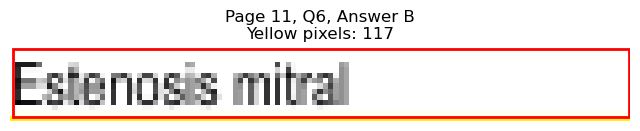

Page 11, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=234.4, y1=518.6
Page 11, Q6, C: Yellow pixels: 2103
Page 11, Q6, C: Total non-white pixels: 2996
Page 11, Q6, C: Yellow percentage: 70.2%


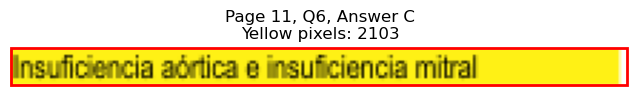

Page 11, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=419.3, y1=493.4
Page 11, Q6, D: Yellow pixels: 0
Page 11, Q6, D: Total non-white pixels: 452
Page 11, Q6, D: Yellow percentage: 0.0%


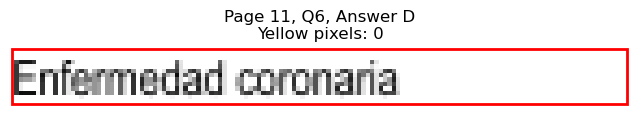

Page 11, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=442.4, y1=506.0
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 557
Page 11, Q6, E: Yellow percentage: 0.0%


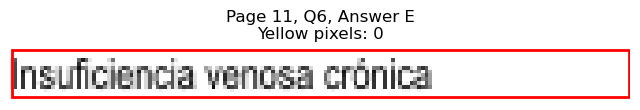


Page 11, Q6 - Selected Answer: C (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=150.5, y1=556.4
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 422
Page 11, Q7, A: Yellow percentage: 0.0%


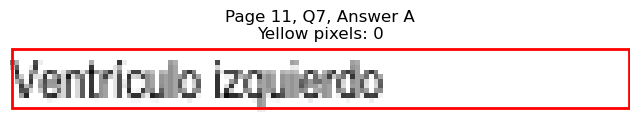

Page 11, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=146.5, y1=569.2
Page 11, Q7, B: Yellow pixels: 0
Page 11, Q7, B: Total non-white pixels: 393
Page 11, Q7, B: Yellow percentage: 0.0%


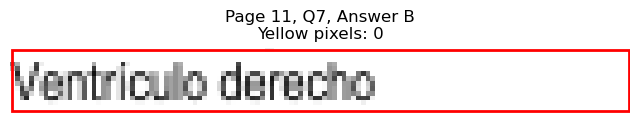

Page 11, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=165.6, y1=581.8
Page 11, Q7, C: Yellow pixels: 0
Page 11, Q7, C: Total non-white pixels: 474
Page 11, Q7, C: Yellow percentage: 0.0%


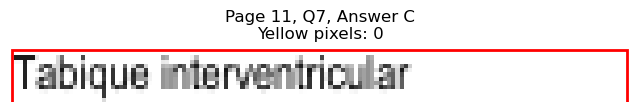

Page 11, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=370.6, y1=556.4
Page 11, Q7, D: Yellow pixels: 0
Page 11, Q7, D: Total non-white pixels: 216
Page 11, Q7, D: Yellow percentage: 0.0%


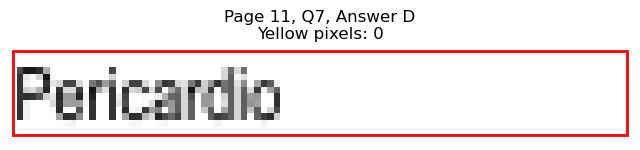

Page 11, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=401.8, y1=569.2
Page 11, Q7, E: Yellow pixels: 1314
Page 11, Q7, E: Total non-white pixels: 1750
Page 11, Q7, E: Yellow percentage: 75.1%


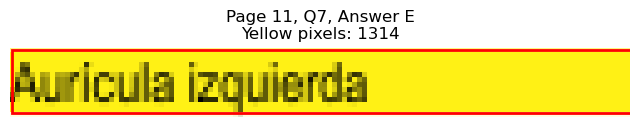


Page 11, Q7 - Selected Answer: E (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=128.5, y1=619.6
Page 11, Q8, A: Yellow pixels: 0
Page 11, Q8, A: Total non-white pixels: 251
Page 11, Q8, A: Yellow percentage: 0.0%


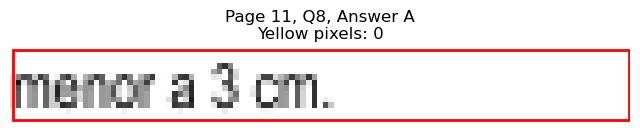

Page 11, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=138.0, y1=632.3
Page 11, Q8, B: Yellow pixels: 0
Page 11, Q8, B: Total non-white pixels: 291
Page 11, Q8, B: Yellow percentage: 0.0%


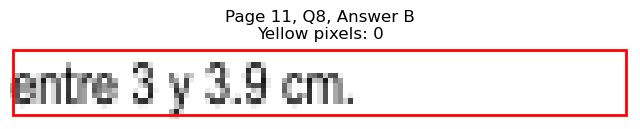

Page 11, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=138.5, y1=644.9
Page 11, Q8, C: Yellow pixels: 0
Page 11, Q8, C: Total non-white pixels: 298
Page 11, Q8, C: Yellow percentage: 0.0%


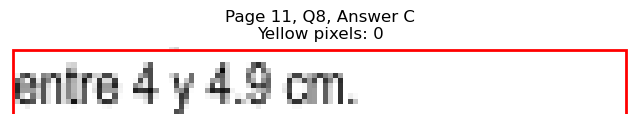

Page 11, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=423.8, y1=619.6
Page 11, Q8, D: Yellow pixels: 1599
Page 11, Q8, D: Total non-white pixels: 2058
Page 11, Q8, D: Yellow percentage: 77.7%


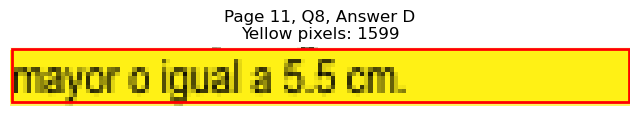

Page 11, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=396.8, y1=632.3
Page 11, Q8, E: Yellow pixels: 118
Page 11, Q8, E: Total non-white pixels: 415
Page 11, Q8, E: Yellow percentage: 28.4%


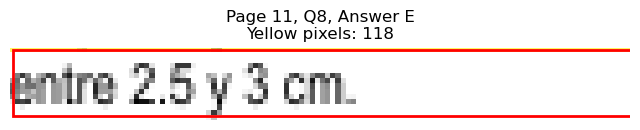


Page 11, Q8 - Selected Answer: D (based on yellow pixel count)




Page 11, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=207.8, y1=695.3
Page 11, Q9, A: Yellow pixels: 0
Page 11, Q9, A: Total non-white pixels: 670
Page 11, Q9, A: Yellow percentage: 0.0%


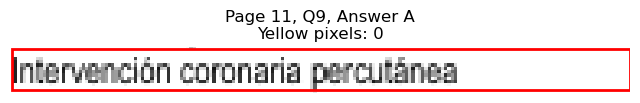

Page 11, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=159.1, y1=708.0
Page 11, Q9, B: Yellow pixels: 0
Page 11, Q9, B: Total non-white pixels: 446
Page 11, Q9, B: Yellow percentage: 0.0%


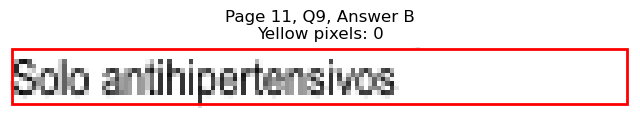

Page 11, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=174.1, y1=720.6
Page 11, Q9, C: Yellow pixels: 0
Page 11, Q9, C: Total non-white pixels: 554
Page 11, Q9, C: Yellow percentage: 0.0%


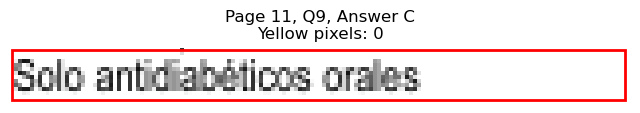

Page 11, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=531.7, y1=695.3
Page 11, Q9, D: Yellow pixels: 0
Page 11, Q9, D: Total non-white pixels: 1047
Page 11, Q9, D: Yellow percentage: 0.0%


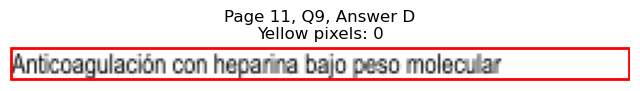

Page 11, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=483.6, y1=708.0
Page 11, Q9, E: Yellow pixels: 2096
Page 11, Q9, E: Total non-white pixels: 2694
Page 11, Q9, E: Yellow percentage: 77.8%


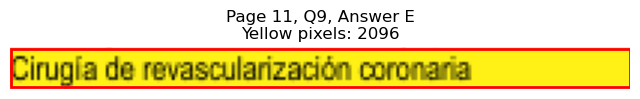


Page 11, Q9 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,En la revascularización coronaria quirúrgica e...
1,¿Cuál es una indicación de revascularización c...
2,La cirugía de Palma consiste en...
3,"Varón de 33 años, hace media hora presenta her..."
4,En un RN con CIV extensa que cursa con insufic...
...,...
95,En la enfermedad arterial periférica de miembr...
96,El síndrome de Marfan se asocia con:
97,¿Cuál es la localización más frecuente del mix...
98,El aneurisma de aorta abdominal infrarrenal as...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,vena safena mayor.,arteria radial.,arteria mamaria interna izquierda.,vena safena menor.,arteria gastroepiploica.
1,Angina estable en tratamiento,Estenosis <50% de la coronaria izquierda,ICC con miocardio inviable,Oclusión coronaria aguda sin ICP,Shock cardiogénico
2,la derivación arterial fémoro-femoral.,la derivación venosa fémoro-femoral con injerto,la derivación venosa fémoro poplítea.,la derivación arterial fémoro poplítea.,la derivación venosa fémoro tibial.
3,Ecodoppler arterial carotídeo,Angiotem cuello,Arteriografía carotídea,Angiorresonancia cuello,Exploración vascular quirúrgica del cuello
4,En el período neonatal,A los 2 meses,A los 30 días,En la etapa pre escolar,Al año
...,...,...,...,...,...
95,Edema,Dolor en reposo,Dolor en pies por las noches,Claudicación intermitente,Úlcera dedo pie
96,Estenosis aórtica,Estenosis mitral,Insuficiencia aórtica e insuficiencia mitral,Enfermedad coronaria,Insuficiencia venosa crónica
97,Ventrículo izquierdo,Ventrículo derecho,Tabique interventricular,Pericardio,Aurícula izquierda
98,menor a 3 cm.,entre 3 y 3.9 cm.,entre 4 y 4.9 cm.,mayor o igual a 5.5 cm.,entre 2.5 y 3 cm.


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,En la revascularización coronaria quirúrgica e...,vena safena mayor.,arteria radial.,arteria mamaria interna izquierda.,vena safena menor.,arteria gastroepiploica.,C
1,¿Cuál es una indicación de revascularización c...,Angina estable en tratamiento,Estenosis <50% de la coronaria izquierda,ICC con miocardio inviable,Oclusión coronaria aguda sin ICP,Shock cardiogénico,E
2,La cirugía de Palma consiste en...,la derivación arterial fémoro-femoral.,la derivación venosa fémoro-femoral con injerto,la derivación venosa fémoro poplítea.,la derivación arterial fémoro poplítea.,la derivación venosa fémoro tibial.,B
3,"Varón de 33 años, hace media hora presenta her...",Ecodoppler arterial carotídeo,Angiotem cuello,Arteriografía carotídea,Angiorresonancia cuello,Exploración vascular quirúrgica del cuello,E
4,En un RN con CIV extensa que cursa con insufic...,En el período neonatal,A los 2 meses,A los 30 días,En la etapa pre escolar,Al año,A
...,...,...,...,...,...,...,...
95,En la enfermedad arterial periférica de miembr...,Edema,Dolor en reposo,Dolor en pies por las noches,Claudicación intermitente,Úlcera dedo pie,D
96,El síndrome de Marfan se asocia con:,Estenosis aórtica,Estenosis mitral,Insuficiencia aórtica e insuficiencia mitral,Enfermedad coronaria,Insuficiencia venosa crónica,C
97,¿Cuál es la localización más frecuente del mix...,Ventrículo izquierdo,Ventrículo derecho,Tabique interventricular,Pericardio,Aurícula izquierda,E
98,El aneurisma de aorta abdominal infrarrenal as...,menor a 3 cm.,entre 3 y 3.9 cm.,entre 4 y 4.9 cm.,mayor o igual a 5.5 cm.,entre 2.5 y 3 cm.,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Cirugía Cardiovascular.csv
